# Vanguard / CMU: active positioning and performance

**Sponsor revision: 15 November 2026.** Run all cells from top to bottom. Place this notebook at the root of the GitHub repository, or run it by itself to download the pinned input snapshot. Edit the configuration cell to use another checkout or revision.

The presentation uses **Section 14** for the final model comparison and Vanguard case studies. Sections 1–13 build and audit the data, risk-factor attribution and persistence tests. Bloomberg yields provide an appendix sensitivity check. The main monthly yield source is the collected Federal Reserve zero-coupon Treasury curve.

The analysis is retrospective. Report-date positions may be used without a publication lag, as agreed. Beginning-quarter positions explain the following quarter's realized outcome. This does not test a publicly tradable strategy.

All three Vanguard funds stay in the analysis. Short histories receive descriptive comparisons and explicit uncertainty rather than forced skill labels. Corporate weights are not an investment-grade-only classification. Fees use a cheapest-class proxy until selected-class histories are supplied.


## 1. Configuration and reproducible setup

The pinned revision is a reproducibility default, not an automatic update mechanism. Set `repo_root` when the notebook cannot find your clone. Local repository inputs are read-only; generated outputs have a separate directory. The notebook uses a fixed seed and writes data hashes, package versions and all thresholds to a manifest.

In [1]:
ANALYSIS_CODE_SHA256 = 'cddf32ec33837cd846bd00a788ad199c1aa37e74db4cf98e4cb3195784319549'
LEGACY_ANALYSIS_CODE_SHA256 = '74def19621944fa11a2354ac462c218b8dd5ad46603fa695214fe6ed1fcc78b3'
from pathlib import Path
import sys, subprocess, importlib.util, os, json, io, hashlib, urllib.request, urllib.error
import datetime as dt, time, warnings, re, shutil, zipfile, html, platform

# Edit this cell only for a normal run. Local repository files take precedence.
CFG = {
    'repo_root': '',  # blank: find universe.csv above the notebook, otherwise use ./capstone_inputs
    'github_repo': 'dakshg01/vanguard-cmu-capstone',
    'github_ref': '42eea76799c4667a9e956f9ce513c4f4f45e3cb6',
    'download_missing_inputs': True,
    'download_market_data': True,
    'prefer_collected_fed_curve': True,
    'auto_install_missing_packages': True,
    'refresh_market_cache': False,
    'output_name': 'final_analysis_output',
    'seed': 20261114,
    'common_start': '2021-01-31', 'common_end': '2025-12-31',
    'max_benchmark_age_days': 100, 'max_position_age_days': 100,
    'max_unresolved_pct': 10.0,
    'min_model_months': 36, 'hac_lags': 3,
    'bootstrap_reps': 1000, 'bootstrap_block_months': 6,
    'fdr_threshold': 0.05,
    'annual_class_cagr_range_flag_pp': 3.0,
    'monthly_class_range_flag_pp': 0.5,
    'exclude_flagged_return_funds': True,
    'ml_folds': 5, 'ml_permutation_repeats': 8,
    'anonymize': False,  # True for an externally shared deck (Qiang's instruction)
}
required = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','matplotlib':'matplotlib',
            'sklearn':'scikit-learn','statsmodels':'statsmodels','IPython':'ipython'}
import importlib.metadata
minimum={'pandas':(2,2),'scikit-learn':(1,2),'numpy':(1,24)}
missing=[]
for mod,pkg in required.items():
    if importlib.util.find_spec(mod) is None:
        missing.append(pkg+('>='+'.'.join(map(str,minimum[pkg])) if pkg in minimum else ''))
    elif pkg in minimum:
        installed=tuple(int(x) for x in re.findall(r'\d+',importlib.metadata.version(pkg))[:2])
        if installed<minimum[pkg]:missing.append(pkg+'>='+'.'.join(map(str,minimum[pkg])))
if missing:
    if not CFG['auto_install_missing_packages']:
        raise ImportError('Install these packages and rerun: ' + ', '.join(missing))
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from threadpoolctl import threadpool_limits
warnings.filterwarnings('ignore', category=FutureWarning)
np.random.seed(CFG['seed'])
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':110,'savefig.dpi':190,
    'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold',
    'font.size':10,'axes.grid':True,'grid.alpha':0.16,'font.family':'DejaVu Sans'})
if CFG['repo_root']:
    ROOT = Path(CFG['repo_root']).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p/'universe.csv').exists()), Path.cwd()/'capstone_inputs')
ROOT.mkdir(parents=True,exist_ok=True)
OUT = ROOT/CFG['output_name']
for folder in ['tables','charts','inputs_optional','cache','audit']:
    (OUT/folder).mkdir(parents=True,exist_ok=True)
TABLES, CHARTS, AUDIT = OUT/'tables', OUT/'charts', OUT/'audit'
RUN_STARTED = dt.datetime.now(dt.timezone.utc).isoformat()
PROVENANCE, ISSUES, FIGURES, CHECKS = [], [], [], []
def note(s): display(Markdown(s))
def issue(code, detail, severity='limitation'):
    ISSUES.append(dict(code=code,severity=severity,detail=str(detail)))
def check(name, condition, detail=''):
    CHECKS.append(dict(check=name,passed=bool(condition),detail=str(detail)))
    if not condition: raise AssertionError(f'{name}: {detail}')
def save_table(df,name,audit=False):
    df.to_csv((AUDIT if audit else TABLES)/(name+'.csv'),index=False)
    return df
def savefig(name,caption):
    fig=plt.gcf(); fig.tight_layout()
    fig.savefig(CHARTS/(name+'.png'),bbox_inches='tight')
    fig.savefig(CHARTS/(name+'.svg'),bbox_inches='tight')
    FIGURES.append(dict(name=name,caption=caption))
    plt.show();plt.close(fig)
def get_bytes(url,timeout=40):
    req=urllib.request.Request(url,headers={'User-Agent':'CMU-capstone-research/1.0 (public data)'})
    with urllib.request.urlopen(req,timeout=timeout) as response: return response.read()
def record_file(path,source):
    b=Path(path).read_bytes()
    PROVENANCE.append(dict(path=str(Path(path).resolve()),source=source,bytes=len(b),
                           sha256=hashlib.sha256(b).hexdigest()))
def load_repo(path):
    local=ROOT/path
    source='local repository file'
    if not local.exists() or local.stat().st_size<10:
        if not CFG['download_missing_inputs']: raise FileNotFoundError(local)
        source=f"https://raw.githubusercontent.com/{CFG['github_repo']}/{CFG['github_ref']}/{path}"
        local.parent.mkdir(parents=True,exist_ok=True)
        local.write_bytes(get_bytes(source))
    record_file(local,source)
    return pd.read_csv(local,encoding='utf-8-sig',dtype={'series_id':str,'class_id':str})
def month_end(x): return pd.to_datetime(x).to_period('M').to_timestamp('M')
def as_month(s): return pd.to_datetime(s).dt.to_period('M').dt.to_timestamp('M')
def bh_adjust(p):
    p=np.asarray(p,float); out=np.full(len(p),np.nan); valid=np.flatnonzero(np.isfinite(p))
    if len(valid):
        ix=valid[np.argsort(p[valid])]; m=len(ix)
        out[ix]=np.minimum(1,np.minimum.accumulate((p[ix]*m/np.arange(1,m+1))[::-1])[::-1])
    return out
note(f'Working directory: `{ROOT}`. All generated results go to `{OUT.name}/`. Seed: {CFG["seed"]}.')


Working directory: `.`. All generated results go to `final_analysis_output/`. Seed: 20261114.

## 2. Inputs, metadata and optional verified overrides

The main sample is the repository's PRIMARY group. BENCHMARK funds supply sampled portfolios; ADJACENT and CHECK funds are not mixed into the main peer rankings. Optional CSV templates are created once and never overwritten. Keep a source on every override. Missing fields are not set to zero by default.

In [2]:
universe=load_repo('universe.csv')
fund=load_repo('output/csv/fund_quarter.csv')
raw_returns=load_repo('output/csv/monthly_returns_latest.csv')
sectors=load_repo('analysis/results/sector_weights.csv')
tenors=load_repo('analysis/results/rate_tenor_positions.csv')
fees=load_repo('sec_rr/sec_rr_fees_panel.csv')
credit=load_repo('fred_credit_monthly.csv')
bbg=load_repo('bbg_rates/bbg_rates_quarterly_wide.csv')
# Anna's additional cleaned inputs are packaged in data_new.zip in the current repository.
# Read named members without extracting or executing code from the archive.
def load_collected(member):
    local=ROOT/member
    if local.exists():
        record_file(local,'unpacked collected dataset');return pd.read_csv(local,dtype={'series_id':str})
    archive=ROOT/'data_new.zip'
    if not archive.exists() and CFG['download_missing_inputs']:
        url=f"https://raw.githubusercontent.com/{CFG['github_repo']}/{CFG['github_ref']}/data_new.zip"
        try:archive.write_bytes(get_bytes(url))
        except Exception as e:issue('collected_bundle',str(e));return pd.DataFrame()
    if not archive.exists():return pd.DataFrame()
    try:
        with zipfile.ZipFile(archive) as z:
            data=z.read(member)
        PROVENANCE.append(dict(path=str(archive)+'::'+member,source='collected data_new.zip member',bytes=len(data),sha256=hashlib.sha256(data).hexdigest()))
        return pd.read_csv(io.BytesIO(data),dtype={'series_id':str})
    except (KeyError,zipfile.BadZipFile) as e:
        issue('collected_member',f'{member}: {e}');return pd.DataFrame()
collected_fed=load_collected('cleaned_data/3_factors/fed_zero_curve_monthly.csv')
collected_signs=load_collected('cleaned_data/4_reference/risk_sign_check.csv')
collected_risk_flags=load_collected('cleaned_data/4_reference/risk_plausibility_screen.csv')
if len(collected_signs):save_table(collected_signs,'collected_return_implied_sign_crosscheck',True)
if len(collected_risk_flags):save_table(collected_risk_flags,'collected_risk_plausibility_flags',True)
issue('collected_data_choices','The archive contains median-across-class fund returns and full-history return-implied sign checks. We instead use a fixed outcome-blind reference class and re-estimate lagged sensitivities; median-class returns are not a real investable class and full-history loadings cannot be treated as prior information.')
meta=universe[['series_id','fund_name','manager','style','group','role']].copy()
check('unique universe',not meta.series_id.duplicated().any())
primary=meta[meta.group.eq('PRIMARY')].copy()
ids=primary.series_id.tolist()
names=meta.set_index('series_id').fund_name.to_dict()
labels={sid:(f'Fund {j+1:02d}' if CFG['anonymize'] else names[sid]) for j,sid in enumerate(sorted(names))}
def label(s): return labels.get(s,s)
for df,cols in [(fund,['report_date','report_month','filing_date']),
                (sectors,['report_date','report_month']), (tenors,['report_month']),
                (raw_returns,['report_date','month_end','filing_date']),
                (fees,['quarter_end']), (credit,['month_end'])]:
    for c in cols: df[c]=pd.to_datetime(df[c])
for c in ['sector_complete','cash_outside_holdings_missing']:
    sectors[c]=sectors[c].astype(str).str.lower().eq('true')
check('unique fund snapshots',not fund.duplicated(['series_id','report_date']).any())
check('unique sector snapshots',not sectors.duplicated(['series_id','report_date']).any())
SECTORS=['US Treasury (nominal)','TIPS (description identified)','Agency / other government',
    'Agency MBS','Non-agency MBS / CMBS','ABS / CLO','Corporate debt (ratings pending)',
    'Non-US sovereign (non-EM list)','Emerging markets (fixed country list)','Municipal',
    'Cash / short-term / repo','Derivatives (market value)','Other / unresolved']
SHORT=['Treasury','TIPS','Other government','Agency MBS','Non-agency/CMBS','ABS/CLO',
       'Corporate (unrated)','Foreign sovereign','EM','Municipal','Cash','Derivative MV','Unresolved']
SHORTMAP=dict(zip(SECTORS,SHORT))
PROXIES=['S000017334','S000004362','S000033156']
PROXY_NAMES=dict(zip(PROXIES,['SPAB','AGG','SCHZ']))
# Optional files are never overwritten. Add rows only after verifying the underlying source.
templates={
 'reference_classes.csv':['series_id','class_id','verified','source'],
 'risk_sign_overrides.csv':['series_id','multiplier','verified','source'],
 'class_fees.csv':['series_id','class_id','effective_date','net_exp','source'],
 'sector_overrides.csv':['series_id','report_date','from_sector','to_sector','weight_pp','source'],
 'benchmark_returns.csv':['month_end','return_decimal','source'],
 'monthly_factors.csv':['month_end','rate_level','rate_curve','credit_shock','mbs_excess','source'],
 'latest_issuer_ratings.csv':['series_id','asof_date','issuer_id','issuer_name','corporate_weight_pct','rating','source']}
for name,cols in templates.items():
    p=OUT/'inputs_optional'/name
    if not p.exists(): pd.DataFrame(columns=cols).to_csv(p,index=False)
def optional(name):
    p=OUT/'inputs_optional'/name
    d=pd.read_csv(p,dtype={'series_id':str,'class_id':str})
    if len(d): record_file(p,'user supplied verified override')
    return d
issue('sample_scope','Current supplied fund universe; not survivorship-free. Manager identifies firm, not a dated individual PM tenure.')
issue('holdings_classification','Existing sector classifications are reused with explicit audits and optional reviewed overrides; raw security-level classifications have not all been independently verified.')
coverage=fund.groupby('series_id').agg(first=('report_date','min'),last=('report_date','max'),snapshots=('report_date','size')).reset_index().merge(meta,on='series_id')
save_table(coverage,'coverage')
display(coverage.groupby('group').agg(funds=('series_id','size'),snapshots=('snapshots','sum'),first=('first','min'),last=('last','max')))
note('The notebook uses exported tables, so the 9 GB SQLite database is not required. Empty optional CSV templates are in `inputs_optional/`. Missing ratings remain unknown, not investment grade.')


,funds,snapshots,first,last
group,,,,
ADJACENT,4,111,2019-09-30,2026-07-31
BENCHMARK,4,111,2019-09-30,2026-06-30
CHECK,2,22,2023-12-31,2026-06-30
PRIMARY,49,1333,2019-09-30,2026-07-31


The notebook uses exported tables, so the 9 GB SQLite database is not required. Empty optional CSV templates are in `inputs_optional/`. Missing ratings remain unknown, not investment grade.

### Return-class audit

Source references and reconciliation checks remain in the code and audit tables. These are input-quality controls, not performance findings.

## 3. Return integrity, reference classes and expense matching

Exact duplicates can be collapsed; conflicting source returns are excluded and exported. The class-consistency screen compares annualized class differences and median monthly spreads over 2021–2025. A provisional reference class never switches silently. The existing fee panel is descriptive until class-specific matching is verified. N-PORT reported returns are treated as net-of-operating-expense returns, subject to the source/convention review.

In [3]:
# Reviewed class identities and published calendar-year returns, checked 14 Nov 2026.
# These are source-based class choices, not choices based on alpha or relative performance.
# Annual returns are percentage points, exactly as published to two decimals.
CLASS_REVIEW = [
 dict(series_id='S000007004',class_id='C000019120',ticker='FBNDX',class_name='Fidelity Investment Grade Bond Fund',
      annual_pct=[-0.89,-13.48,6.49,1.59,7.36],
      identity_source='https://www.sec.gov/Archives/edgar/data/35315/000003531526000484/0000035315-26-000484-index-headers.html',
      performance_source='https://fundresearch.fidelity.com/mutual-funds/performance-and-risk/316146109',
      decision='Retain original no-load reference class; Advisor classes caused cross-class flag'),
 dict(series_id='S000007066',class_id='C000019272',ticker='FTBFX',class_name='Fidelity Total Bond Fund',
      annual_pct=[-0.09,-12.91,7.23,2.49,7.49],
      identity_source='https://www.sec.gov/Archives/edgar/data/751199/000075119926000062/0000751199-26-000062-index.html',
      performance_source='https://fundresearch.fidelity.com/mutual-funds/performance-and-risk/31617K881',
      decision='Retain original no-load reference class; Advisor classes caused cross-class flag'),
 dict(series_id='S000003549',class_id='C000009863',ticker='BIBTX',class_name='Sterling Capital Total Return Bond Institutional',
      annual_pct=[-1.22,-13.24,5.86,2.15,6.92],
      identity_source='https://www.sec.gov/Archives/edgar/data/889284/000139834426006460/0001398344-26-006460-index-headers.html',
      performance_source='https://sterlingcapital.com/seismic/b80d8f15-df57-8e9d-8358-87370eb8d75a/96b7c32b-c8fb-4a30-8537-12865534711a/6496/',
      decision='Retain original Institutional reference class; A and C classes caused flag'),
 dict(series_id='S000055044',class_id='C000173087',ticker='DHRIX',class_name='Diamond Hill Core Bond Class I',
      annual_pct=[-0.99,-11.84,6.62,3.40,7.16],
      identity_source='https://www.sec.gov/Archives/edgar/data/1032423/000139834426003675/0001398344-26-003675-index.htm',
      performance_source='https://www.diamond-hill.com/investment-strategies/fixed-income/core-bond/mutual-fund/',
      decision='Use continuously observed Class I instead of anomalous Investor class; no class splicing'),
]
# Keep conflicting overlapping source returns out; collapse exact economic duplicates only.
rk=['series_id','class_id','month_end']
r=raw_returns.copy(); r['return_decimal']=pd.to_numeric(r.return_decimal,errors='coerce')
g=r.groupby(rk).return_decimal.agg(['min','max','count']).reset_index()
bad=g[(g['max']-g['min']).abs().gt(1e-8)]
save_table(r.merge(bad[rk],on=rk),'conflicting_return_rows',True)
r=r.merge(bad[rk].assign(conflict=True),on=rk,how='left')
r=r[~r.conflict.fillna(False)].sort_values(['filing_date','report_date']).drop_duplicates(rk,keep='last')
invalid=r.return_decimal.notna() & ((r.return_decimal<=-1)|(r.return_decimal.abs()>0.5))
save_table(r[invalid],'invalid_return_rows',True)
r.loc[invalid,'return_decimal']=np.nan
r=r.dropna(subset=['return_decimal'])
check('unique economic class-month returns',not r.duplicated(rk).any())
# Diamond Hill pre-2021 observations show return-unit inconsistencies and do not
# reconcile to published 2020 performance. Quarantine those observations, without
# guessing a scale correction. The complete 2021-2025 window is unaffected.
pre2021=r.series_id.eq('S000055044') & r.month_end.lt('2021-01-01')
save_table(r[pre2021].assign(review_reason='Pre-2021 return-unit inconsistency; not used; no synthetic correction'), 'quarantined_class_returns', True)
r=r[~pre2021].copy()

# Outcome-blind default: longest observed history, then earliest observation, then class ID.
class_stats=r.groupby(['series_id','class_id']).agg(n=('month_end','nunique'),first=('month_end','min'),last=('month_end','max')).reset_index()
choice=class_stats.sort_values(['series_id','n','first','class_id'],ascending=[True,False,True,True]).drop_duplicates('series_id').copy()
choice['verified']=False;choice['selection_basis']='longest history; earliest start; class ID tie-break; provisional'
# Prefer independently identified no-load classes where review evidence exists.
for evidence in CLASS_REVIEW:
    ix=choice.series_id.eq(evidence['series_id'])
    choice.loc[ix,'class_id']=evidence['class_id']
    choice.loc[ix,'verified']=True
    choice.loc[ix,'selection_basis']='Reviewed class identity: '+evidence['ticker']+'; '+evidence['identity_source']
ov=optional('reference_classes.csv')
if len(ov):
    check('one reference class override per fund',not ov.series_id.duplicated().any())
    for row in ov.itertuples():
        check('reference class exists',((r.series_id==row.series_id)&(r.class_id==row.class_id)).any(),row.series_id)
        ix=choice.series_id.eq(row.series_id)
        choice.loc[ix,'class_id']=row.class_id
        choice.loc[ix,'verified']=str(row.verified).lower()=='true'
        choice.loc[ix,'selection_basis']='override: '+str(row.source)
# Consistency screen at a fixed common window, preserving every flagged fund in the audit.
window=r[r.month_end.between(CFG['common_start'],CFG['common_end'])].copy()
cr=window.groupby(['series_id','class_id']).return_decimal.agg(n='size',growth=lambda v:np.prod(1+v)).reset_index()
cr=cr[cr.n.eq(60)];cr['cagr']=cr.growth**(12/cr.n)-1
range_cagr=cr.groupby('series_id').cagr.agg(lambda v:100*(v.max()-v.min())).rename('class_cagr_range_pp')
spread=window.groupby(['series_id','month_end']).return_decimal.agg(lambda v:100*(v.max()-v.min())).groupby('series_id').median().rename('median_class_range_pp')
review=primary.merge(range_cagr,on='series_id',how='left').merge(spread,on='series_id',how='left')
review['return_review']=review.class_cagr_range_pp.gt(CFG['annual_class_cagr_range_flag_pp'])|review.median_class_range_pp.gt(CFG['monthly_class_range_flag_pp'])
# Keep the raw screening flag. A validated selected class can resolve a fund-level
# exclusion while anomalous alternative classes remain quarantined by selection.
review['raw_return_review']=review.return_review
reconciliation=[]
for evidence in CLASS_REVIEW:
    sid,cid=evidence['series_id'],evidence['class_id']
    for year,published in zip(range(2021,2026),evidence['annual_pct']):
        x=r[(r.series_id==sid)&(r.class_id==cid)&r.month_end.dt.year.eq(year)]
        v=x.return_decimal.to_numpy()
        actual=100*(np.prod(1+v)-1) if len(v) else np.nan
        # Conservative exact compounding interval for monthly values rounded to
        # 0.01 percentage point and the published annual return rounded to 0.01pp.
        lo=100*(np.prod(1+v-0.00005)-1)-0.005 if len(v) else np.nan
        hi=100*(np.prod(1+v+0.00005)-1)+0.005 if len(v) else np.nan
        passed=len(x)==12 and x.month_end.nunique()==12 and lo<=published<=hi
        reconciliation.append(dict(series_id=sid,class_id=cid,ticker=evidence['ticker'],year=year,
            n_months=len(x),computed_annual_pct=actual,published_annual_pct=published,
            difference_bp=(actual-published)*100,rounding_lower_pct=lo,rounding_upper_pct=hi,
            passed=passed,performance_source=evidence['performance_source'],checked_on='2026-11-14'))
reconciliation=pd.DataFrame(reconciliation)
save_table(reconciliation,'reviewed_class_annual_reconciliation',True)
resolution=[]
for evidence in CLASS_REVIEW:
    sid,cid=evidence['series_id'],evidence['class_id']
    selected=choice[choice.series_id.eq(sid)]
    passed=reconciliation[reconciliation.series_id.eq(sid)].passed.all()
    matching=len(selected)==1 and selected.iloc[0].class_id==cid and bool(selected.iloc[0].verified)
    resolved=bool(passed and matching)
    resolution.append({k:v for k,v in evidence.items() if k!='annual_pct'}|dict(resolved=resolved,
        scope='Class identity and five calendar-year aggregate reconciliation; not independent monthly validation'))
    if resolved:review.loc[review.series_id.eq(sid),'return_review']=False
resolution=pd.DataFrame(resolution)
save_table(resolution,'reviewed_class_resolution',True)
review=review.merge(resolution[['series_id','ticker','resolved']],on='series_id',how='left')
review['resolved']=review.resolved.fillna(False)
save_table(review,'share_class_consistency',True)
issue('reviewed_reference_classes','Four classes have independently checked identities and 2021-2025 annual reconciliation. Raw cross-class flags are preserved. Annual reconciliation is not independent validation of each monthly return; load-adjusted alternative classes are not repaired or compounded. Diamond Hill pre-2021 data are quarantined.')
choice=choice.merge(review[['series_id','return_review']],on='series_id',how='left')
choice['return_review']=choice.return_review.fillna(False)
save_table(choice.merge(meta,on='series_id'),'reference_class_selection',True)
ret=r.merge(choice[['series_id','class_id','verified','return_review']],on=['series_id','class_id'],validate='many_to_one')
b=ret[ret.series_id.eq(PROXIES[0])][['month_end','return_decimal']].rename(columns={'return_decimal':'benchmark_return'})
BENCHMARK_LABEL='SPAB total return proxy for Bloomberg U.S. Aggregate'
bo=optional('benchmark_returns.csv')
if len(bo):
    bo['month_end']=as_month(bo.month_end)
    check('unique optional benchmark months',not bo.month_end.duplicated().any())
    b=bo[['month_end','return_decimal']].rename(columns={'return_decimal':'benchmark_return'})
    BENCHMARK_LABEL='User-supplied benchmark total return (see source column)'
check('unique benchmark returns',not b.month_end.duplicated().any())
returns=ret[ret.series_id.isin(ids)].merge(b,on='month_end',validate='many_to_one').merge(primary,on='series_id',validate='many_to_one')
returns['active_return']=returns.return_decimal-returns.benchmark_return
returns['eligible_returns']=~returns.return_review if CFG['exclude_flagged_return_funds'] else True
save_table(returns,'fund_month_returns')
R=returns[returns.eligible_returns].copy()
check('one return per fund-month',not R.duplicated(['series_id','month_end']).any())
# Expense levels here describe the cheapest investable class; not necessarily the selected class.
fees['fee_date']=fees.quarter_end
fee_panel=[]
for sid,x in returns.groupby('series_id'):
    f=fees[fees.series_id.eq(sid)][['fee_date','net_exp','turnover']].sort_values('fee_date')
    if len(f):
        z=pd.merge_asof(x.sort_values('month_end'),f,left_on='month_end',right_on='fee_date',direction='backward',tolerance=pd.Timedelta(days=370))
        fee_panel.append(z)
fee_panel=pd.concat(fee_panel,ignore_index=True)
save_table(fee_panel,'returns_and_descriptive_fees')
# Only matched class fees can support an approximate expense add-back.
class_fees=optional('class_fees.csv'); gross_rows=[]
if len(class_fees):
    class_fees['effective_date']=pd.to_datetime(class_fees.effective_date)
    check('class fee keys unique',not class_fees.duplicated(['series_id','class_id','effective_date']).any())
    for (sid,cid),x in R.groupby(['series_id','class_id']):
        f=class_fees[(class_fees.series_id==sid)&(class_fees.class_id==cid)].sort_values('effective_date')
        if not len(f):continue
        z=pd.merge_asof(x.sort_values('month_end'),f[['effective_date','net_exp']],left_on='month_end',right_on='effective_date',direction='backward',tolerance=pd.Timedelta(days=370))
        z['approx_before_expense_return']=z.return_decimal+z.net_exp/12
        gross_rows.append(z)
if gross_rows:save_table(pd.concat(gross_rows),'matched_class_expense_addback')
else:issue('fee_matching','No verified class-fee mapping supplied. Fees are descriptive; no gross-alpha or cost-driven skill classification is fabricated.')
issue('reference_classes',f'{int((~choice[choice.series_id.isin(ids)].verified).sum())} primary reference classes use outcome-blind provisional choices. All individual-fund conclusions remain provisional until checked.')
note(f'**{R.series_id.nunique()} funds** enter return analysis; **{review.raw_return_review.sum()} raw cross-class flags**, **{review.resolved.sum()} resolved with selected-class evidence**, **{review.return_review.sum()} unresolved exclusions**. Benchmark: {BENCHMARK_LABEL}.')
display(review[review.return_review][['fund_name','class_cagr_range_pp','median_class_range_pp']])


**49 funds** enter return analysis; **4 raw cross-class flags**, **4 resolved with selected-class evidence**, **0 unresolved exclusions**. Benchmark: SPAB total return proxy for Bloomberg U.S. Aggregate.

,fund_name,class_cagr_range_pp,median_class_range_pp


## 4. Net performance, complete years and stress episodes

Monthly active return is $r_f-r_b$. Annual active return is $\prod(1+r_f)-\prod(1+r_b)$. Cumulative relative wealth is $\prod(1+r_f)/\prod(1+r_b)-1$. Tracking error uses monthly active-return standard deviation times $\sqrt{12}$. Information ratio uses annualized arithmetic active return divided by tracking error. Only complete calendar years enter persistence; 2026 is not relabelled as a full year.

In [4]:
def performance(x):
    x=x.sort_values('month_end');n=len(x);a=x.active_return.to_numpy();rf=x.return_decimal.to_numpy();rb=x.benchmark_return.to_numpy()
    te=np.std(a,ddof=1)*np.sqrt(12) if n>1 else np.nan
    wealth=np.cumprod(1+rf); rel=wealth/np.cumprod(1+rb)
    # Include initial wealth=1 so first-month losses count in drawdown.
    peak=np.maximum.accumulate(np.r_[1,wealth])[1:]
    return dict(n_months=n,first=x.month_end.min(),last=x.month_end.max(),
        fund_cagr=np.prod(1+rf)**(12/n)-1,benchmark_cagr=np.prod(1+rb)**(12/n)-1,
        annualized_relative_growth=rel[-1]**(12/n)-1,annualized_arithmetic_active=a.mean()*12,
        tracking_error=te,information_ratio=a.mean()*12/te if te>0 else np.nan,
        cumulative_relative_wealth=rel[-1]-1,max_drawdown=np.min(wealth/peak-1),
        positive_month_share=np.mean(a>0))
metrics=[]
for sample,mask in [('all_available',pd.Series(True,index=R.index)),
                    ('excluding_2020',R.month_end.dt.year.ne(2020)),
                    ('common_2021_2025',R.month_end.between(CFG['common_start'],CFG['common_end']))]:
    for sid,x in R[mask].groupby('series_id'):
        if sample=='common_2021_2025' and len(x)!=60:continue
        metrics.append(dict(series_id=sid,sample=sample,**performance(x)))
metrics=pd.DataFrame(metrics).merge(primary,on='series_id')
save_table(metrics,'performance_metrics')
annual=[]
for (sid,year),x in R.groupby(['series_id',R.month_end.dt.year]):
    f=np.prod(1+x.return_decimal)-1;bm=np.prod(1+x.benchmark_return)-1
    annual.append(dict(series_id=sid,year=int(year),months=len(x),fund_return=f,benchmark_return=bm,
                       active_return=f-bm,relative_wealth=(1+f)/(1+bm)-1,complete_year=len(x)==12))
annual=pd.DataFrame(annual).merge(primary,on='series_id');save_table(annual,'annual_performance')
annual_summary=annual[annual.complete_year].groupby(['year','style']).agg(funds=('series_id','size'),
    beating_benchmark_share=('active_return',lambda x:(x>0).mean()),median_active=('active_return','median')).reset_index()
save_table(annual_summary,'annual_peer_summary')
stress=[]
for event,start,end in [('COVID sell-off','2020-03-01','2020-03-31'),('COVID recovery','2020-04-01','2020-12-31'),
                       ('2022 rates shock','2022-01-01','2022-12-31'),('March 2023','2023-03-01','2023-03-31')]:
    for sid,x in R[R.month_end.between(start,end)].groupby('series_id'):
        expected=len(pd.period_range(start,end,freq='M'))
        if len(x)==expected:stress.append(dict(event=event,series_id=sid,**performance(x)))
stress=pd.DataFrame(stress);save_table(stress,'stress_performance')
common=metrics[metrics['sample'].eq('common_2021_2025')].copy()
display(common.sort_values('annualized_relative_growth',ascending=False)[['fund_name','fund_cagr','annualized_relative_growth','tracking_error','information_ratio']].head(10).round(4))
note('Annual excess return is fund compounded return minus benchmark compounded return. Relative wealth is the ratio of compounded wealth. These are distinct measures. Ex-2020 growth is per retained observation and is not presented as an investable continuous wealth path.')


,fund_name,fund_cagr,annualized_relative_growth,tracking_error,information_ratio
118,Allspring Core Plus Bond Fund,0.0247,0.0289,0.0317,0.8836
129,Putnam Core Bond Fund,0.0175,0.0217,0.0602,0.3434
131,Eaton Vance Total Return Bond Fund,0.0155,0.0197,0.0158,1.2206
125,Dodge & Cox Income Fund,0.0104,0.0146,0.0098,1.4891
128,Victory Core Plus Intermediate Bond Fund,0.0085,0.0127,0.0096,1.2919
114,Loomis Sayles Investment Grade Bond Fund,0.0077,0.0118,0.0129,0.8922
137,Bridge Builder Core Plus Bond Fund,0.0069,0.0110,0.0066,1.6734
141,Diamond Hill Core Bond Fund,0.0061,0.0103,0.0108,0.9177
138,Lord Abbett Core Plus Bond Fund,0.0056,0.0098,0.0101,0.9514
132,DoubleLine Total Return Bond Fund,0.0056,0.0097,0.0139,0.6780


Annual excess return is fund compounded return minus benchmark compounded return. Relative wealth is the ratio of compounded wealth. These are distinct measures. Ex-2020 growth is per retained observation and is not presented as an investable continuous wealth path.

## 5. Layer 1: active sector positions and risk-sign audit

Each fund report is matched to the freshest earlier-or-equal benchmark report within 100 days, with fixed SPAB/AGG/SCHZ tie-breaking. Freshness sensitivity is exported at 0, 45 and 100 days. The normalized allocation view sums to 100%; original raw weights remain in the source exports. A 10% unresolved-net-weight screen is provisional. No rating is imputed from the word corporate. Dominant-sign duration assumes a typical long-duration bond fund and is displayed as a scenario, not independent verification.

**Classification review — Vanguard Core:** September and December 2019 are flagged for classification review. December 2019 has 879 positions classified as ABS/CLO and no classified agency or non-agency MBS; March 2020 has 617 agency MBS positions and 243 non-agency MBS positions. Active agency MBS changes from −25.90 pp to +6.31 pp, while active other securitized changes from +31.58 pp to +4.83 pp. Both dates use same-date SPAB holdings. This classification change does not establish portfolio reallocation. Historical position-level records are unavailable locally, so classification errors and actual reallocations cannot be verified.

Combined securitized active weight (agency MBS + non-agency MBS/CMBS + ABS/CLO) uses separately normalized fund and benchmark weights:

| Report date | Combined securitized active weight | Classification review |
|---|---:|---|
| 2019-09-30 | +1.91 pp | Flagged |
| 2019-12-31 | +5.68 pp | Flagged |
| 2020-03-31 | +11.14 pp | Comparison date |

Combining categories avoids treating classification transfers as reallocation; it does not validate classifications or establish trades. The flag does not affect classifier rules, source weights, normalization, sample eligibility, ML features or models.


In [5]:
# Apply only reviewed reclassifications. Preserve normalized weight sums and raw inputs.
so=optional('sector_overrides.csv')
if len(so):
    so['report_date']=pd.to_datetime(so.report_date)
    for z in so.itertuples():
        check('valid override sectors',z.from_sector in SECTORS and z.to_sector in SECTORS)
        ix=sectors.series_id.eq(z.series_id)&sectors.report_date.eq(z.report_date)
        check('override matches one snapshot',ix.sum()==1)
        sectors.loc[ix,z.from_sector]-=float(z.weight_pp);sectors.loc[ix,z.to_sector]+=float(z.weight_pp)
    issue('sector_overrides','Reviewed overrides change normalized analytical weights only; original raw__ columns remain unchanged.')
complete=sectors.sector_complete
check('normalized sector totals',np.allclose(sectors.loc[complete,SECTORS].sum(axis=1),100,atol=1e-5))
# Informational flag only; retain existing eligibility and downstream model inputs.
sectors['mbs_classification_review'] = (
    sectors.series_id.eq('S000053068')
    & sectors.report_date.isin(pd.to_datetime(['2019-09-30', '2019-12-31']))
)
sectors['classification_ok']=sectors['Other / unresolved'].abs().le(CFG['max_unresolved_pct']) & sectors.sector_complete
sectors['unresolved_net_weight_pct']=sectors['Other / unresolved'].abs()
issue('unresolved_threshold','10% unresolved normalized net weight is a provisional screen, not a classification validation. Offsetting unresolved long/short positions can hide gross uncertainty; raw audits remain necessary.')
save_table(sectors[sectors.series_id.isin(ids)][['series_id','report_date','sector_complete','classification_ok','mbs_classification_review','unresolved_net_weight_pct','normalization_denominator_pct']], 'classification_quality',True)
signs=[];rov=optional('risk_sign_overrides.csv')
if len(rov):check('unique risk sign overrides',not rov.series_id.duplicated().any())
for sid,x in fund.groupby('series_id'):
    s=x.usd_rate_sensitivity_years_signed.dropna();s=s[s.abs()>0.1]
    dominance=max((s>0).mean(),(s<0).mean()) if len(s) else 0
    multiplier=float(np.sign(s.median())) if len(s) and dominance>=0.9 else np.nan
    verified=False;basis='dominant-sign scenario; assumes typical long-duration aggregate portfolio'
    ov=rov[rov.series_id.eq(sid)]
    if len(ov):
        multiplier=float(ov.iloc[0].multiplier);verified=str(ov.iloc[0].verified).lower()=='true';basis=str(ov.iloc[0].source)
        check('sign multiplier is +1 or -1',multiplier in [-1,1])
    signs.append(dict(series_id=sid,multiplier=multiplier,sign_verified=verified,dominance=dominance,sign_basis=basis))
signs=pd.DataFrame(signs);save_table(signs.merge(meta,on='series_id'),'risk_sign_assumptions',True)
T=['3MON','1YR','5YR','10YR','30YR']
ten=tenors[['series_id','report_month',*T]].copy()
check('unique tenor keys',not ten.duplicated(['series_id','report_month']).any())
s=sectors.merge(signs,on='series_id',validate='many_to_one').merge(ten,on=['series_id','report_month'],how='left',validate='one_to_one')
s['duration_scenario']=s.usd_rate_sensitivity_years_signed*s.multiplier
s.loc[s.duration_scenario.abs()>15,'duration_scenario']=np.nan
for t in T:s['krd_'+t]=s[t]*s.multiplier
if len(collected_risk_flags):
    flags=collected_risk_flags.copy();flags['report_date']=pd.to_datetime(flags.report_date)
    check('unique collected risk flags',not flags.duplicated(['series_id','report_date']).any())
    s=s.merge(flags[['series_id','report_date','econ_sign_flag','credit_screen_flag']],on=['series_id','report_date'],how='left',validate='one_to_one')
    flag_rate=s.econ_sign_flag.notna()&~s.econ_sign_flag.eq('ok')
    s.loc[flag_rate,['duration_scenario',*['krd_'+t for t in T]]]=np.nan
    issue('collected_risk_screen',f'{flag_rate.sum()} snapshots are blanked in duration scenarios by the collected rate-plausibility screen. Source values remain intact. The screen is a heuristic review flag, not proof that every outlier is a filing error.')
def match_positions(age_limit):
    benchmark=s[s.series_id.isin(PROXIES)].copy()
    benchmark['priority']=benchmark.series_id.map({v:i for i,v in enumerate(PROXIES)})
    # Prefer the freshest nonfuture report, with fixed SPAB/AGG/SCHZ tie-break on equal dates.
    benchmark=benchmark.sort_values(['report_date','priority']).drop_duplicates('report_date')
    cols=['series_id','report_date','sign_verified','classification_ok','duration_scenario',*SECTORS,*['krd_'+t for t in T]]
    b=benchmark[cols].rename(columns={c:'bm_'+c for c in cols})
    x=pd.merge_asof(s[s.series_id.isin(ids)].sort_values('report_date'),b.sort_values('bm_report_date'),
                   left_on='report_date',right_on='bm_report_date',direction='backward',tolerance=pd.Timedelta(days=age_limit))
    x['benchmark_age_days']=(x.report_date-x.bm_report_date).dt.days
    x['position_eligible']=x.classification_ok & x.bm_classification_ok.fillna(False)
    for sec in SECTORS:x['active__'+sec]=(x[sec]-x['bm_'+sec]).where(x.position_eligible)
    x['active_duration_scenario']=x.duration_scenario-x.bm_duration_scenario
    x['duration_verified_pair']=x.sign_verified & x.bm_sign_verified.fillna(False)
    for t in T:x['active_krd_'+t]=x['krd_'+t]-x['bm_krd_'+t]
    x['active_curve_scenario']=x['active_krd_10YR']+x['active_krd_30YR']-x['active_krd_1YR']-x['active_krd_5YR']
    return x
positions=match_positions(CFG['max_benchmark_age_days'])
check('no future holdings benchmark',positions.benchmark_age_days.dropna().ge(0).all())
ac=['active__'+z for z in SECTORS]
ok=positions.position_eligible
check('active sectors sum to zero',np.allclose(positions.loc[ok,ac].sum(axis=1),0,atol=1e-5))
positions['sector_reallocation_pct']=positions[ac].abs().sum(axis=1,min_count=len(ac))/2
save_table(positions,'active_positions')
age_sensitivity=[]
for age in [0,45,100]:
    z=match_positions(age)
    age_sensitivity.append(dict(max_age_days=age,matched=z.bm_series_id.notna().sum(),usable=z.position_eligible.sum(),funds=z.loc[z.position_eligible,'series_id'].nunique()))
save_table(pd.DataFrame(age_sensitivity),'benchmark_match_sensitivity')
position_summary=positions.groupby('series_id')[ac+['active_duration_scenario','sector_reallocation_pct']].agg(['mean','std','count'])
position_summary.columns=['__'.join(c) for c in position_summary.columns]
save_table(position_summary.reset_index().merge(primary,on='series_id'),'positioning_summary')
issue('duration_signs','Reported duration is shown under an explicitly labelled dominant-sign scenario unless independently verified overrides exist. No unconditional absolute-value transformation; ambiguous funds stay missing. Scenario duration is excluded from the primary ML model and skill decisions.')
note(f'{positions.bm_series_id.notna().sum()} of {len(positions)} primary snapshots have a nonfuture benchmark within {CFG["max_benchmark_age_days"]} days; {ok.sum()} also pass the provisional classification screen.')
display(pd.DataFrame(age_sensitivity))


1333 of 1333 primary snapshots have a nonfuture benchmark within 100 days; 1133 also pass the provisional classification screen.

,max_age_days,matched,usable,funds
0,0,971,796,36
1,45,1328,1128,47
2,100,1333,1133,47


## 6. Public monthly factors and transparent fallbacks

**Primary rate factors:** use the team's collected Fed zero-coupon curve in `data_new.zip`: negative change in the mean 2-, 5- and 10-year yields for level, and negative change in the 10y-minus-2y slope, both in decimal units. **Independent rate sensitivity:** FRED DGS3MO/DGS1/DGS2/DGS5/DGS10/DGS30 are Treasury constant-maturity yields in percent; monthly endpoints use the last nonmissing daily value. The alternative rate specification uses $-\Delta y_{10}$ and $-\Delta(y_{10}-y_2)$. This also supplies tenor shocks for the separately labelled holdings-risk scenario. Credit shock is $-\Delta(BAA10Y)$ from the committed monthly file. ETF factors use adjusted-price total-return proxies for MBB (agency mortgages), VMBS (alternative mortgages), HYG (HY), CMBS (commercial mortgages), and LQD (IG), less prior-month 3-month Treasury yield/12 (collected zero yield as a fallback). Yahoo is a secondary data source; cached raw responses and source URLs are recorded. All ETF factors enter jointly with rates rather than being called pure isolated credit/mortgage returns.

The short ICE OAS history is reported explicitly. It is not backfilled with Moody's series under the same label. Quarterly Bloomberg futures prices are not turned into monthly total returns or interpolated. The archive's median-across-class returns are not substituted for an investable reference class, and its full-history return-implied sign checks are retained as diagnostics rather than treated as independent verification. Collected rate-plausibility flags blank the affected duration scenarios. If long-history monthly rates or mortgage factors cannot be obtained, affected models are skipped or labelled restricted; no missing history is invented.

In [6]:
from concurrent.futures import ThreadPoolExecutor, as_completed
def cached_download(filename,url):
    p=OUT/'cache'/filename
    if not p.exists() or CFG['refresh_market_cache']:
        if not CFG['download_market_data']: return None
        try:
            data=get_bytes(url);p.write_bytes(data)
        except Exception as e:
            issue('market_download',f'{filename}: {type(e).__name__}: {str(e)[:200]}');return None
    record_file(p,url);return p
fred_ids=['DGS3MO','DGS1','DGS2','DGS5','DGS10','DGS30']
fred_url='https://fred.stlouisfed.org/graph/fredgraph.csv?id='+','.join(fred_ids)
fp=cached_download('fred_treasury_daily.csv',fred_url)
rate_monthly=pd.DataFrame()
if fp:
    daily=pd.read_csv(fp,na_values=['.']);daily=daily.rename(columns={daily.columns[0]:'date'})
    daily['date']=pd.to_datetime(daily.date)
    daily=daily.set_index('date').apply(pd.to_numeric,errors='coerce')
    rate_monthly=daily.resample('ME').last()
    rate_monthly=rate_monthly.loc['2018-12-31':]
    # No interpolation across missing monthly endpoints. Yields are quoted in percent.
    rate_monthly['rate_level']=-rate_monthly.DGS10.diff()/100
    rate_monthly['rate_curve']=-(rate_monthly.DGS10-rate_monthly.DGS2).diff()/100
    rate_monthly['cash_proxy']=rate_monthly.DGS3MO.shift(1)/1200
    for tenor,col in zip(T,['DGS3MO','DGS1','DGS5','DGS10','DGS30']):
        rate_monthly['dy_'+tenor]=rate_monthly[col].diff()/100
    save_table(rate_monthly.reset_index().rename(columns={'date':'month_end'}),'monthly_treasury_inputs')
elif not len(collected_fed):issue('rates_unavailable','Monthly rates unavailable from both the collected Fed curve and live Treasury source. Full factor attribution will be skipped; quarterly Bloomberg inputs remain descriptive, never interpolated into monthly observations.')
# Yahoo adjusted closes are a secondary-source total-return proxy, downloaded with dividends/splits adjustment.
# Users may replace them through monthly_factors.csv; no price-only return is silently substituted.
start_epoch=int(pd.Timestamp('2018-12-01',tz='UTC').timestamp())
end_epoch=int((R.month_end.max()+pd.Timedelta(days=6)).tz_localize('UTC').timestamp())
etf_prices={}
def get_etf(ticker):
    url=f'https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={start_epoch}&period2={end_epoch}&interval=1d&events=div%2Csplits'
    p=cached_download('etf_'+ticker+'.json',url)
    if p is None:return ticker,None
    try:
        z=json.loads(p.read_text())['chart']['result'][0]
        adjusted=z['indicators']['adjclose'][0]['adjclose']
        dates=pd.to_datetime(z['timestamp'],unit='s',utc=True).tz_convert('America/New_York').tz_localize(None).normalize()
        series=pd.Series(adjusted,index=dates,dtype=float).dropna()
        monthly=series.resample('ME').last()
        # Only completed months covered by fund data are retained.
        return ticker,monthly.loc[:R.month_end.max()]
    except Exception as e:
        issue('etf_parse',f'{ticker}: {e}');return ticker,None
with ThreadPoolExecutor(max_workers=3) as pool:
    for ticker,series in pool.map(get_etf,['MBB','VMBS','HYG','CMBS','LQD']):
        if series is not None:etf_prices[ticker]=series
months=pd.date_range('2018-12-31',R.month_end.max(),freq='ME')
factors=pd.DataFrame(index=months);factors.index.name='month_end'
if len(rate_monthly):factors=factors.join(rate_monthly.drop(columns=[c for c in rate_monthly if c.startswith('DGS')]))
RATE_DESCRIPTION='Treasury constant-maturity 10-year level and 10y-minus-2y slope'
if len(collected_fed):
    fed=collected_fed.copy();fed['month_end']=as_month(fed.month_end);fed=fed.set_index('month_end').sort_index()
    check('unique collected Fed curve months',not fed.index.duplicated().any())
    fed=fed.reindex(pd.date_range(fed.index.min(),fed.index.max(),freq='ME'))
    factors['fed_level']=-fed[['zc_2y','zc_5y','zc_10y']].mean(axis=1).diff()/100
    factors['fed_curve']=-(fed.zc_10y-fed.zc_2y).diff()/100
    if CFG['prefer_collected_fed_curve'] or 'rate_level' not in factors:
        if 'rate_level' in factors:
            factors['cmt_level']=factors.rate_level;factors['cmt_curve']=factors.rate_curve
        factors['rate_level']=factors.fed_level;factors['rate_curve']=factors.fed_curve
        RATE_DESCRIPTION='Collected Fed zero-coupon mean 2/5/10-year level and 10y-minus-2y slope'
    if 'cash_proxy' not in factors:factors['cash_proxy']=fed.zc_3m.shift(1)/1200
    # Keep the collected zero-curve tenor shocks as a second economic-rate scenario input.
    for tenor,col in zip(T,['zc_3m','zc_1y','zc_5y','zc_10y','zc_30y']):
        if 'dy_'+tenor not in factors:factors['dy_'+tenor]=fed[col].diff()/100
    save_table(collected_fed,'collected_fed_zero_curve')
cred=credit.set_index('month_end').sort_index().reindex(pd.date_range(credit.month_end.min(),credit.month_end.max(),freq='ME'))
factors['credit_shock']=-pd.to_numeric(cred.BAA10Y,errors='coerce').diff()/100
factors['ig_oas_shock']=-pd.to_numeric(cred.BAMLC0A0CM,errors='coerce').diff()/100
factors['hy_oas_shock']=-pd.to_numeric(cred.BAMLH0A0HYM2,errors='coerce').diff()/100
if etf_prices:
    ep=pd.DataFrame(etf_prices).sort_index().reindex(months)
    er=ep.pct_change(fill_method=None)
    save_table(ep.reset_index(names='month_end'),'etf_adjusted_month_end_prices')
    save_table(er.reset_index(names='month_end'),'etf_total_return_proxies')
    for ticker,col in [('MBB','mbs_excess'),('VMBS','mbs_alternative'),('HYG','hy_excess'),('CMBS','cmbs_excess'),('LQD','ig_excess')]:
        if ticker in er and 'cash_proxy' in factors:factors[col]=er[ticker]-factors.cash_proxy
fo=optional('monthly_factors.csv')
if len(fo):
    fo['month_end']=as_month(fo.month_end);check('unique supplied factor months',not fo.month_end.duplicated().any())
    for col in fo.columns.difference(['month_end','source']):
        vals=pd.to_numeric(fo.set_index('month_end')[col],errors='coerce')
        if col not in factors:factors[col]=np.nan
        factors[col]=vals.reindex(factors.index).combine_first(factors[col])
factors=factors.loc[:R.month_end.max()]
factor_coverage=[]
for col in factors:
    v=factors[col].dropna()
    factor_coverage.append(dict(factor=col,n=len(v),first=v.index.min(),last=v.index.max()))
save_table(pd.DataFrame(factor_coverage),'factor_coverage')
save_table(factors.reset_index(),'monthly_factors')
BASE=['rate_level','rate_curve','credit_shock']
MAIN=BASE+(['mbs_excess'] if 'mbs_excess' in factors and factors.mbs_excess.notna().sum()>=48 else [])
factor_specs={'main':MAIN,'rates_credit':BASE}
if 'cmt_level' in factors:
    factor_specs['alternative_treasury']=['cmt_level','cmt_curve','credit_shock']+(['mbs_excess'] if 'mbs_excess' in MAIN else [])
if 'mbs_alternative' in factors:factor_specs['alternative_mbs']=BASE+['mbs_alternative']
if all(c in factors for c in ['mbs_excess','hy_excess','cmbs_excess']):
    factor_specs['extended']=BASE+['mbs_excess','hy_excess','cmbs_excess']
if 'ig_excess' in factors and 'mbs_excess' in factors:
    factor_specs['alternative_credit']=['rate_level','rate_curve','ig_excess','mbs_excess']
if 'mbs_excess' not in MAIN:issue('restricted_model','No long-history mortgage return factor. Main model is restricted; positive residuals cannot establish skill.')
issue('factor_interpretation','BAA minus 10-year Treasury yield is a broad credit proxy, not a duration-matched corporate excess return. MBB/CMBS/HYG excess returns embed rate and other risks; coefficients and contributions are conditional joint-regression estimates. CMBS is not an ABS/CLO factor.')
issue('cash_proxy','ETF excess-return factors subtract prior month 3-month Treasury yield/12, a cash approximation. All factors and historical adjusted-price revisions are retrospective.')
display(pd.DataFrame(factor_coverage))
note('Primary rate-factor definition: **'+RATE_DESCRIPTION+'**. The alternative rate specification is exported for same-window sensitivity.')


,factor,n,first,last
0,rate_level,89,2019-02-28,2026-06-30
1,rate_curve,89,2019-02-28,2026-06-30
2,cash_proxy,90,2019-01-31,2026-06-30
3,dy_3MON,90,2019-01-31,2026-06-30
4,dy_1YR,90,2019-01-31,2026-06-30
5,dy_5YR,90,2019-01-31,2026-06-30
6,dy_10YR,90,2019-01-31,2026-06-30
7,dy_30YR,90,2019-01-31,2026-06-30
8,fed_level,89,2019-02-28,2026-06-30
9,fed_curve,89,2019-02-28,2026-06-30


Primary rate-factor definition: **Collected Fed zero-coupon mean 2/5/10-year level and 10y-minus-2y slope**. The alternative rate specification is exported for same-window sensitivity.

## 7. Layer 2: joint factor models and additive contributions

Model: $r_{i,t}-r_{b,t}=\alpha_i+\beta_i^\top f_t+\epsilon_{i,t}$. Main factors are rates, curve, credit and mortgages when available. Minimum observations are the larger of 36 and eight times the number of estimated coefficients. Calendar-aware Newey-West uncertainty uses three lags and a small-sample correction. Full-history and ex-2020 fits use each fund's observed dates; formal common-window comparisons require all 60 months in 2021–2025. Alternative factors are compared on identical months. Per-model Benjamini–Hochberg q-values address multiple fund tests. Economic holdings-based rate contributions are a separate first-order scenario, not added to regression contributions.

**Interpretation:** Factors overlap: mortgage ETF excess returns also contain interest-rate exposure, and the credit spread is a broad proxy. Loadings are conditional on the other factors, not standalone measures of portfolio duration or sector exposure. Alpha may include omitted risks, carry and measurement error; it does not establish security selection or skill. Contributions sum to monthly active return; annualized averages sum to 12 × mean monthly active return, not compounded relative wealth. Separate full-history and complete 2021–2025 sensitivity exports use identical observations for each main/alternative pair. They do not replace the primary model or headline rankings.


In [7]:
def calendar_hac(X,resid,dates,lags=3):
    """Newey-West sandwich; calendar gaps (including removed 2020) are not adjacent."""
    X=np.asarray(X,float);u=np.asarray(resid,float);n,k=X.shape
    meat=(X*u[:,None]).T@(X*u[:,None])
    ords=pd.DatetimeIndex(dates).to_period('M').asi8
    lookup={v:i for i,v in enumerate(ords)}
    score=X*u[:,None]
    for lag in range(1,lags+1):
        pairs=[(i,lookup[o-lag]) for i,o in enumerate(ords) if o-lag in lookup]
        if pairs:
            a,b=np.array(pairs).T;cross=score[a].T@score[b]
            meat+=(1-lag/(lags+1))*(cross+cross.T)
    bread=np.linalg.pinv(X.T@X)
    return bread@meat@bread*n/(n-k)
def fit_factor(x,cols,min_n=None):
    x=x.sort_values('month_end').dropna(subset=['active_return',*cols])
    minimum=max(CFG['min_model_months'],8*(len(cols)+1)) if min_n is None else min_n
    if len(x)<minimum:return None
    vals=x[cols].to_numpy(float)
    if np.any(np.std(vals,axis=0)<1e-9):return None
    condition=float(np.linalg.cond((vals-vals.mean(0))/vals.std(0)))
    if condition>1000:return None
    X=np.column_stack([np.ones(len(x)),vals]);y=x.active_return.to_numpy()
    beta=np.linalg.lstsq(X,y,rcond=None)[0];resid=y-X@beta
    cov=calendar_hac(X,resid,x.month_end,CFG['hac_lags'])
    se=np.sqrt(np.maximum(np.diag(cov),0));dof=len(x)-X.shape[1]
    t=np.divide(beta,se,out=np.full_like(beta,np.nan),where=se>0)
    p=2*st.t.sf(np.abs(t),dof);crit=st.t.ppf(.975,dof)
    r2=1-(resid@resid)/np.sum((y-y.mean())**2) if np.var(y)>0 else np.nan
    return dict(data=x,X=X,beta=beta,resid=resid,se=se,p=p,t=t,r2=r2,condition=condition,
        alpha_ann=12*beta[0],ci_low=12*(beta[0]-crit*se[0]),ci_high=12*(beta[0]+crit*se[0]))
regdata=R.merge(factors.reset_index(),on='month_end',how='left',validate='many_to_one')
model_rows=[];contrib_rows=[];beta_rows=[];fits={}
sample_masks={'full':lambda x:np.ones(len(x),bool),'ex2020':lambda x:x.month_end.dt.year.ne(2020),
              'common':lambda x:x.month_end.between(CFG['common_start'],CFG['common_end'])}
for sample,mask in sample_masks.items():
    for sid,x in regdata.groupby('series_id'):
        xx=x.loc[mask(x)]
        for model,cols in factor_specs.items():
            if not all(c in xx for c in cols):continue
            fit=fit_factor(xx,cols)
            if fit is None:continue
            z=fit['data']
            if sample=='common' and len(z)!=60:continue
            fits[(sid,sample,model)]=fit
            model_rows.append(dict(series_id=sid,sample=sample,model=model,n=len(z),first=z.month_end.min(),last=z.month_end.max(),
                alpha_ann=fit['alpha_ann'],ci_low=fit['ci_low'],ci_high=fit['ci_high'],p_alpha=fit['p'][0],
                t_alpha=fit['t'][0],r2=fit['r2'],scaled_condition=fit['condition'],factors=';'.join(cols)))
            for j,c in enumerate(cols,1):
                beta_rows.append(dict(series_id=sid,sample=sample,model=model,factor=c,beta=fit['beta'][j],se=fit['se'][j],p=fit['p'][j]))
            if model=='main':
                cc=z[['series_id','month_end','active_return']].copy()
                for j,c in enumerate(cols,1):cc[c]=z[c]*fit['beta'][j]
                cc['alpha_monthly']=fit['beta'][0];cc['unexplained']=fit['resid'];cc['sample']=sample
                check('factor accounting identity',np.allclose(cc[cols+['alpha_monthly','unexplained']].sum(axis=1),cc.active_return,atol=1e-10))
                contrib_rows.append(cc)
models=pd.DataFrame(model_rows)
if len(models):
    models['q_alpha']=models.groupby(['sample','model']).p_alpha.transform(lambda p:bh_adjust(p))
    models=models.merge(primary,on='series_id');save_table(models,'factor_model_estimates')
    betas=pd.DataFrame(beta_rows);save_table(betas,'factor_loadings')
    contributions=pd.concat(contrib_rows,ignore_index=True);save_table(contributions,'monthly_model_contributions')
    # Compare existing specifications on identical observations, separately by window.
    spec_rows=[]
    common_dates=pd.date_range(CFG['common_start'],CFG['common_end'],freq='ME')
    for sid,x in regdata.groupby('series_id'):
        for sample in ['full','common']:
            xx=x.loc[sample_masks[sample](x)]
            for alt,cols in factor_specs.items():
                if alt=='main':continue
                both=xx.dropna(subset=['active_return',*sorted(set(MAIN+cols))]).sort_values('month_end')
                if sample=='common' and not np.array_equal(both.month_end.to_numpy(),common_dates.to_numpy()):continue
                pair=[(name,fit_factor(both,cs)) for name,cs in [('main',MAIN),(alt,cols)]]
                if any(ff is None for name,ff in pair):continue
                for name,ff in pair:
                    spec_rows.append(dict(series_id=sid,sample=sample,comparison=alt,model=name,n=len(ff['data']),alpha_ann=ff['alpha_ann'],ci_low=ff['ci_low'],ci_high=ff['ci_high']))
    spec_sensitivity=pd.DataFrame(spec_rows,columns=['series_id','sample','comparison','model','n','alpha_ann','ci_low','ci_high'])
    # Preserve full-history spec_compare for existing downstream scorecard checks.
    spec_compare=spec_sensitivity[spec_sensitivity['sample'].eq('full')].copy()
    common_spec_compare=spec_sensitivity[spec_sensitivity['sample'].eq('common')].copy()
    save_table(spec_compare,'same_sample_model_sensitivity')
    save_table(common_spec_compare,'same_sample_common_model_sensitivity')
    display(models[(models.model=='main')&(models['sample']=='common')][['fund_name','n','alpha_ann','ci_low','ci_high','q_alpha']].sort_values('alpha_ann',ascending=False).round(4))
else:
    contributions=pd.DataFrame();betas=pd.DataFrame();spec_compare=pd.DataFrame()
    issue('no_factor_models','Insufficient factors or history: descriptive performance and positioning still run; no alpha/skill ranking.')
# Optional economic rate attribution under the sign scenario, strictly beginning-period positions.
rate_attr=[]
if all('dy_'+t in factors for t in T):
    for sid,x in R.groupby('series_id'):
        p=positions[positions.series_id.eq(sid)][['report_date','active_duration_scenario','duration_verified_pair',*['active_krd_'+t for t in T]]].sort_values('report_date')
        x=x[['series_id','month_end','active_return']].copy();x['position_cutoff']=x.month_end-pd.offsets.MonthEnd(1)
        z=pd.merge_asof(x.sort_values('position_cutoff'),p,left_on='position_cutoff',right_on='report_date',direction='backward',tolerance=pd.Timedelta(days=CFG['max_position_age_days']))
        z=z.merge(factors[['dy_'+t for t in T]].reset_index(),on='month_end',how='left')
        pieces=pd.concat([-z['active_krd_'+t]*z['dy_'+t] for t in T],axis=1)
        z['estimated_rate_contribution_scenario']=pieces.sum(axis=1,min_count=5)
        rate_attr.append(z)
    rate_attr=pd.concat(rate_attr,ignore_index=True);save_table(rate_attr,'holdings_rate_attribution_scenario')
note('Factor alpha is an annualized arithmetic intercept. Contributions are additive monthly model estimates, not exact security-selection P&L. Sector composition, inferred duration and factor residuals do not independently prove skill.')


,fund_name,n,alpha_ann,ci_low,ci_high,q_alpha
696,Allspring Core Plus Bond Fund,60,0.0124,-0.0063,0.0311,0.3991
774,Eaton Vance Total Return Bond Fund,60,0.0117,-0.0008,0.0243,0.2741
738,Dodge & Cox Income Fund,60,0.0103,0.0032,0.0174,0.0477
810,Bridge Builder Core Plus Bond Fund,60,0.0100,0.0060,0.0140,0.0003
756,Victory Core Plus Intermediate Bond Fund,60,0.0089,0.0019,0.0158,0.0878
726,PIMCO Total Return Fund,60,0.0076,-0.0004,0.0155,0.2741
624,JPMorgan Core Plus Bond Fund,60,0.0073,0.0026,0.0120,0.0425
816,Lord Abbett Core Plus Bond Fund,60,0.0068,-0.0002,0.0139,0.2741
684,Fidelity Total Bond Fund,60,0.0064,0.0005,0.0123,0.2018
834,Diamond Hill Core Bond Fund,60,0.0063,-0.0009,0.0134,0.2977


Factor alpha is an annualized arithmetic intercept. Contributions are additive monthly model estimates, not exact security-selection P&L. Sector composition, inferred duration and factor residuals do not independently prove skill.

## 8. Persistence and a joint zero-alpha null

Persistence compares adjacent complete years within Core/Core-Plus. Annual correlations and transition frequencies are mixed and do not establish reliable persistence. The forward-year check estimates factor loadings using up to 60 prior months, subject to the minimum-observation rule, and examines the next 12 months. Its positive-outcome count does not require the exported same-sign indicator. Test years overlap the candidate-selection window, so this is not independent validation of skill. It is retrospective research with current data versions, not a point-in-time tradable strategy.

The null bootstrap sets every common-window fund alpha to zero, preserves fitted factor exposures, and resamples shared six-month residual blocks across funds. Each replication re-estimates alpha and its HAC standard error. Both fund-level and maximum-absolute-t familywise p-values are exported. This tests a conditional zero-alpha null within the chosen sample and model, not an assumption-free concept of talent.

FDR-based candidates and funds passing the stricter 5% familywise max-t threshold are reported separately. Three- and twelve-month block sensitivity p/q-values are supplementary evidence, not selection requirements. Missing evidence is marked unavailable.


In [8]:
# Adjacent complete calendar years only. Removing 2020 never turns 2019->2021 into a one-year transition.
persistence=[];transition_rows=[]
for sample in ['full','ex2020']:
    a=annual[annual.complete_year].copy()
    if sample=='ex2020':a=a[a.year.ne(2020)]
    a['rank_pct']=a.groupby(['year','style']).active_return.rank(pct=True)
    a['bucket']=pd.cut(a.rank_pct,[0,1/3,2/3,1],labels=['Bottom','Middle','Top'],include_lowest=True)
    nxt=a[['series_id','year','active_return','rank_pct','bucket']].copy();nxt['year']-=1
    pairs=a.merge(nxt,on=['series_id','year'],suffixes=('_t','_next'),validate='one_to_one')
    for (year,style),x in pairs.groupby(['year','style']):
        if len(x)>=8:
            corr,p=st.spearmanr(x.active_return_t,x.active_return_next)
            persistence.append(dict(sample=sample,year_t=year,year_next=year+1,style=style,n=len(x),spearman=corr,p_descriptive=p))
    if len(pairs):
        z=pairs.groupby(['style','bucket_t','bucket_next'],observed=True).size().rename('count').reset_index()
        z['probability']=z['count']/z.groupby(['style','bucket_t'],observed=True)['count'].transform('sum');z['sample']=sample
        transition_rows.append(z)
        save_table(pairs,f'annual_transition_pairs_{sample}')
persistence=pd.DataFrame(persistence);save_table(persistence,'annual_rank_persistence')
transitions=pd.concat(transition_rows,ignore_index=True) if transition_rows else pd.DataFrame()
save_table(transitions,'annual_transition_matrix')
# Forward-year residuals using only preceding 60 months to estimate factor loadings.
# Retrospective public data versions: this is a repeatability check, not an implementable trading backtest.
forward=[]
if len(models):
    for sid,x in regdata.groupby('series_id'):
        for year in range(2022,2026):
            train=x[(x.month_end<pd.Timestamp(year,1,1))&(x.month_end>=pd.Timestamp(year-5,1,1))]
            test=x[x.month_end.dt.year.eq(year)].dropna(subset=MAIN)
            ff=fit_factor(train,MAIN)
            if ff is None or len(test)!=12:continue
            future_residual=test.active_return.to_numpy()-test[MAIN].to_numpy()@ff['beta'][1:]
            forward.append(dict(series_id=sid,test_year=year,train_months=len(ff['data']),train_alpha=ff['alpha_ann'],
                                 next_year_residual_sum=future_residual.sum(),same_sign=np.sign(ff['alpha_ann'])==np.sign(future_residual.sum())))
forward=pd.DataFrame(forward);save_table(forward,'forward_year_risk_adjusted_repeatability')
bootstrap=pd.DataFrame()
block_sensitivity=pd.DataFrame()
if len(models):
    common_fits={sid:ff for (sid,sample,model),ff in fits.items() if sample=='common' and model=='main'}
    if len(common_fits)>=5:
        boot_ids=sorted(common_fits)
        d0=common_fits[boot_ids[0]]['data'];dates=d0.month_end
        check('bootstrap identical calendars',all(np.array_equal(ff['data'].month_end.to_numpy(),dates.to_numpy()) for ff in common_fits.values()))
        X=common_fits[boot_ids[0]]['X'];n,k=X.shape;P=np.linalg.pinv(X);w=P[0]
        Y=np.column_stack([common_fits[s]['data'].active_return for s in boot_ids]);B=P@Y;E=Y-X@B
        # Null alpha=0, with fitted factor exposures and cross-fund residual dependence preserved.
        nullfit=X@B-B[0];E=E-E.mean(0)
        ords=pd.DatetimeIndex(dates).to_period('M').asi8
        L=CFG['bootstrap_block_months']
        starts=[i for i in range(n-L+1) if np.all(np.diff(ords[i:i+L])==1)]
        check('bootstrap has contiguous calendar blocks',len(starts)>0)
        def intercept_se(errors):
            scores=w[:,None]*errors;var=np.sum(scores*scores,axis=0)
            for lag in range(1,CFG['hac_lags']+1):
                valid=(ords[lag:]-ords[:-lag])==lag
                var+=2*(1-lag/(CFG['hac_lags']+1))*np.sum((scores[lag:]*scores[:-lag])[valid],axis=0)
            return np.sqrt(np.maximum(var*n/(n-k),1e-20))
        actual_t=B[0]/intercept_se(E)
        rng=np.random.default_rng(CFG['seed']);boot_t=np.empty((CFG['bootstrap_reps'],len(boot_ids)))
        for rep in range(CFG['bootstrap_reps']):
            indexes=np.concatenate([np.arange(start,start+L) for start in rng.choice(starts,size=int(np.ceil(n/L)),replace=True)])[:n]
            ystar=nullfit+E[indexes];bstar=P@ystar;estar=ystar-X@bstar
            boot_t[rep]=bstar[0]/intercept_se(estar)
        p_each=(1+(np.abs(boot_t)>=np.abs(actual_t)).sum(0))/(len(boot_t)+1)
        p_max=(1+(np.max(np.abs(boot_t),axis=1)[:,None]>=np.abs(actual_t)).sum(0))/(len(boot_t)+1)
        bootstrap=pd.DataFrame(dict(series_id=boot_ids,alpha_ann=B[0]*12,t_alpha=actual_t,
            bootstrap_p=p_each,bootstrap_q=bh_adjust(p_each),familywise_max_t_p=p_max,
            months=n,reps=CFG['bootstrap_reps'],block_months=L))
        save_table(bootstrap,'joint_zero_alpha_bootstrap')
        save_table(pd.DataFrame({'replicate':np.arange(len(boot_t)),'max_abs_t':np.max(np.abs(boot_t),axis=1)}),'bootstrap_null_max_t')
        sensitivity=[]
        for block in [3,12]:
            starts_alt=[i for i in range(n-block+1) if np.all(np.diff(ords[i:i+block])==1)]
            if not starts_alt:continue
            reps_alt=min(CFG['bootstrap_reps'],500)
            t_alt=np.empty((reps_alt,len(boot_ids)))
            for rep in range(reps_alt):
                ix=np.concatenate([np.arange(start,start+block) for start in rng.choice(starts_alt,size=int(np.ceil(n/block)),replace=True)])[:n]
                yy=nullfit+E[ix];bb=P@yy;ee=yy-X@bb;t_alt[rep]=bb[0]/intercept_se(ee)
            pp=(1+(np.abs(t_alt)>=np.abs(actual_t)).sum(0))/(reps_alt+1)
            pf=(1+(np.max(np.abs(t_alt),axis=1)[:,None]>=np.abs(actual_t)).sum(0))/(reps_alt+1)
            for sid,pv,qv,fv in zip(boot_ids,pp,bh_adjust(pp),pf):
                sensitivity.append(dict(series_id=sid,block_months=block,reps=reps_alt,bootstrap_p=pv,bootstrap_q=qv,familywise_max_t_p=fv))
        block_sensitivity=pd.DataFrame(sensitivity)
        save_table(block_sensitivity,'bootstrap_block_sensitivity')
        note(f'Joint zero-alpha bootstrap: {n} common months, {len(boot_ids)} funds, {CFG["bootstrap_reps"]:,} replications. Dates are sampled in shared contiguous blocks. Familywise p-values account for searching across this eligible set of funds.')
    else:issue('bootstrap_unavailable','Fewer than five eligible common-window factor fits; joint skill bootstrap skipped.')
issue('skill_inference','Bootstrap conditions on the chosen factors, selected universe, and residual process. It does not eliminate omitted-variable, survivorship, benchmark, share-class or manager-tenure uncertainty.')


Joint zero-alpha bootstrap: 60 common months, 47 funds, 1,000 replications. Dates are sampled in shared contiguous blocks. Familywise p-values account for searching across this eligible set of funds.

## 9. ML dataset: positions before the quarter, realized shocks during it

The target is the quarter's compounded fund return minus benchmark return. Active weights come from the last eligible report before the quarter, capped at 100 days. Cheapest-class fees are descriptive fund characteristics, not the selected class's net-return adjustment. Unverified duration scenarios are excluded. Where sufficient prior history exists, estimated return sensitivities enter as lagged features. Realized shocks and exposure–shock interactions make this an **explanatory** model; they cannot be used as if known at the beginning of the quarter.

In [9]:
feature_sectors=['US Treasury (nominal)','Agency MBS','Non-agency MBS / CMBS','ABS / CLO','Corporate debt (ratings pending)',
                 'Emerging markets (fixed country list)','Cash / short-term / repo']
feature_map={sec:'active_'+re.sub('[^a-z0-9]+','_',SHORTMAP[sec].lower()).strip('_') for sec in feature_sectors}
mlrows=[]
for sid,x in R.groupby('series_id'):
    for q,v in x.groupby(x.month_end.dt.to_period('Q')):
        if len(v)!=3:continue
        end=q.end_time.normalize();cutoff=q.start_time.normalize()-pd.Timedelta(days=1)
        p=positions[(positions.series_id==sid)&(positions.report_date<=cutoff)&positions.position_eligible].sort_values('report_date')
        if p.empty:continue
        p=p.iloc[-1]
        if (cutoff-p.report_date).days>CFG['max_position_age_days']:continue
        row={'series_id':sid,'manager':v.manager.iloc[0],'style':v['style'].iloc[0],'quarter_end':end,'position_date':p.report_date,
             'target':np.prod(1+v.return_decimal)-np.prod(1+v.benchmark_return),'log_assets':np.log(max(p.net_assets,1)),
             'core_plus':int(v['style'].iloc[0]=='Core-Plus'),'unresolved_pct':p.unresolved_net_weight_pct}
        for sec,col in feature_map.items():row[col]=p['active__'+sec]/100
        histfee=fees[(fees.series_id==sid)&(fees.quarter_end<=cutoff)].sort_values('quarter_end')
        if len(histfee) and (cutoff-histfee.iloc[-1].quarter_end).days<=370:
            row['cheapest_class_fee']=histfee.iloc[-1].net_exp;row['turnover']=histfee.iloc[-1].turnover
        # Realized shocks are permitted only for this retrospective explanatory task.
        z=factors.reindex(v.month_end)
        for col in MAIN:
            if col in z:row['shock_'+col]=z[col].sum(min_count=3)
        if len(models):
            hist=regdata[(regdata.series_id==sid)&(regdata.month_end<=cutoff)&(regdata.month_end>cutoff-pd.DateOffset(years=5))]
            ff=fit_factor(hist,BASE)
            if ff:
                for j,col in enumerate(BASE,1):row['prior_beta_'+col]=ff['beta'][j]
        mlrows.append(row)
ml_panel=pd.DataFrame(mlrows)
if len(ml_panel):
    # Exposure-shock interactions connect the two layers. Both components are interpretable.
    for col in feature_map.values():
        if 'shock_credit_shock' in ml_panel:ml_panel[col+'_x_credit']=ml_panel[col]*ml_panel.shock_credit_shock
    if 'shock_mbs_excess' in ml_panel:ml_panel['mbs_x_mortgage']=ml_panel[feature_map['Agency MBS']]*ml_panel.shock_mbs_excess
    for col in BASE:
        if 'prior_beta_'+col in ml_panel and 'shock_'+col in ml_panel:
            ml_panel['prior_beta_'+col+'_x_shock']=ml_panel['prior_beta_'+col]*ml_panel['shock_'+col]
    # Scenario duration is deliberately absent: an unverified sign must not drive ML conclusions.
    raw_features=[c for c in ml_panel if c not in ['series_id','manager','style','quarter_end','position_date','target']]
    feature_cols=[c for c in raw_features if ml_panel[c].notna().sum()>=max(30,len(ml_panel)*.25)]
    shock_cols=[c for c in feature_cols if c.startswith('shock_')]
    # Require realized macro factors for the primary explanatory comparison; do not impute market regimes.
    ml_panel=ml_panel.dropna(subset=shock_cols).reset_index(drop=True)
    check('ML positions predate return interval',(ml_panel.position_date < ml_panel.quarter_end.dt.to_period('Q').dt.start_time).all())
    save_table(ml_panel,'ml_fund_quarter_panel')
else:feature_cols=[];shock_cols=[]
note(f'ML panel: {len(ml_panel):,} fund-quarters, {ml_panel.series_id.nunique() if len(ml_panel) else 0} funds. Realized shocks explain the quarter; this is **not a forecast or tradable backtest**. Repeated quarters do not create independent market regimes.')


ML panel: 1,094 fund-quarters, 47 funds. Realized shocks explain the quarter; this is **not a forecast or tradable backtest**. Repeated quarters do not create independent market regimes.

## 10. Exploratory model checks

These preliminary models are retained for reproducibility. **Section 14 supersedes this section for the presentation:** it excludes all Vanguard funds from selection and compares OLS, elastic net, random forest and boosting using identical inputs.

Its tables and charts, including those in the earlier HTML report, use different samples and features from the final analysis. Use `sponsor/model_scores.csv`, `sponsor/model_predictions.csv` and `sponsor/ml_gain_over_ols.csv` for final evidence. Inner tuning uses pooled MSE; selection uses fund-equal RMSE. The reported final improvement and confidence interval use pooled RMSE.


In [10]:
exploratory_ml_label='Exploratory (Section 10); superseded by Section 14'
ml_predictions=[];ml_scores=[];ml_importance=[];ml_parameters=[];ml_coefs=[];final_ml=None
def make_estimator(kind):
    if kind=='boosting':
        return Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                         ('model',HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=7,min_samples_leaf=15,
                            learning_rate=.06,early_stopping=False,random_state=CFG['seed']))])
    return Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler()),
                     ('model',ElasticNet(max_iter=20000,random_state=CFG['seed']))])
def fit_ml(kind,train,cols,groups):
    est=make_estimator(kind)
    grid=({'model__l2_regularization':[.1,1.0]} if kind=='boosting' else
          {'model__alpha':[.00003,.0003,.003],'model__l1_ratio':[.1,.8]})
    ngrp=pd.Series(groups).nunique()
    if ngrp<3:
        est.set_params(**{k:v[0] for k,v in grid.items()});est.fit(train[cols],train.target)
        return est,{k:v[0] for k,v in grid.items()}
    search=GridSearchCV(est,grid,cv=GroupKFold(n_splits=min(3,ngrp)),scoring='neg_mean_squared_error',n_jobs=1,error_score='raise')
    with threadpool_limits(limits=1): search.fit(train[cols],train.target,groups=groups)
    return search.best_estimator_,search.best_params_
def score_prediction(y,pred):
    return {'rmse':float(np.sqrt(mean_squared_error(y,pred))),'mae':float(mean_absolute_error(y,pred)),
            'r2':float(r2_score(y,pred)) if len(y)>1 else np.nan}
if len(ml_panel)>=100 and ml_panel.series_id.nunique()>=10 and len(shock_cols)>=3:
    folds=GroupKFold(n_splits=min(CFG['ml_folds'],ml_panel.series_id.nunique()))
    splits=list(folds.split(ml_panel,groups=ml_panel.series_id))
    for fold,(tr,te) in enumerate(splits):
        train=ml_panel.iloc[tr];test=ml_panel.iloc[te]
        check('whole-fund ML split',set(train.series_id).isdisjoint(test.series_id),fold)
        for model in ['mean','factor_only','elastic_net','boosting']:
            cols=shock_cols if model=='factor_only' else feature_cols
            if model=='mean':pred=np.repeat(train.target.mean(),len(test));est=None;params={}
            else:
                kind='boosting' if model=='boosting' else 'elastic_net'
                est,params=fit_ml(kind,train,cols,train.series_id)
                with threadpool_limits(limits=1):pred=est.predict(test[cols])
            z=test[['series_id','quarter_end','target']].copy();z['prediction']=pred;z['fold']=fold;z['model']=model;z['validation']='held_out_fund'
            ml_predictions.append(z)
            ml_parameters.append(dict(model=model,fold=fold,parameters=json.dumps(params)))
            if model in ['elastic_net','boosting']:
                with threadpool_limits(limits=1):
                    imp=permutation_importance(est,test[cols],test.target,scoring='neg_mean_squared_error',
                        n_repeats=CFG['ml_permutation_repeats'],random_state=CFG['seed']+fold,n_jobs=1)
                for c,val,sd in zip(cols,imp.importances_mean,imp.importances_std):
                    ml_importance.append(dict(model=model,fold=fold,feature=c,mse_increase=val,within_fold_sd=sd))
                if model=='elastic_net':
                    cn=est[:-1].get_feature_names_out(cols)
                    for c,val in zip(cn,est[-1].coef_):ml_coefs.append(dict(fold=fold,feature=c,standardized_coefficient=val))
    oof=pd.concat(ml_predictions,ignore_index=True)
    pooled=[]
    for model,z in oof.groupby('model'):
        s=score_prediction(z.target,z.prediction)
        per_fund=z.groupby('series_id').apply(lambda a:np.mean((a.target-a.prediction)**2),include_groups=False)
        pooled.append(dict(model=model,validation='held_out_fund',rows=len(z),fund_equal_rmse=np.sqrt(per_fund.mean()),**s))
    initial_scores=pd.DataFrame(pooled)
    selected=initial_scores[initial_scores.model.isin(['elastic_net','boosting'])].sort_values('fund_equal_rmse').iloc[0].model
    # Family holdout evaluates the selected specification on related-fund separation.
    family_folds=GroupKFold(n_splits=min(5,ml_panel.manager.nunique()))
    for fold,(tr,te) in enumerate(family_folds.split(ml_panel,groups=ml_panel.manager)):
        train=ml_panel.iloc[tr];test=ml_panel.iloc[te]
        check('whole-family ML split',set(train.manager).isdisjoint(test.manager),fold)
        est,pars=fit_ml(selected,train,feature_cols,train.manager)
        with threadpool_limits(limits=1):pred=est.predict(test[feature_cols])
        z=test[['series_id','quarter_end','target']].copy();z['prediction']=pred;z['fold']=fold;z['model']=selected;z['validation']='held_out_family';ml_predictions.append(z)
    # Later-period explanatory test: macro shocks remain realized, so do not call this forecasting.
    for year in [2023,2024,2025]:
        train=ml_panel[ml_panel.quarter_end.dt.year<year];test=ml_panel[ml_panel.quarter_end.dt.year==year]
        if len(train)<80 or len(test)<20 or train.series_id.nunique()<5:continue
        check('forward calendar split',train.quarter_end.max()<test.quarter_end.min())
        est,pars=fit_ml(selected,train,feature_cols,train.series_id)
        with threadpool_limits(limits=1):pred=est.predict(test[feature_cols])
        z=test[['series_id','quarter_end','target']].copy();z['prediction']=pred;z['fold']=year;z['model']=selected;z['validation']='later_period_explanation';ml_predictions.append(z)
    oof=pd.concat(ml_predictions,ignore_index=True)
    for (validation,model),z in oof.groupby(['validation','model']):
        per_fund=z.groupby('series_id').apply(lambda a:np.mean((a.target-a.prediction)**2),include_groups=False)
        ml_scores.append(dict(validation=validation,model=model,rows=len(z),fund_equal_rmse=np.sqrt(per_fund.mean()),**score_prediction(z.target,z.prediction)))
    ml_scores=pd.DataFrame(ml_scores);save_table(ml_scores.assign(analysis_status=exploratory_ml_label),'ml_validation_scores');save_table(oof.assign(analysis_status=exploratory_ml_label),'ml_out_of_fold_predictions')
    temporal=ml_scores[ml_scores.validation.eq('later_period_explanation')]
    if len(temporal) and (temporal.r2<0).any():
        issue('ml_time_generalization','Later-period explanatory R-squared is negative: the cross-fund relationship did not reliably generalize across time. Do not promote cross-fund validation into a forecasting or persistent-skill claim.')
    ml_importance=pd.DataFrame(ml_importance);save_table(ml_importance.assign(analysis_status=exploratory_ml_label),'ml_held_out_permutation_importance')
    save_table(pd.DataFrame(ml_parameters).assign(analysis_status=exploratory_ml_label),'ml_nested_hyperparameters',True)
    save_table(pd.DataFrame(ml_coefs).assign(analysis_status=exploratory_ml_label),'elastic_net_fold_coefficients')
    final_ml,_=fit_ml(selected,ml_panel,feature_cols,ml_panel.series_id)
    note(exploratory_ml_label+'. Use sponsor/model_scores.csv for final model comparisons.')
    display(ml_scores.round(5))
    note(f'Exploratory Section 10: the lowest fund-equal error model is **{selected}**. This is a model comparison, not evidence of investment skill. Permutation importance is calculated only on held-out fund observations; correlated features can share importance.')
else:
    ml_scores=pd.DataFrame();oof=pd.DataFrame();ml_importance=pd.DataFrame()
    issue('ml_insufficient','Too few eligible fund-quarters or macro factors; ML is skipped rather than fit to an unsupported sample.')


Exploratory (Section 10); superseded by Section 14. Use sponsor/model_scores.csv for final model comparisons.

,validation,model,rows,fund_equal_rmse,rmse,mae,r2
0,held_out_family,boosting,1094,0.00811,0.00786,0.00435,0.54634
1,held_out_fund,boosting,1094,0.00796,0.00770,0.00434,0.56486
2,held_out_fund,elastic_net,1094,0.00817,0.00795,0.00455,0.53642
3,held_out_fund,factor_only,1094,0.00911,0.00892,0.00496,0.41606
4,held_out_fund,mean,1094,0.01161,0.01168,0.00594,-0.00082
5,later_period_explanation,boosting,521,0.00648,0.00579,0.00358,-0.24013


Exploratory Section 10: the lowest fund-equal error model is **boosting**. This is a model comparison, not evidence of investment skill. Permutation importance is calculated only on held-out fund observations; correlated features can share importance.

## 11. Evidence scorecards rather than forced skill labels

Positive repeatability candidates require positive common-window alpha, FDR and bootstrap evidence, positive full/ex-2020 estimates, and at least two positive forward-year checks. Alternative-specification sign reversals downgrade the assessment. Negative adjusted performance is reported as provisional; the code does not confuse an expense effect, short history, or omitted risk with negative managerial skill. A statistically weak estimate remains inconclusive. A short-history Vanguard fund still appears in descriptive peer charts.

The candidate screen does not require passing the stricter 5% familywise threshold; familywise and block sensitivity results are shown separately. Full-history and common-window model sensitivity are also reported separately; only nonpositive full-history alternative alpha triggers a downgrade. Forward-year outcomes are descriptive, not independent confirmation of skill. Negative adjusted-performance labels use fewer conditions than positive candidates.

**Fee and turnover summaries:** Medians and nonmissing counts use available quarter-end records within 2021–2025; younger funds have shorter coverage. Fees are cheapest-class expense proxies, not necessarily matched to the reference return share class. Turnover is reported for fiscal years and carried forward between filings. Quarterly observations are not independent annual measurements or measures of current trading activity or transaction costs. The fee–performance relationship is inconclusive; uncertainty and class mismatch do not show that fees are irrelevant. Reported net returns already include operating expenses; expenses are not deducted again.


In [11]:
score=primary.copy()
main_common=models[(models.model=='main')&(models['sample']=='common')] if len(models) else pd.DataFrame()
if len(main_common):
    cols=['series_id','alpha_ann','ci_low','ci_high','q_alpha','n']
    score=score.merge(main_common[cols],on='series_id',how='left')
else:
    for c in ['alpha_ann','ci_low','ci_high','q_alpha','n']:score[c]=np.nan
score=score.merge(common[['series_id','annualized_relative_growth','tracking_error','information_ratio']],on='series_id',how='left')
score=score.merge(choice[['series_id','class_id','verified','return_review']],on='series_id',how='left')
if len(bootstrap):score=score.merge(bootstrap[['series_id','bootstrap_q','familywise_max_t_p']],on='series_id',how='left')
else:score['bootstrap_q']=np.nan;score['familywise_max_t_p']=np.nan
sign_stability={}
if len(models):
    for sid,x in models[(models.model=='main')&models['sample'].isin(['full','ex2020'])].groupby('series_id'):
        sign_stability[sid]=len(x)==2 and (x.alpha_ann>0).all()
score['positive_full_and_ex2020']=score.series_id.map(sign_stability).fillna(False)
rep=forward.groupby('series_id').agg(forward_years=('test_year','size'),positive_forward_years=('next_year_residual_sum',lambda v:(v>0).sum()),
    negative_forward_years=('next_year_residual_sum',lambda v:(v<0).sum())) if len(forward) else pd.DataFrame()
if len(rep):score=score.merge(rep,on='series_id',how='left')
else:
    for c in ['forward_years','positive_forward_years','negative_forward_years']:score[c]=np.nan
score['evidence']='Inconclusive'
score.loc[score.return_review.fillna(False),'evidence']='Return data review required'
short=score.n.isna() & ~score.return_review.fillna(False)
score.loc[short,'evidence']='Insufficient common-window history or factors'
negative=score.alpha_ann.lt(0)&score.q_alpha.lt(CFG['fdr_threshold'])&score.bootstrap_q.lt(CFG['fdr_threshold'])
score.loc[negative,'evidence']='Negative adjusted performance evidence (provisional)'
repeat_positive=(score.forward_years>=2)&(score.positive_forward_years>=2)
positive=score.alpha_ann.gt(0)&score.q_alpha.lt(CFG['fdr_threshold'])&score.bootstrap_q.lt(CFG['fdr_threshold'])&score.positive_full_and_ex2020&repeat_positive
score.loc[positive,'evidence']='Positive repeatability candidate (provisional)'
# Positive point estimates without enough statistical support remain inconclusive.
score['assessment_basis']='2021-2025 common window; monthly main-factor model; FDR + joint null bootstrap; assumptions apply'
score['label']=score.series_id.map(label)
own=metrics[metrics['sample'].eq('all_available')][['series_id','n_months','first','last','annualized_relative_growth','tracking_error']].rename(columns={c:'available_'+c for c in ['n_months','first','last','annualized_relative_growth','tracking_error']})
score=score.merge(own,on='series_id',how='left')
descriptive=fees[fees.quarter_end.between(CFG['common_start'],CFG['common_end'])].groupby('series_id').agg(cheapest_class_fee_median=('net_exp','median'),fee_observation_count=('net_exp','count'),turnover_median=('turnover','median'),turnover_observation_count=('turnover','count')).reset_index()
score=score.merge(descriptive,on='series_id',how='left')
score['within_style_active_percentile']=score.groupby('style').annualized_relative_growth.rank(pct=True)*100
score['within_style_alpha_percentile']=score.groupby('style').alpha_ann.rank(pct=True)*100
position_columns=['series_id','report_date','position_eligible','unresolved_net_weight_pct']+['active__'+s for s in ['Agency MBS','Corporate debt (ratings pending)','US Treasury (nominal)']]
latest_position=positions.sort_values('report_date').drop_duplicates('series_id',keep='last')[position_columns]
score=score.merge(latest_position,on='series_id',how='left')
if len(spec_compare):
    for sid in score.loc[positive,'series_id']:
        sens=spec_compare[(spec_compare.series_id==sid)&(spec_compare.model!='main')]
        if len(sens) and (sens.alpha_ann<=0).any():
            score.loc[score.series_id.eq(sid),'evidence']='Model-sensitive positive candidate; inconclusive'
# Informational evidence only: preserve the existing selection and downgrade rules.
score['fdr_candidate_screen']=positive
score['familywise_5pct_status']=np.where(score.familywise_max_t_p.isna(),'Unavailable',
    np.where(score.familywise_max_t_p.lt(.05),'Pass','Does not pass'))
for block in [3,12]:
    for source_col,suffix in [('bootstrap_q','q'),('familywise_max_t_p','familywise_p')]:
        col=f'bootstrap_block_{block}_{suffix}'
        if len(block_sensitivity):
            values=block_sensitivity[block_sensitivity.block_months.eq(block)].set_index('series_id')[source_col]
            score[col]=score.series_id.map(values)
        else:score[col]=np.nan
for window,table in [('full',spec_compare),('common',common_spec_compare if len(models) else pd.DataFrame())]:
    col='model_sensitivity_'+window
    score[col]='Unavailable'
    if len(table):
        for sid,x in table[table.model.ne('main')].groupby('series_id'):
            values=x.alpha_ann.dropna()
            if len(values):
                score.loc[score.series_id.eq(sid),col]=('Nonpositive alternative alpha' if values.le(0).any()
                    else 'All available alternative alphas positive')
# Both exports use the same finalized evidence labels and supplementary fields.
save_table(score,'fund_scorecards')
vg=score[score.role.eq('VANGUARD')].copy();save_table(vg,'vanguard_scorecards')
note('Evidence categories are deliberately conservative. Positive candidates still require verified reference classes, economic review of omitted exposures and manager-tenure context before using the word skill. No negative-skill or cost-driven label is inferred from unverified expense mappings.')
display(score[['label','alpha_ann','ci_low','ci_high','bootstrap_q','evidence']].sort_values('alpha_ann',ascending=False).round(4))

# Supplementary evidence for the original FDR-screen candidates, including downgraded cases.
display(score.loc[score.fdr_candidate_screen,['label','evidence','familywise_max_t_p','familywise_5pct_status',
    'bootstrap_block_3_q','bootstrap_block_3_familywise_p','bootstrap_block_12_q','bootstrap_block_12_familywise_p',
    'model_sensitivity_full','model_sensitivity_common']].round(4))


Evidence categories are deliberately conservative. Positive candidates still require verified reference classes, economic review of omitted exposures and manager-tenure context before using the word skill. No negative-skill or cost-driven label is inferred from unverified expense mappings.

,label,alpha_ann,ci_low,ci_high,bootstrap_q,evidence
23,Allspring Core Plus Bond Fund,0.0124,-0.0063,0.0311,0.4444,Inconclusive
42,Eaton Vance Total Return Bond Fund,0.0117,-0.0008,0.0243,0.2843,Inconclusive
7,Dodge & Cox Income Fund,0.0103,0.0032,0.0174,0.1330,Inconclusive
31,Bridge Builder Core Plus Bond Fund,0.0100,0.0060,0.0140,0.0235,Positive repeatability candidate (provisional)
48,Victory Core Plus Intermediate Bond Fund,0.0089,0.0019,0.0158,0.1543,Inconclusive
45,PIMCO Total Return Fund,0.0076,-0.0004,0.0155,0.2843,Inconclusive
38,JPMorgan Core Plus Bond Fund,0.0073,0.0026,0.0120,0.0313,Positive repeatability candidate (provisional)
40,Lord Abbett Core Plus Bond Fund,0.0068,-0.0002,0.0139,0.2843,Inconclusive
33,Fidelity Total Bond Fund,0.0064,0.0005,0.0123,0.2843,Inconclusive
5,Diamond Hill Core Bond Fund,0.0063,-0.0009,0.0134,0.2843,Inconclusive


,label,evidence,familywise_max_t_p,familywise_5pct_status,bootstrap_block_3_q,bootstrap_block_3_familywise_p,bootstrap_block_12_q,bootstrap_block_12_familywise_p,model_sensitivity_full,model_sensitivity_common
9,Bridge Builder Core Bond Fund,Positive repeatability candidate (provisional),0.1139,Does not pass,0.0938,0.1557,0.0313,0.1317,All available alternative alphas positive,All available alternative alphas positive
31,Bridge Builder Core Plus Bond Fund,Positive repeatability candidate (provisional),0.0070,Pass,0.0938,0.0120,0.0313,0.0120,All available alternative alphas positive,All available alternative alphas positive
38,JPMorgan Core Plus Bond Fund,Positive repeatability candidate (provisional),0.1409,Does not pass,0.1407,0.1916,0.0469,0.1677,All available alternative alphas positive,All available alternative alphas positive


## 12. Presentation chart pack

Each figure is saved as PNG and editable SVG. Captions describe the window, sample and interpretation. Balanced peer sets are used for rebased Vanguard relative-wealth charts. Quarterly peer-positioning bands use capped stale snapshots and export their sample counts. Statistical case studies are mechanically selected and labelled as illustrations; this selection is not independent validation.

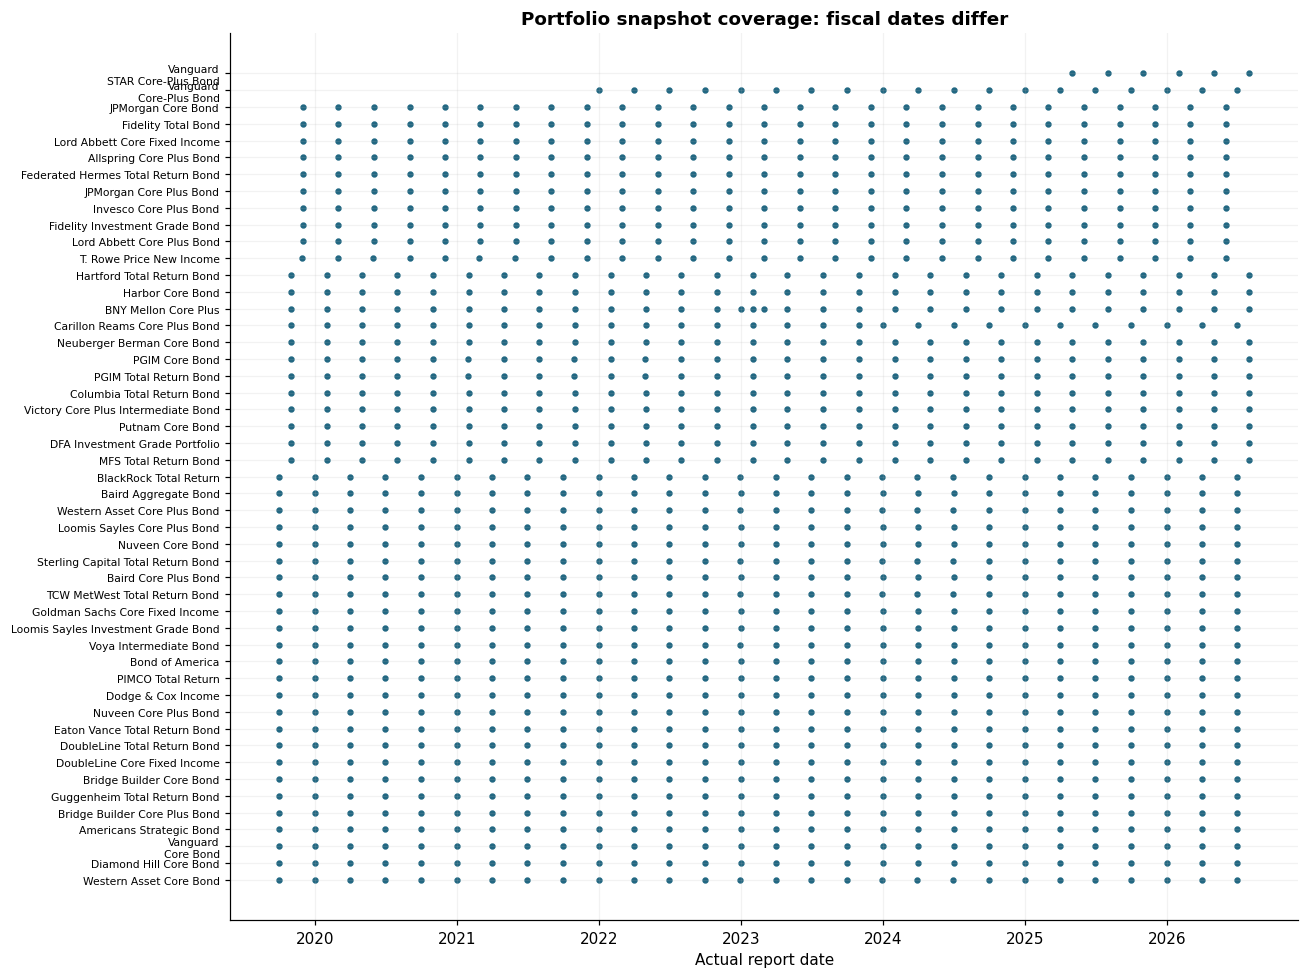

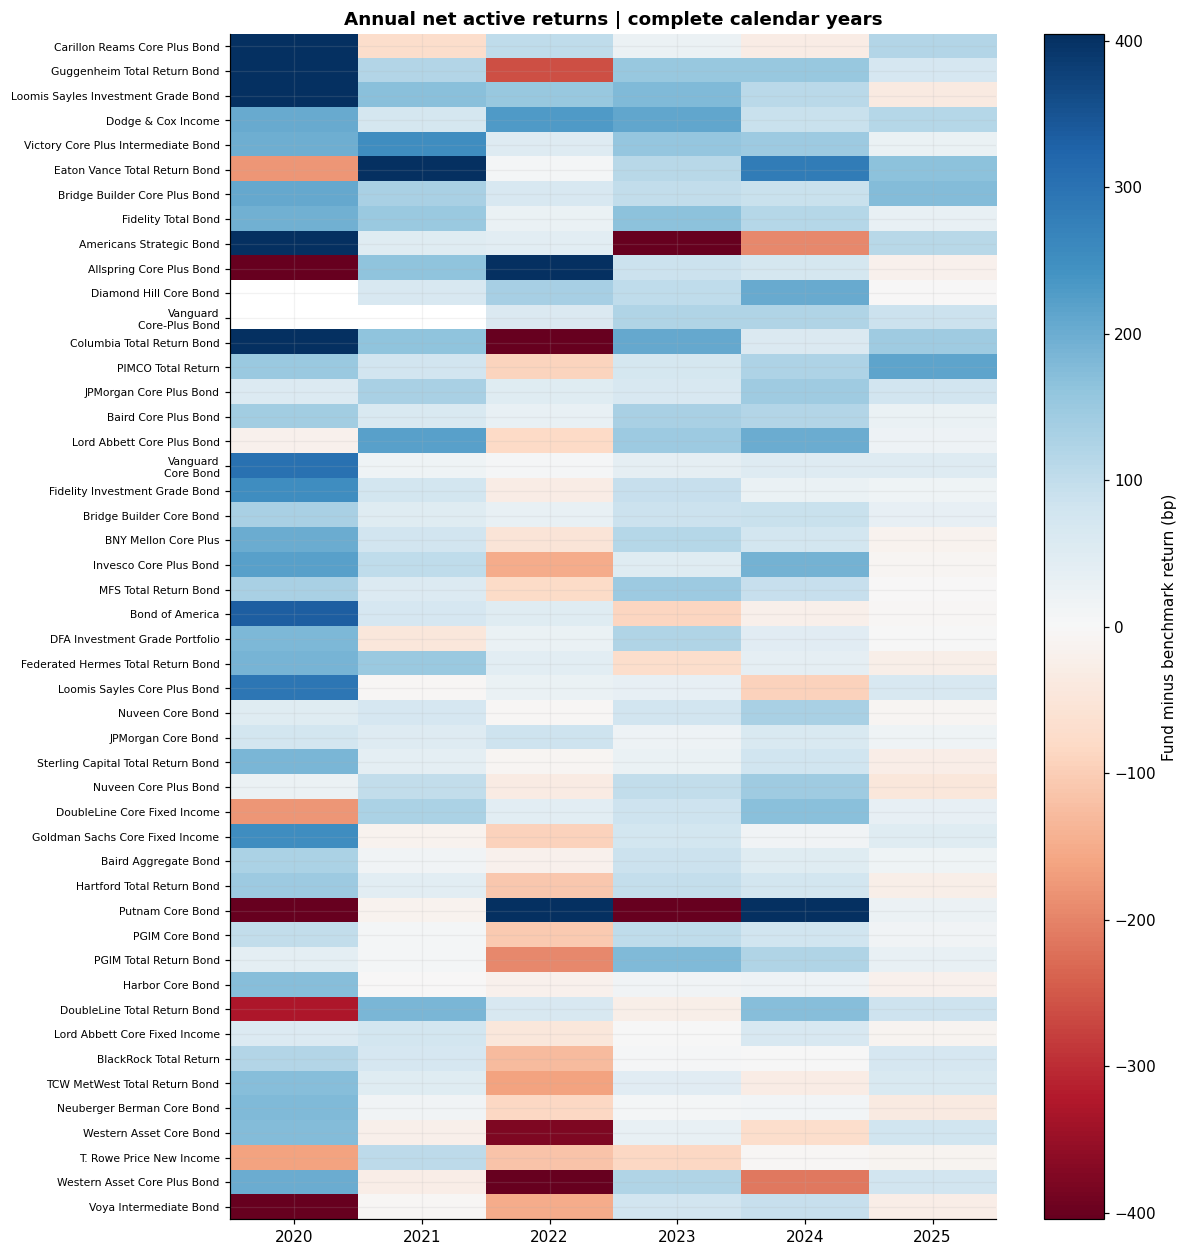

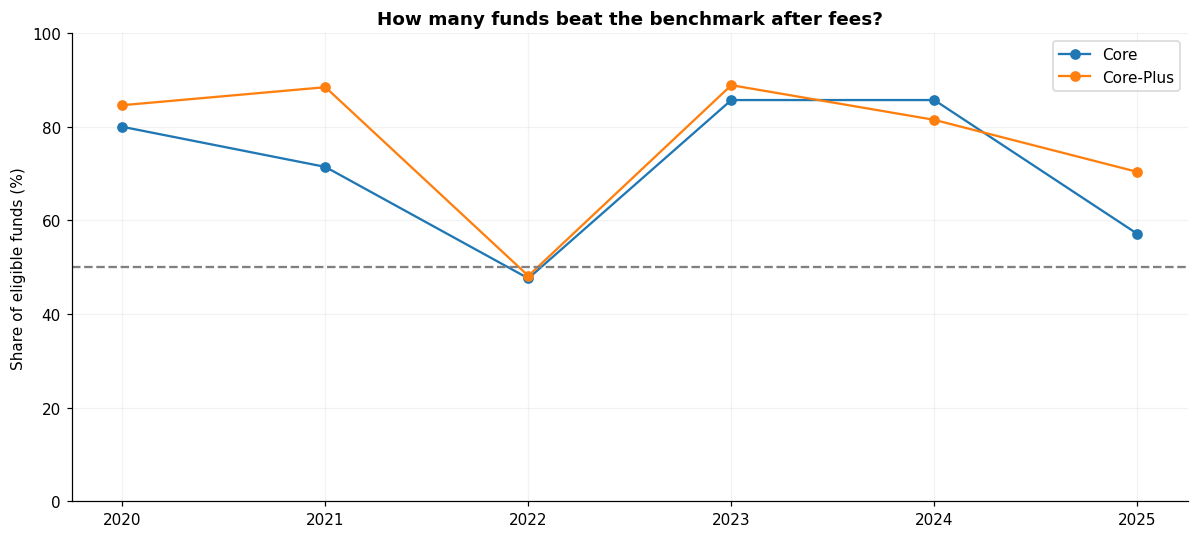

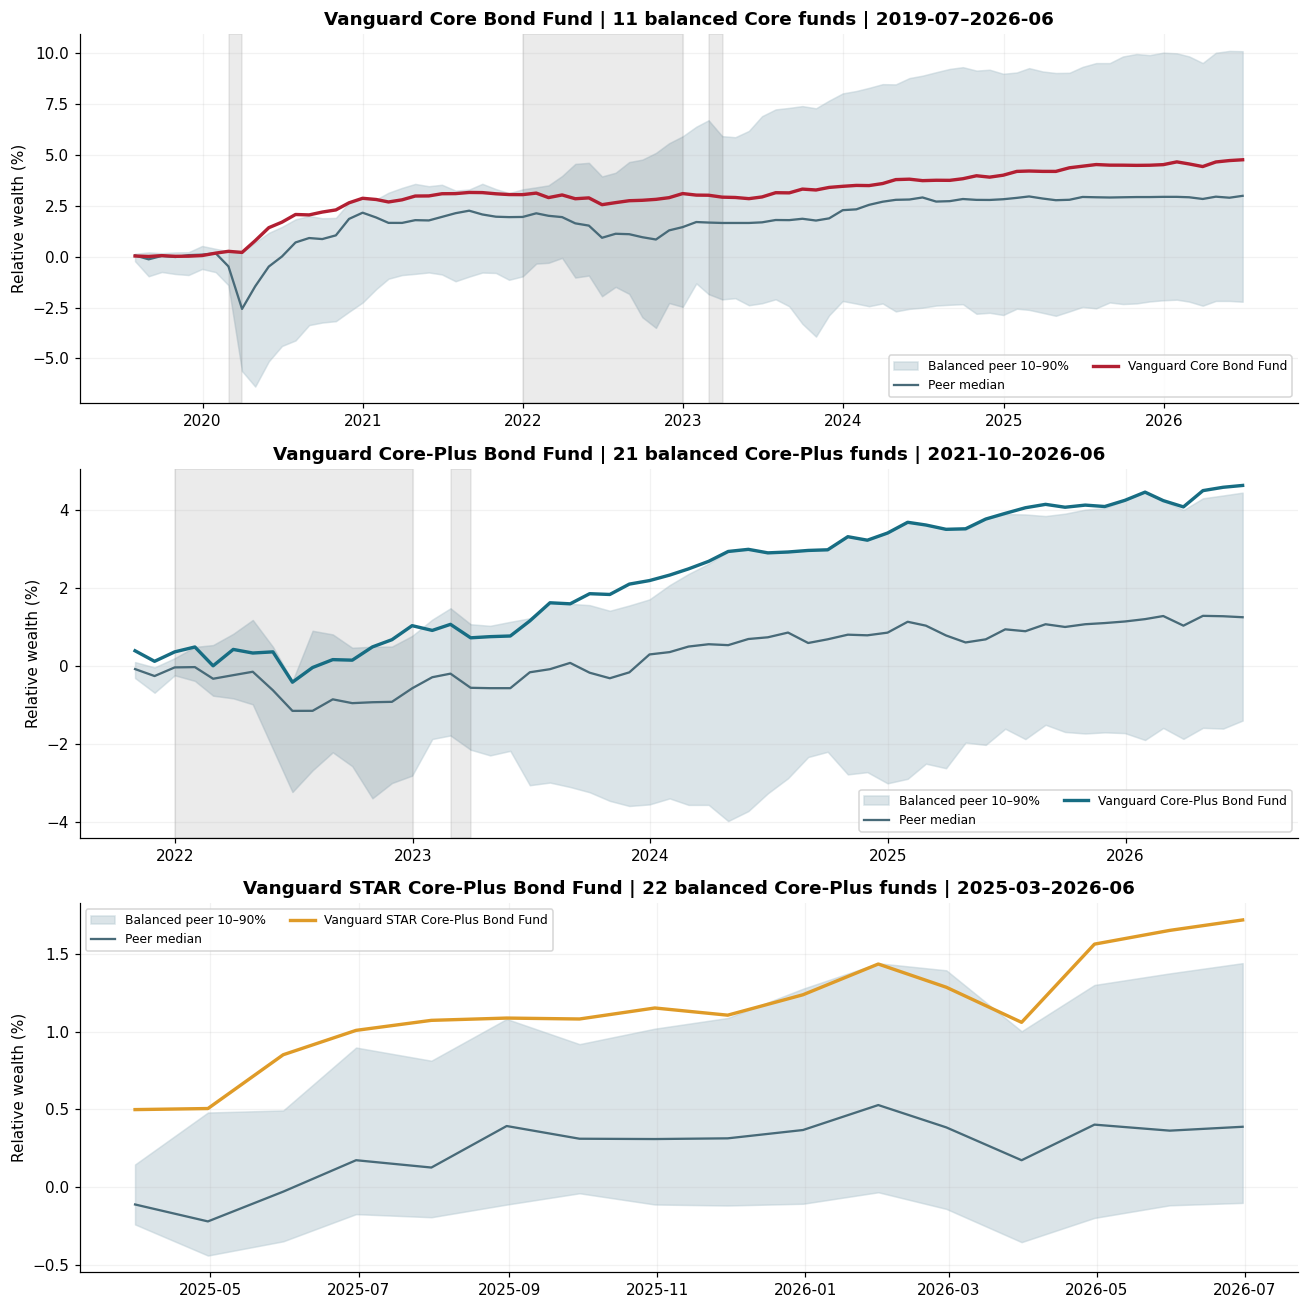

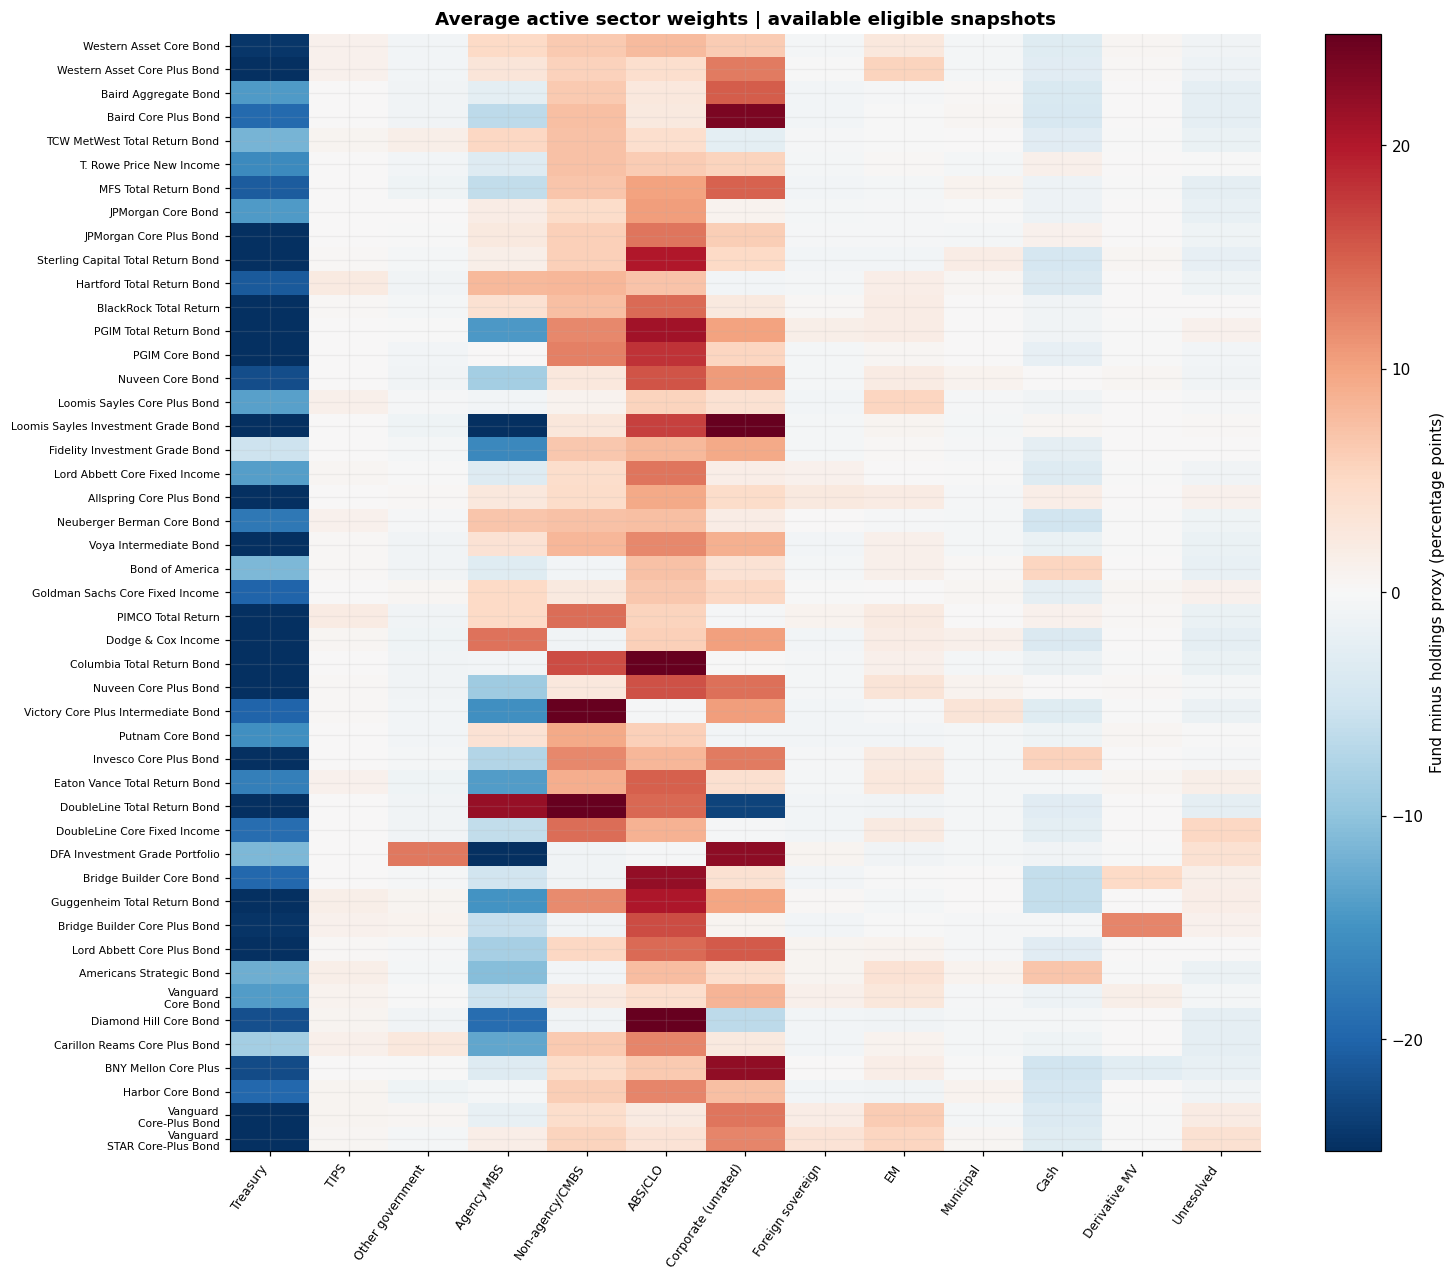

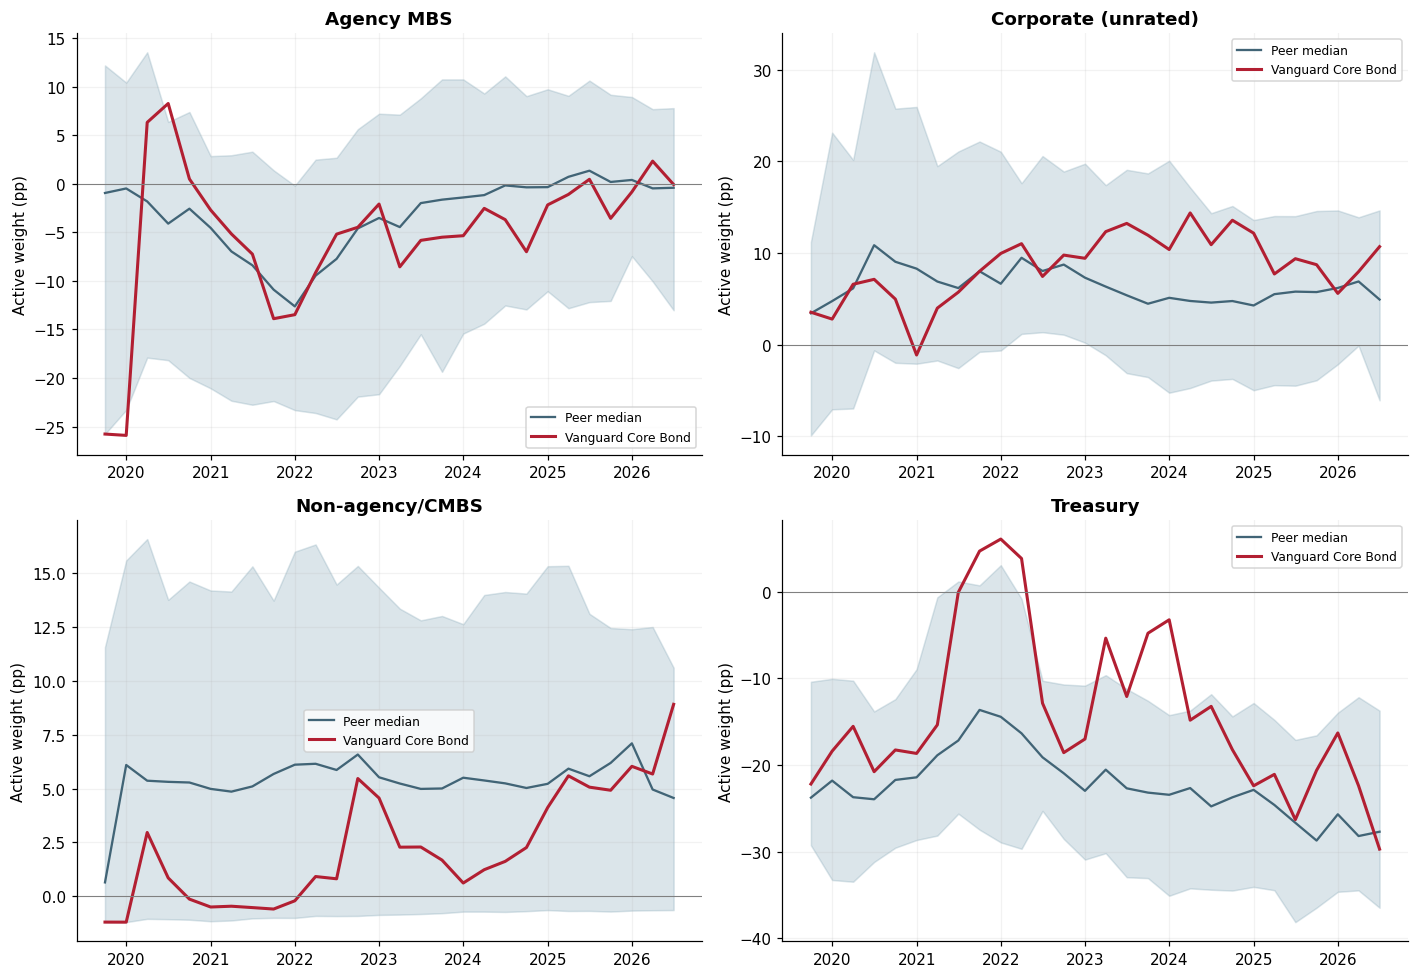

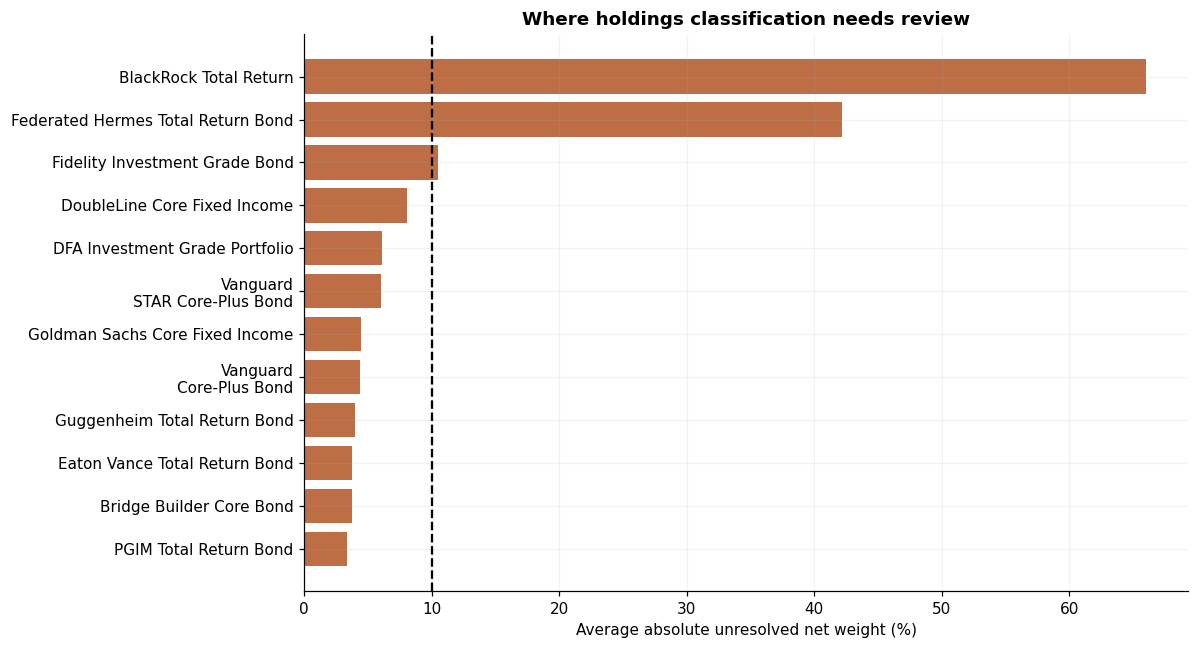

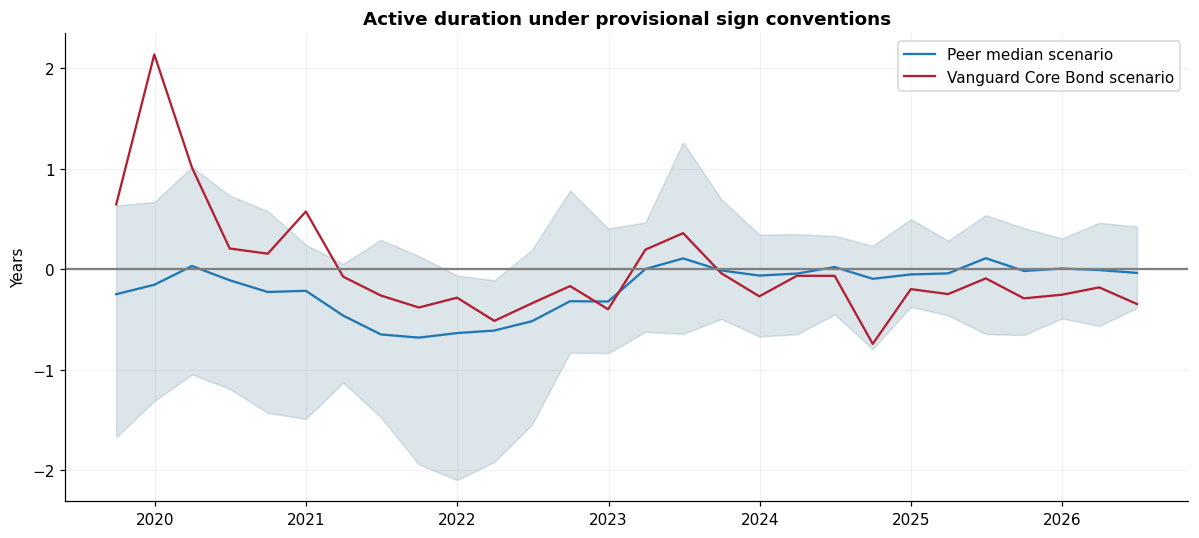

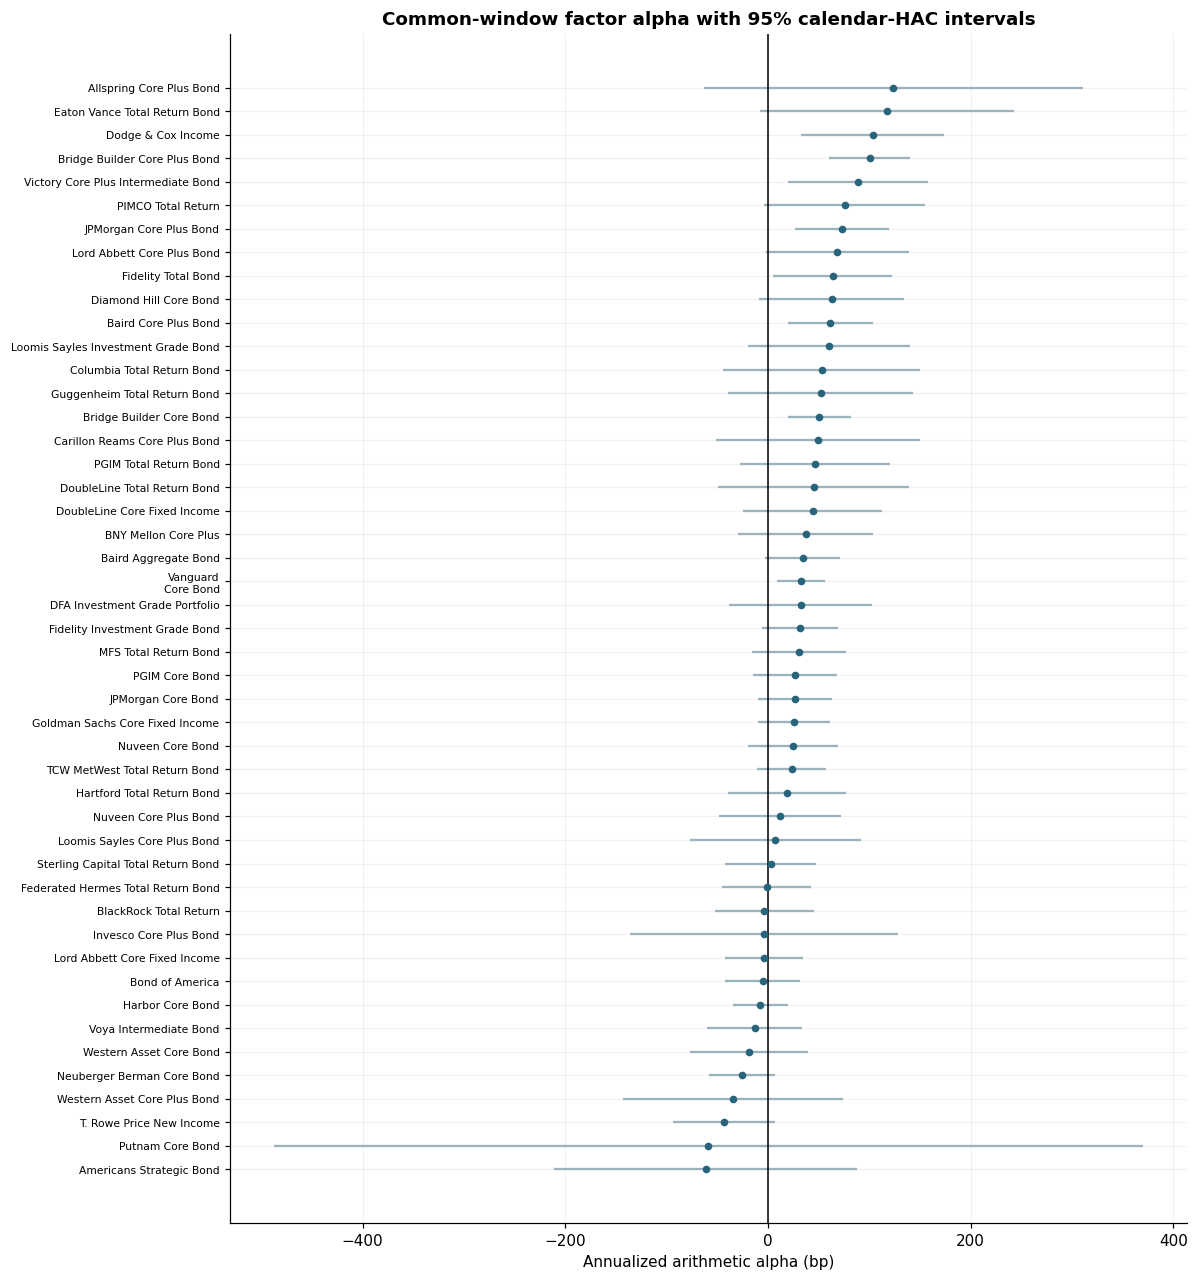

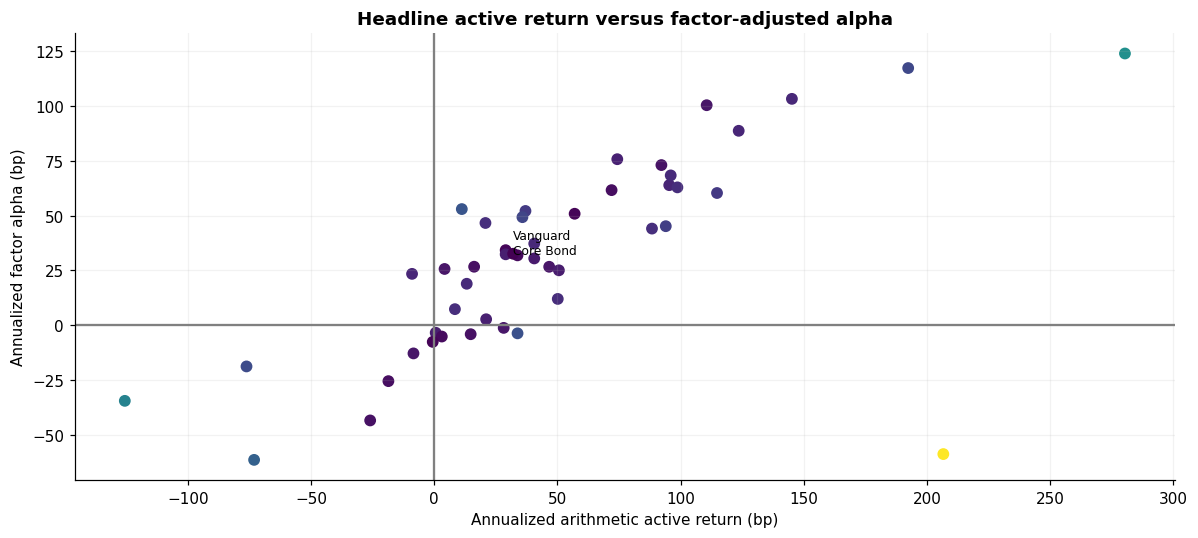

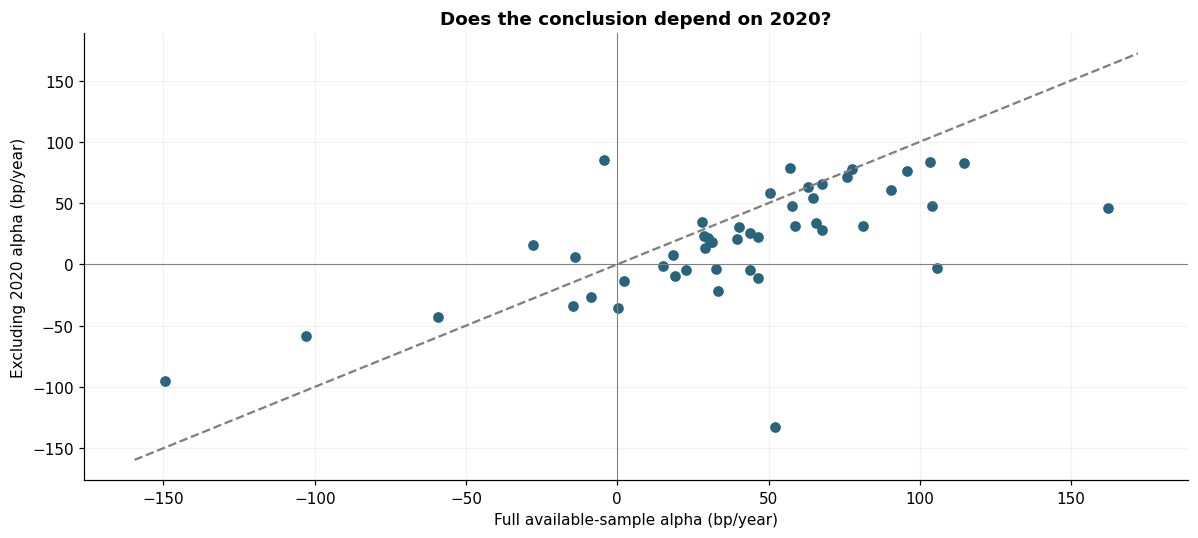

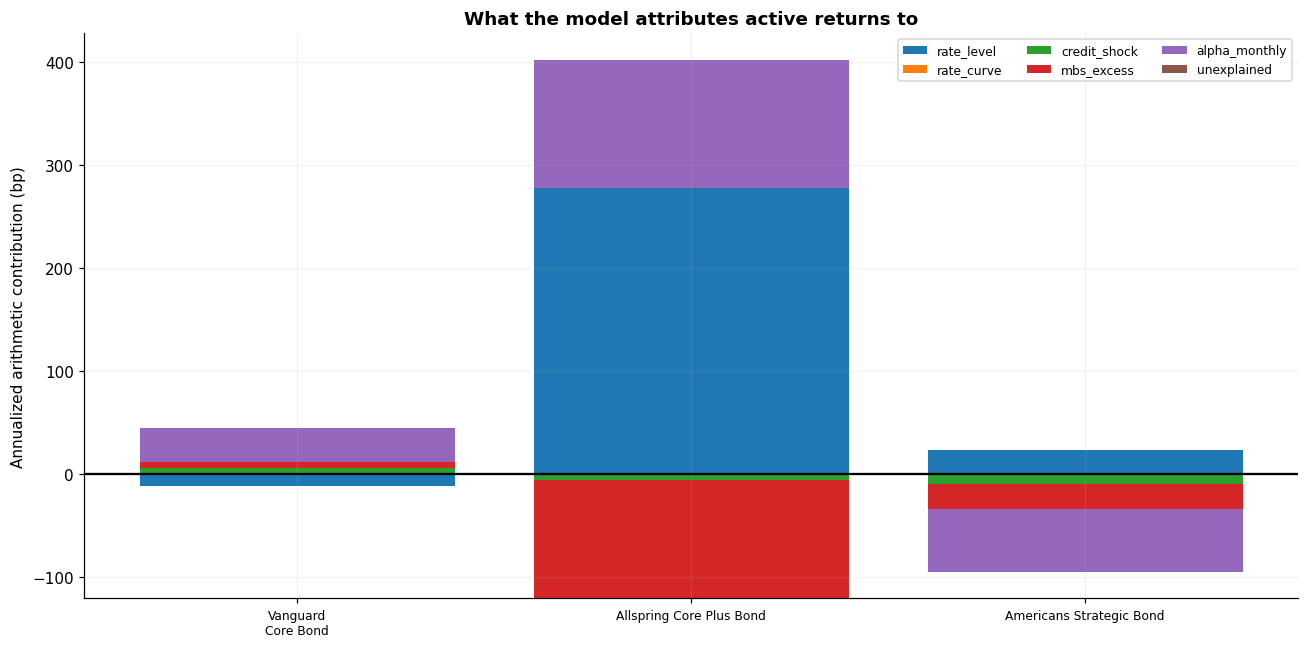

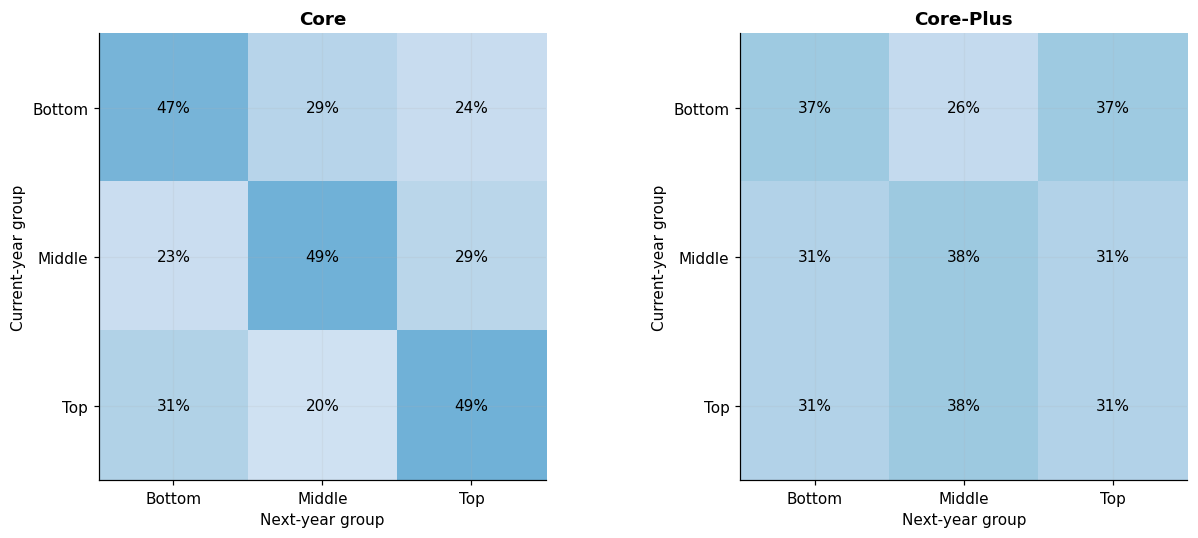

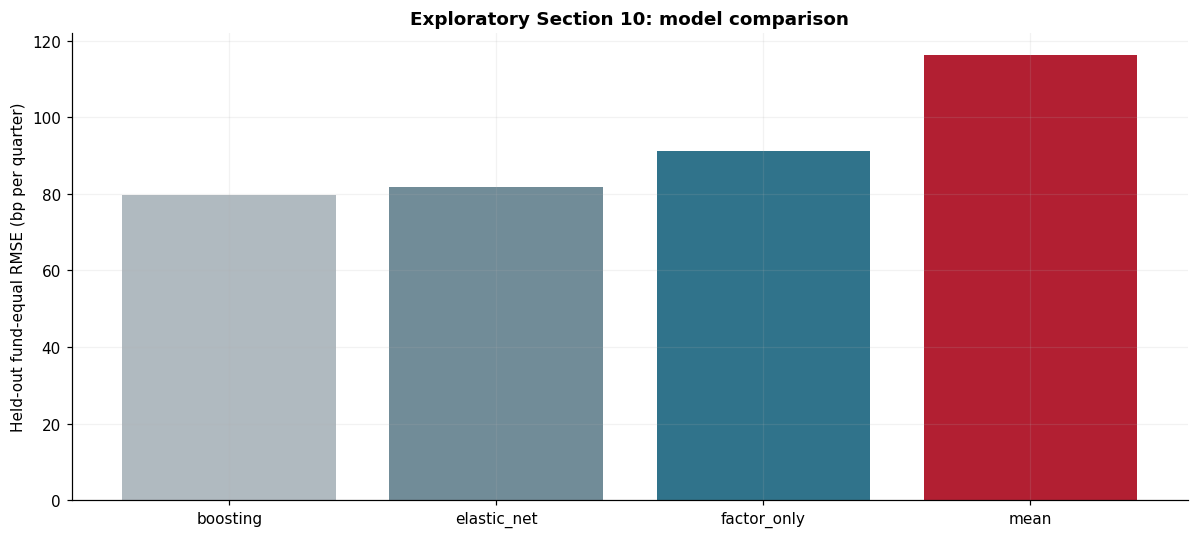

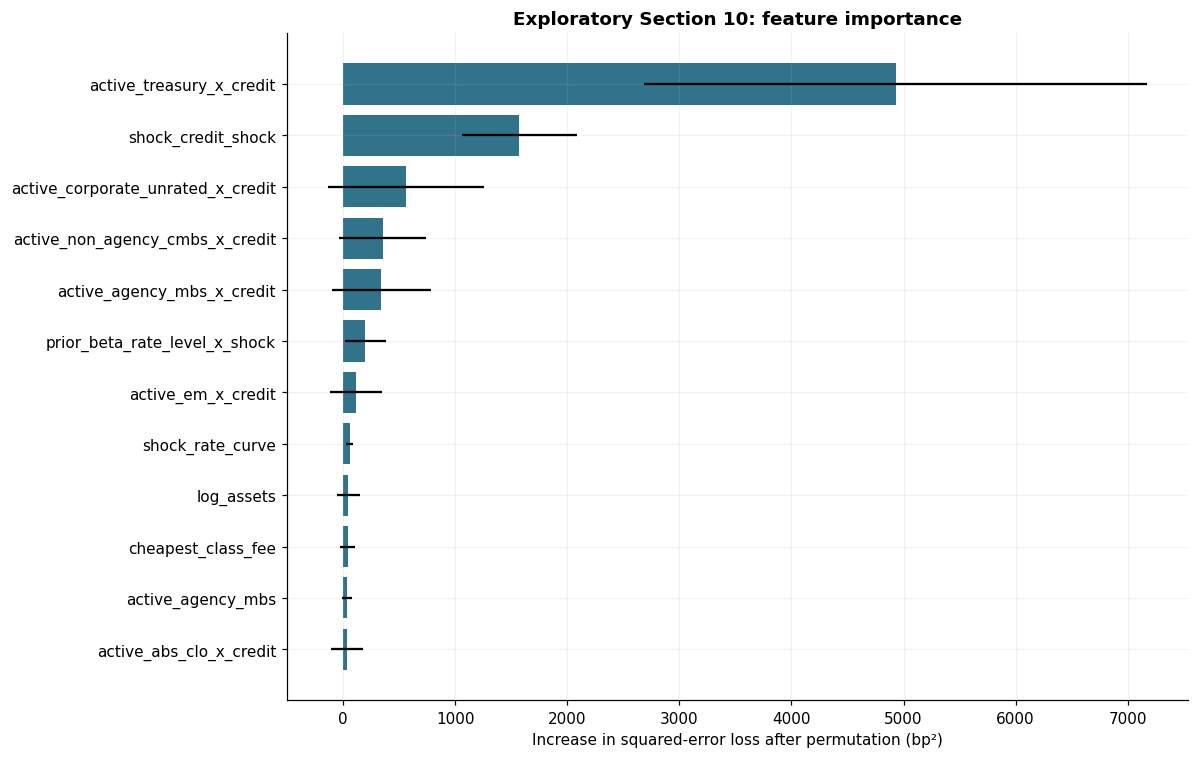

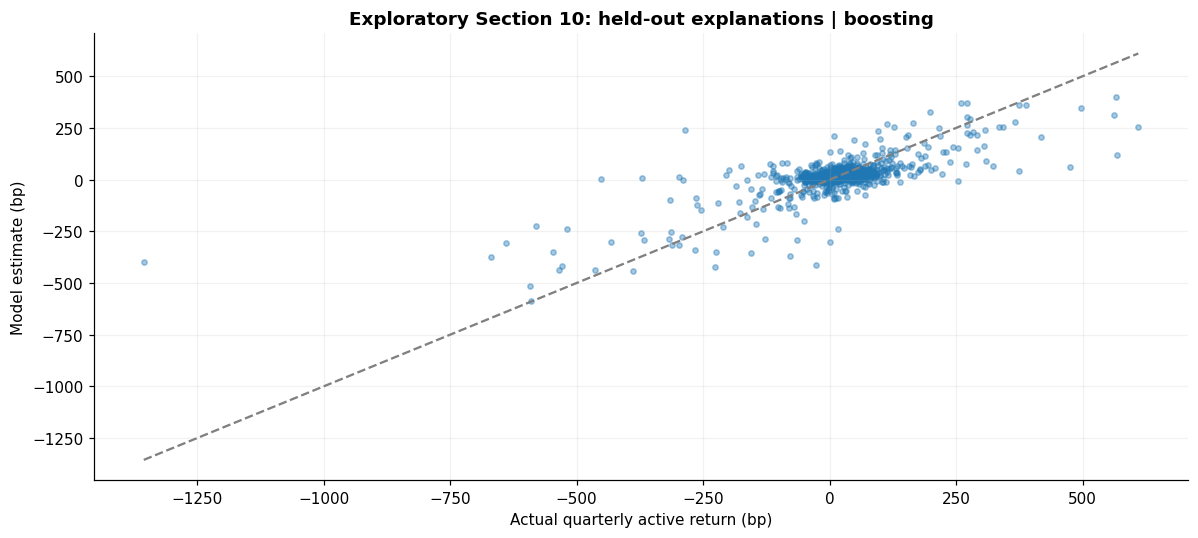

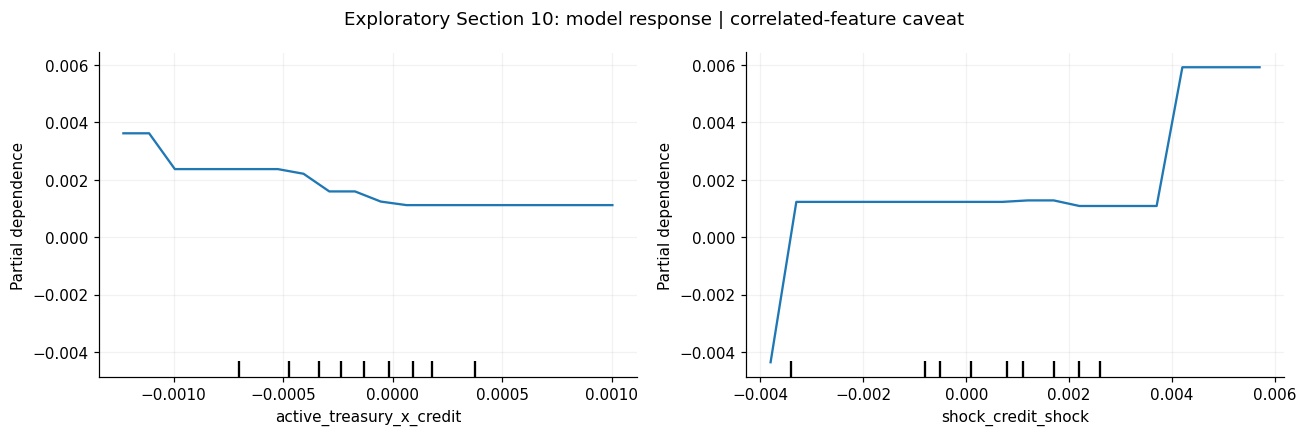

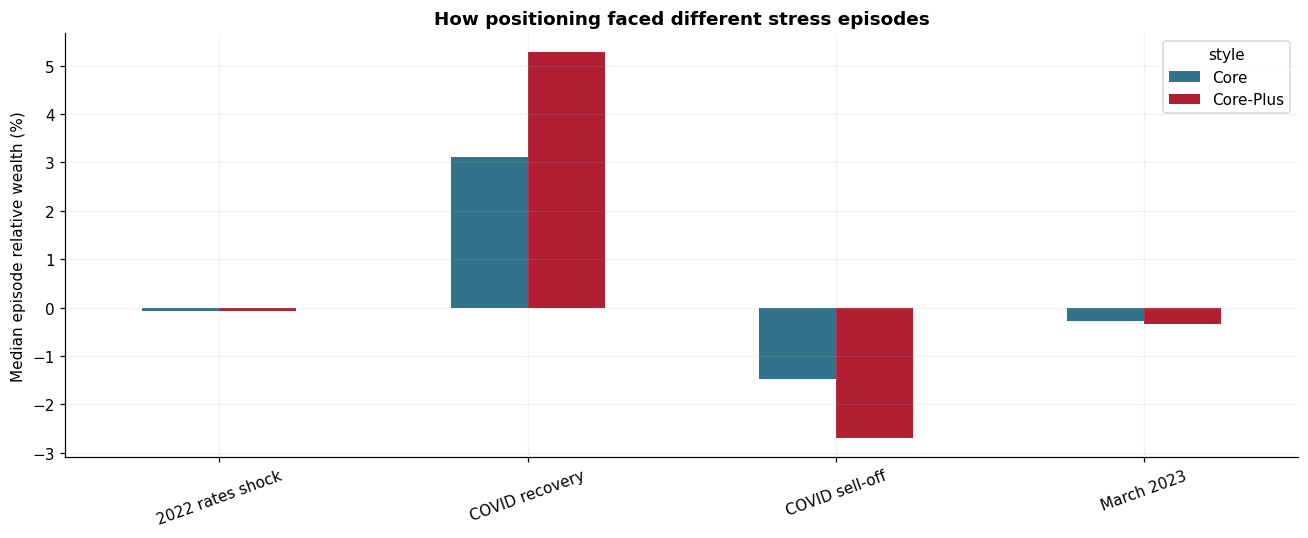

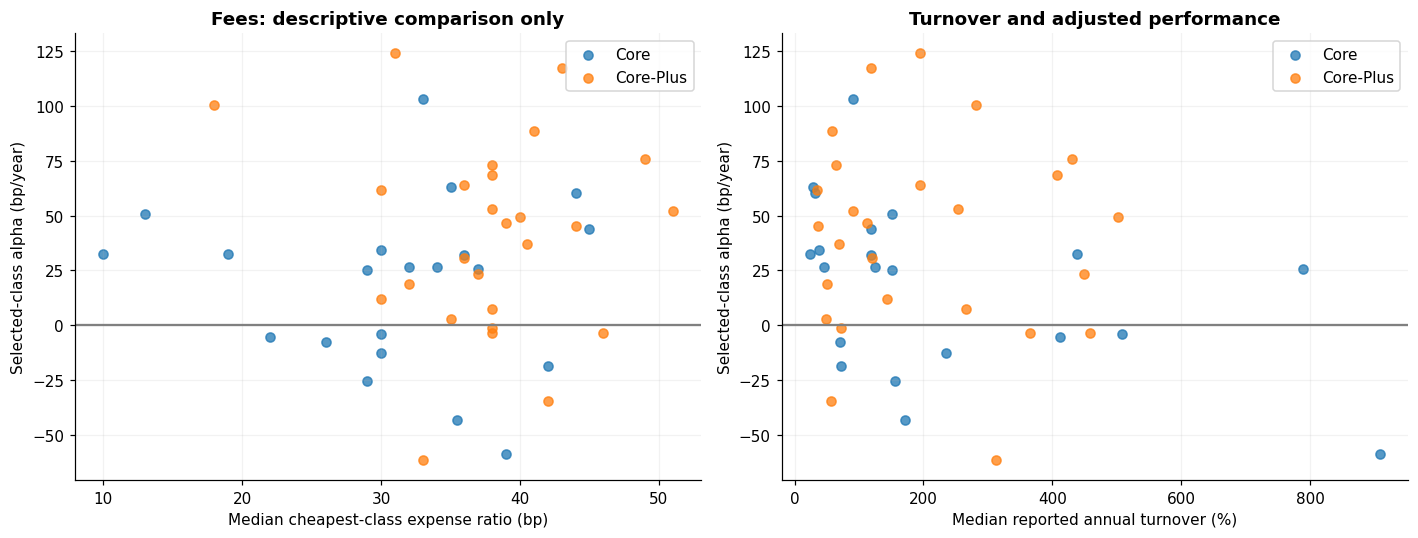

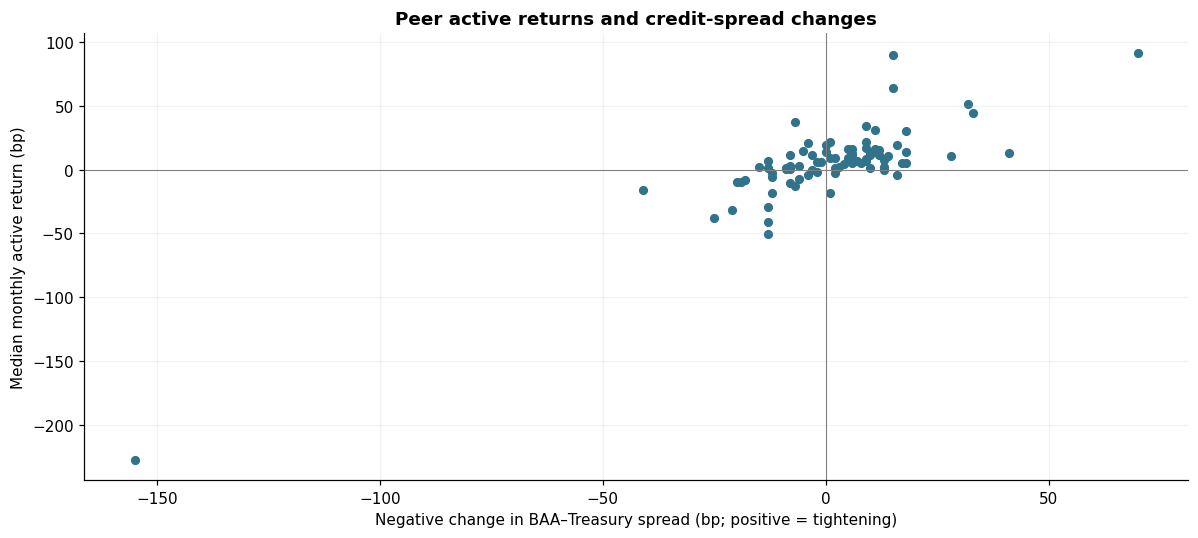

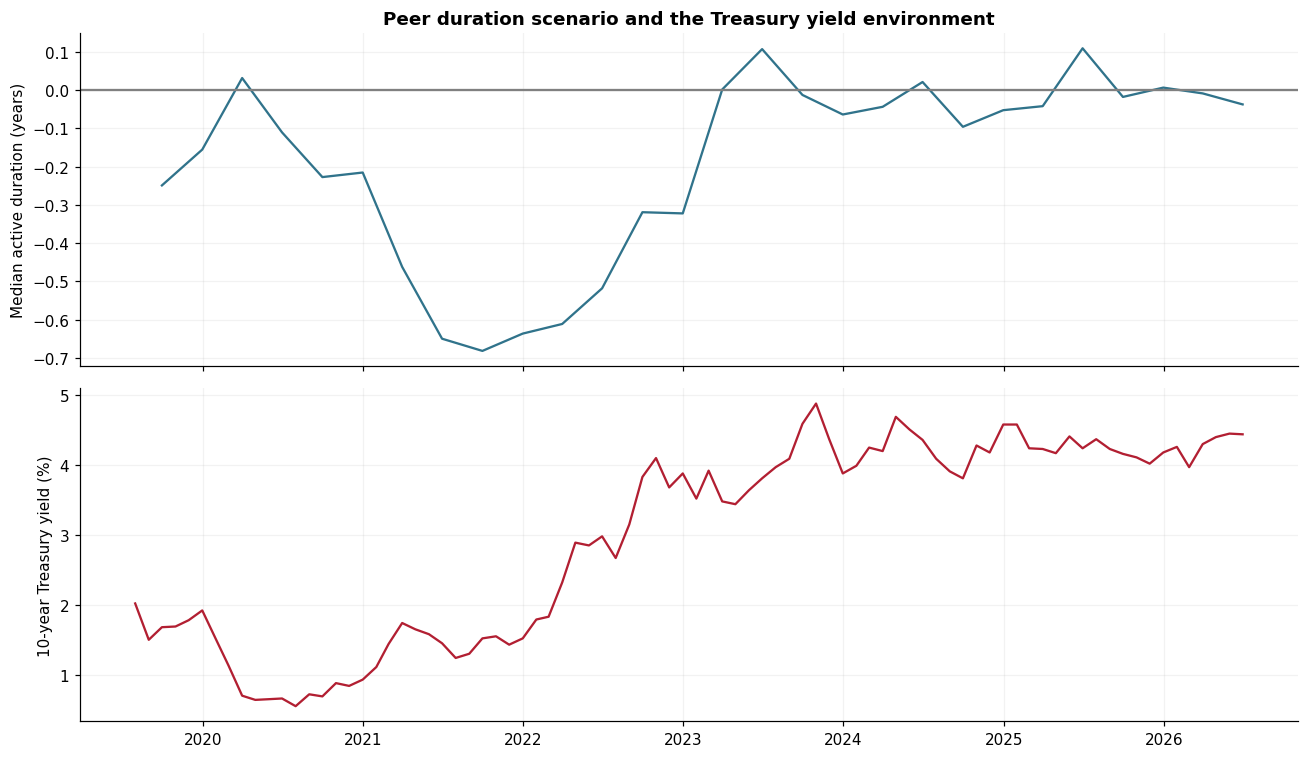

In [12]:
# All charts are exported with their data tables. Named presentation is for the sponsor audience.
VG=primary[primary.role.eq('VANGUARD')].series_id.tolist()
COLORS=['#b21f32','#176d83','#df9b28']
def shortname(s):
    return label(s).replace(' Fund','').replace('Vanguard ','Vanguard\n')
# 1. Coverage and reporting dates.
fig,ax=plt.subplots(figsize=(12,9))
order=coverage[coverage.series_id.isin(ids)].sort_values('first').series_id.tolist()
for j,sid in enumerate(order):
    x=fund[fund.series_id.eq(sid)];ax.scatter(x.report_date,np.repeat(j,len(x)),s=10,color='#216782')
ax.set_yticks(range(len(order)),[shortname(s) for s in order],fontsize=7)
ax.set(title='Portfolio snapshot coverage: fiscal dates differ',xlabel='Actual report date')
savefig('01_coverage','Actual holdings report dates; archive labels are not measurement dates.')
# 2. Annual active returns.
heat=annual[annual.complete_year].pivot(index='series_id',columns='year',values='active_return')*10000
heat=heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig,ax=plt.subplots(figsize=(11,max(6,len(heat)*.24)))
lim=max(100,float(np.nanquantile(np.abs(heat.to_numpy()),.95)))
im=ax.imshow(np.ma.masked_invalid(heat.to_numpy()),aspect='auto',cmap='RdBu',vmin=-lim,vmax=lim)
ax.set_xticks(range(len(heat.columns)),heat.columns);ax.set_yticks(range(len(heat)),[shortname(s) for s in heat.index],fontsize=7)
ax.set_title('Annual net active returns | complete calendar years');fig.colorbar(im,ax=ax,label='Fund minus benchmark return (bp)')
savefig('02_annual_active_returns','Geometrically compounded fund return minus benchmark return; one selected class per fund; flagged funds excluded.')
# 3. Share beating the benchmark.
fig,ax=plt.subplots()
for style,x in annual_summary.groupby('style'):
    ax.plot(x.year,100*x.beating_benchmark_share,marker='o',label=style)
ax.axhline(50,color='gray',ls='--');ax.set(title='How many funds beat the benchmark after fees?',ylabel='Share of eligible funds (%)',ylim=(0,100));ax.legend()
savefig('03_share_outperforming','Complete years only. Denominators by year/style are in annual_peer_summary.csv; sample membership changes.')
# 4. Rebased relative-wealth comparisons for each Vanguard fund.
fig,axes=plt.subplots(3,1,figsize=(12,12))
for ax,sid,color in zip(axes,VG,COLORS):
    v=R[R.series_id.eq(sid)].sort_values('month_end')
    if v.empty:ax.text(.1,.5,'No eligible returns',transform=ax.transAxes);continue
    dates=pd.date_range(v.month_end.min(),v.month_end.max(),freq='ME')
    style=v['style'].iloc[0];peer=R[(R['style']==style)&R.month_end.isin(dates)]
    mat=peer.pivot(index='month_end',columns='series_id',values='return_decimal').reindex(dates).dropna(axis=1)
    bm=b.set_index('month_end').benchmark_return.reindex(dates)
    rel=(1+mat).cumprod().div((1+bm).cumprod(),axis=0)-1
    q=rel.quantile([.1,.5,.9],axis=1).T*100
    ax.fill_between(dates,q[.1],q[.9],color='#b8cbd3',alpha=.5,label='Balanced peer 10–90%')
    ax.plot(dates,q[.5],color='#486a78',label='Peer median')
    if sid in rel:ax.plot(dates,100*rel[sid],lw=2.2,color=color,label=label(sid))
    for start,end in [('2020-03-01','2020-04-01'),('2022-01-01','2023-01-01'),('2023-03-01','2023-04-01')]:
        if pd.Timestamp(start)<=dates.max() and pd.Timestamp(end)>=dates.min():ax.axvspan(pd.Timestamp(start),pd.Timestamp(end),alpha=.08,color='black')
    ax.set(title=f'{label(sid)} | {len(mat.columns)} balanced {style} funds | {dates.min():%Y-%m}–{dates.max():%Y-%m}',ylabel='Relative wealth (%)')
    ax.legend(fontsize=8,ncol=2)
savefig('04_vanguard_relative_wealth','Each panel is rebased at its own start and uses an identical-month balanced peer set. Different panels are not directly comparable in cumulative magnitude.')
# 5. Average active sectors.
hh=positions[positions.position_eligible].groupby('series_id')[ac].mean()
hh=hh.rename(columns={'active__'+k:v for k,v in SHORTMAP.items()})
fig,ax=plt.subplots(figsize=(14,max(6,len(hh)*.25)))
im=ax.imshow(hh.to_numpy(),aspect='auto',cmap='RdBu_r',vmin=-25,vmax=25)
ax.set_xticks(range(len(hh.columns)),hh.columns,rotation=55,ha='right',fontsize=8)
ax.set_yticks(range(len(hh)),[shortname(s) for s in hh.index],fontsize=7);ax.set_title('Average active sector weights | available eligible snapshots')
fig.colorbar(im,ax=ax,label='Fund minus holdings proxy (percentage points)')
savefig('05_active_sector_heatmap','Agency MBS is separate. Averages use different available histories; this chart describes portfolios, not performance ranks.')
# 6. Quarter-end panels use the last earlier snapshot and explicitly cap its age.
qdates=pd.date_range(positions.report_date.min(),positions.report_date.max(),freq='QE')
qrows=[]
for sid,x in positions.groupby('series_id'):
    z=pd.merge_asof(pd.DataFrame({'quarter_end':qdates}),x.sort_values('report_date'),left_on='quarter_end',right_on='report_date',direction='backward',tolerance=pd.Timedelta(days=100))
    qrows.append(z)
qpanel=pd.concat(qrows,ignore_index=True).dropna(subset=['series_id']);save_table(qpanel,'quarterly_position_chart_panel')
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,sec in zip(axes.flat,['Agency MBS','Corporate debt (ratings pending)','Non-agency MBS / CMBS','US Treasury (nominal)']):
    col='active__'+sec;mat=qpanel.pivot(index='quarter_end',columns='series_id',values=col)
    qs=mat.quantile([.1,.5,.9],axis=1).T
    ax.fill_between(qs.index,qs[.1],qs[.9],alpha=.25,color='#7199ac');ax.plot(qs.index,qs[.5],color='#416476',label='Peer median')
    if VG[0] in mat:ax.plot(mat.index,mat[VG[0]],color=COLORS[0],lw=2,label='Vanguard Core Bond')
    ax.axhline(0,color='gray',lw=.7);ax.set(title=SHORTMAP[sec],ylabel='Active weight (pp)');ax.legend(fontsize=8)
savefig('06_peer_positioning_bands','10–90% peer range; last earlier fund snapshot capped at 100 days. Composition changes over time; detailed sample counts are exported.')
save_table(qpanel.groupby('quarter_end')[ac].count().reset_index(),'quarterly_positioning_sample_counts')
# 7. Classification review and 8. sign scenario.
badclass=sectors[sectors.series_id.isin(ids)].groupby('series_id').unresolved_net_weight_pct.mean().nlargest(12).sort_values()
fig,ax=plt.subplots(figsize=(11,6));ax.barh([shortname(s) for s in badclass.index],badclass,color='#bd6e45')
ax.axvline(CFG['max_unresolved_pct'],color='black',ls='--');ax.set(title='Where holdings classification needs review',xlabel='Average absolute unresolved net weight (%)')
savefig('07_classification_review','Unresolved normalized net weight; gross offsetting positions can remain hidden. The dashed line is the provisional analytical screen.')
fig,ax=plt.subplots()
mat=qpanel.pivot(index='quarter_end',columns='series_id',values='active_duration_scenario');qs=mat.quantile([.1,.5,.9],axis=1).T
ax.fill_between(qs.index,qs[.1],qs[.9],alpha=.25,color='#7199ac');ax.plot(qs.index,qs[.5],label='Peer median scenario')
if VG[0] in mat:ax.plot(mat.index,mat[VG[0]],color=COLORS[0],label='Vanguard Core Bond scenario')
ax.axhline(0,color='gray');ax.set(title='Active duration under provisional sign conventions',ylabel='Years');ax.legend()
savefig('08_active_duration_scenario','Scenario only until independently verified sign overrides are supplied. Ambiguous conventions and extreme values remain missing; not used to establish skill.')
if len(models):
    mm=models[(models.model=='main')&(models['sample']=='common')].sort_values('alpha_ann')
    # 9. Alpha intervals, with both FDR and reference-class uncertainty.
    fig,ax=plt.subplots(figsize=(11,max(6,len(mm)*.25)))
    ax.errorbar(mm.alpha_ann*10000,np.arange(len(mm)),xerr=np.vstack([(mm.alpha_ann-mm.ci_low)*10000,(mm.ci_high-mm.alpha_ann)*10000]),fmt='o',ms=4,color='#28647c',ecolor='#9cb2bd')
    ax.set_yticks(range(len(mm)),[shortname(s) for s in mm.series_id],fontsize=7);ax.axvline(0,color='black',lw=1)
    ax.set(title='Common-window factor alpha with 95% calendar-HAC intervals',xlabel='Annualized arithmetic alpha (bp)')
    savefig('09_alpha_intervals','2021–2025. Intervals are individual, not simultaneous; FDR and joint-bootstrap tests are in the scorecards. Alpha is conditional on the model, not proof of skill.')
    # 10. Risk adjustment changes the ranking.
    zz=common.merge(mm[['series_id','alpha_ann']],on='series_id')
    fig,ax=plt.subplots();ax.scatter(zz.annualized_arithmetic_active*10000,zz.alpha_ann*10000,c=zz.tracking_error,cmap='viridis',s=45)
    for sid in VG:
        v=zz[zz.series_id==sid]
        if len(v):ax.annotate(shortname(sid),(v.annualized_arithmetic_active.iloc[0]*10000,v.alpha_ann.iloc[0]*10000),fontsize=8)
    ax.axhline(0,color='gray');ax.axvline(0,color='gray');ax.set(title='Headline active return versus factor-adjusted alpha',xlabel='Annualized arithmetic active return (bp)',ylabel='Annualized factor alpha (bp)')
    savefig('10_return_vs_alpha','Same common months and selected classes. The difference is model-explained exposure, not automatically luck.')
    # 11. Full vs ex-2020 sensitivity.
    ss=models[models.model.eq('main')&models['sample'].isin(['full','ex2020'])].pivot(index='series_id',columns='sample',values='alpha_ann').dropna()*10000
    fig,ax=plt.subplots();ax.scatter(ss['full'],ss.ex2020,color='#28647c');lim=[ss.min().min()-10,ss.max().max()+10];ax.plot(lim,lim,ls='--',color='gray')
    ax.axhline(0,color='gray',lw=.7);ax.axvline(0,color='gray',lw=.7);ax.set(title='Does the conclusion depend on 2020?',xlabel='Full available-sample alpha (bp/year)',ylabel='Excluding 2020 alpha (bp/year)')
    savefig('11_covid_sensitivity','Each fund uses its own available history. 2020 is removed explicitly; HAC does not treat December 2019 and January 2021 as adjacent months.')
    # 12. Contributions for predeclared Vanguard + mechanical best/worst common alpha examples.
    cases=list(dict.fromkeys([*VG,mm.iloc[-1].series_id,mm.iloc[0].series_id]))
    cc=contributions[contributions['sample'].eq('common')]
    case_rows=[]
    for sid in cases:
        z=cc[cc.series_id.eq(sid)]
        if len(z):
            row={'series_id':sid}
            for c in MAIN+['alpha_monthly','unexplained']:row[c]=z[c].mean()*120000
            case_rows.append(row)
    cd=pd.DataFrame(case_rows).set_index('series_id');save_table(cd.reset_index(),'case_annualized_model_contributions_bp')
    fig,ax=plt.subplots(figsize=(12,6));bottomp=np.zeros(len(cd));bottomn=np.zeros(len(cd))
    for c in cd.columns:
        vals=cd[c].to_numpy();bottom=np.where(vals>=0,bottomp,bottomn)
        ax.bar(np.arange(len(cd)),vals,bottom=bottom,label=c)
        bottomp+=np.maximum(vals,0);bottomn+=np.minimum(vals,0)
    ax.set_xticks(range(len(cd)),[shortname(s) for s in cd.index],fontsize=8);ax.axhline(0,color='black');ax.set(title='What the model attributes active returns to',ylabel='Annualized arithmetic contribution (bp)');ax.legend(fontsize=8,ncol=3)
    savefig('12_case_contributions','Additive joint-regression contributions on identical common months. Best/worst cases were selected by estimated alpha and are illustrative, not independently confirmed winners/losers. Short-history Vanguard funds lack common-window bars.')
if len(transitions):
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for ax,style in zip(axes,sorted(transitions['style'].unique())):
        z=transitions[(transitions['sample']=='full')&(transitions['style']==style)].pivot(index='bucket_t',columns='bucket_next',values='probability').reindex(index=['Bottom','Middle','Top'],columns=['Bottom','Middle','Top'])
        im=ax.imshow(z,cmap='Blues',vmin=0,vmax=1)
        for i in range(3):
            for j in range(3):ax.text(j,i,f'{z.iloc[i,j]:.0%}',ha='center',va='center')
        ax.set_xticks(range(3),z.columns);ax.set_yticks(range(3),z.index);ax.set(title=style,xlabel='Next-year group',ylabel='Current-year group')
    savefig('13_persistence_transitions','Adjacent complete calendar years; within-style terciles; descriptive transitions, not independent Bernoulli trials.')
if len(ml_scores):
    z=ml_scores[ml_scores.validation.eq('held_out_fund')]
    fig,ax=plt.subplots();ax.bar(z.model,z.fund_equal_rmse*10000,color=['#b0bac0','#718c98','#30738b','#b21f32']);ax.set(title='Exploratory Section 10: model comparison',ylabel='Held-out fund-equal RMSE (bp per quarter)')
    savefig('14_ml_model_comparison','Exploratory Section 10; superseded by Section 14. Nested tuning holds out whole funds. Lower error is better. Realized macro shocks are explanatory inputs, not known future predictors.')
    im=ml_importance[ml_importance.model.eq(selected)].groupby('feature').mse_increase.agg(['mean','std']).nlargest(12,'mean').sort_values('mean')
    fig,ax=plt.subplots(figsize=(11,7));ax.barh(im.index,im['mean']*1e8,xerr=im['std'].fillna(0)*1e8,color='#30738b');ax.set(title='Exploratory Section 10: feature importance',xlabel='Increase in squared-error loss after permutation (bp²)')
    savefig('15_ml_permutation_importance','Exploratory Section 10; superseded by Section 14. Means and dispersion across held-out folds. Correlated features share importance; negative importance means the feature did not help reliably.')
    zz=oof[(oof.validation=='held_out_fund')&(oof.model==selected)]
    fig,ax=plt.subplots();ax.scatter(zz.target*10000,zz.prediction*10000,s=12,alpha=.4);lim=[min(zz.target.min(),zz.prediction.min())*10000,max(zz.target.max(),zz.prediction.max())*10000];ax.plot(lim,lim,color='gray',ls='--');ax.set(title=f'Exploratory Section 10: held-out explanations | {selected}',xlabel='Actual quarterly active return (bp)',ylabel='Model estimate (bp)')
    savefig('16_ml_actual_vs_fitted','Exploratory Section 10; superseded by Section 14. Every dot is an outer held-out fund-quarter. The diagonal represents perfect agreement, not a forecast target.')
    if final_ml is not None:
        topfeatures=im.sort_values('mean',ascending=False).head(2).index.tolist()
        fig,axes=plt.subplots(1,len(topfeatures),figsize=(12,4),squeeze=False)
        with threadpool_limits(limits=1):PartialDependenceDisplay.from_estimator(final_ml,ml_panel[feature_cols],topfeatures,ax=axes[0],kind='average',grid_resolution=20)
        fig.suptitle('Exploratory Section 10: model response | correlated-feature caveat')
        savefig('17_ml_partial_dependence','Exploratory Section 10; superseded by Section 14. Full-sample exploratory fit for illustration only. Partial dependence can evaluate unrealistic combinations of correlated positions; it is not a causal effect.')
# Stress comparisons, with eligibility visible in the table.
if len(stress):
    z=stress.merge(primary[['series_id','style']],on='series_id').groupby(['event','style']).annualized_arithmetic_excess.mean() if 'annualized_arithmetic_excess' in stress else None
    ev=stress.merge(primary[['series_id','style']],on='series_id')
    ev['episode_relative_return']=ev.cumulative_relative_wealth
    ep=ev.groupby(['event','style']).episode_relative_return.median().unstack()*100
    fig,ax=plt.subplots(figsize=(12,5));ep.plot.bar(ax=ax,color=['#30738b','#b21f32']);ax.set(title='How positioning faced different stress episodes',ylabel='Median episode relative wealth (%)',xlabel='');ax.tick_params(axis='x',rotation=20)
    savefig('18_stress_episodes','Episode returns are not annualized. Windows differ in length; these are descriptions of distinct events, not directly comparable annual performance.')
if len(main_common):
    z=score.dropna(subset=['alpha_ann','cheapest_class_fee_median'])
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for style,g in z.groupby('style'):
        axes[0].scatter(g.cheapest_class_fee_median*10000,g.alpha_ann*10000,label=style,alpha=.75)
        axes[1].scatter(g.turnover_median*100,g.alpha_ann*10000,label=style,alpha=.75)
    axes[0].set(xlabel='Median cheapest-class expense ratio (bp)',ylabel='Selected-class alpha (bp/year)',title='Fees: descriptive comparison only')
    axes[1].set(xlabel='Median reported annual turnover (%)',ylabel='Selected-class alpha (bp/year)',title='Turnover and adjusted performance')
    for ax in axes:ax.axhline(0,color='gray');ax.legend()
    savefig('19_fees_turnover','2021–2025 medians. Fees are for the cheapest investable class and may differ from the selected return class. This is not an estimate of the causal effect of fees or an expense-addback calculation.')
peer_active=R.groupby('month_end').active_return.agg(['median','count']).join(factors[['credit_shock']]).dropna()
if len(peer_active):
    save_table(peer_active.reset_index(),'peer_credit_relationship')
    fig,ax=plt.subplots();ax.scatter(peer_active.credit_shock*10000,peer_active['median']*10000,s=25,color='#30738b')
    ax.axhline(0,color='gray',lw=.7);ax.axvline(0,color='gray',lw=.7)
    ax.set(title='Peer active returns and credit-spread changes',xlabel='Negative change in BAA–Treasury spread (bp; positive = tightening)',ylabel='Median monthly active return (bp)')
    savefig('20_peer_credit_relationship','Contemporaneous descriptive association. BAA–Treasury spread is not a pure duration-matched corporate factor. Monthly peer counts are exported.')
if len(rate_monthly):
    fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
    dm=qpanel.pivot(index='quarter_end',columns='series_id',values='active_duration_scenario')
    axes[0].plot(dm.index,dm.median(axis=1),color='#30738b');axes[0].axhline(0,color='gray')
    axes[0].set(title='Peer duration scenario and the Treasury yield environment',ylabel='Median active duration (years)')
    rr=rate_monthly.loc[R.month_end.min():R.month_end.max()]
    axes[1].plot(rr.index,rr.DGS10,color='#b21f32');axes[1].set(ylabel='10-year Treasury yield (%)')
    savefig('21_duration_and_yields','Separate axes show timing, not a predictive or causal relation. Duration relies on the provisional sign-convention scenario.')


## 13. Export report, checks and the handoff ZIP

This final cell checks identities and split integrity, writes the scorecards and complete limitation list, creates a self-contained HTML gallery, and packages presentation outputs into one ZIP. Cached market downloads are excluded from the ZIP to keep it manageable; input hashes and URLs are retained. Save the executed notebook separately if you want the entire visible run history.

In [13]:
import base64
# Internal consistency checks on final outputs and small known-answer calculations.
check('relative wealth definition',np.isclose((1.1*1.05)/(1.02*1.03)-1, np.prod(1+np.array([.1,.05]))/np.prod(1+np.array([.02,.03]))-1))
check('BH adjusted p-values bounded',np.all((bh_adjust([.01,.03,.9])>=0)&(bh_adjust([.01,.03,.9])<=1)))
check('zero active sectors identity',np.allclose(positions.loc[positions.position_eligible,ac].sum(axis=1),0,atol=1e-5))
check('returns have no duplicate funds',not R.duplicated(['series_id','month_end']).any())
if len(ml_scores):
    z=oof[oof.validation.eq('held_out_fund')]
    check('one OOF prediction per fund-quarter-model',not z.duplicated(['series_id','quarter_end','model']).any())
    check('all ML feature importance from held-out folds',len(ml_importance)>0)
save_table(score[score.role.eq('VANGUARD')],'vanguard_scorecards')
save_table(pd.DataFrame(ISSUES),'limitations',True);save_table(pd.DataFrame(CHECKS),'validation_checks',True)
save_table(pd.DataFrame(PROVENANCE),'input_provenance',True)
manifest={'started_utc':RUN_STARTED,'completed_utc':dt.datetime.now(dt.timezone.utc).isoformat(),
          'rate_factor_definition':RATE_DESCRIPTION,'analysis_code_sha256':ANALYSIS_CODE_SHA256,
          'config':CFG,'benchmark':BENCHMARK_LABEL,'input_files':PROVENANCE,
          'versions':{'python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,
                      'scikit_learn':__import__('sklearn').__version__,'statsmodels':sm.__version__ if hasattr(sm,'__version__') else __import__('statsmodels').__version__},
          'primary_funds':len(primary),'return_eligible_funds':R.series_id.nunique(),
          'charts':FIGURES,'validation_checks':CHECKS,'limitations':ISSUES}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
headline=[f'Primary universe: {len(primary)} funds; {R.series_id.nunique()} enter cleaned return analysis.',
          f'{len(common)} funds have a complete 2021–2025 selected-class return window.',
          f'{positions.position_eligible.sum()} snapshots pass the provisional position/classification screen.',
          'Reference share-class choices are provisional unless verified overrides are supplied.',
          'Net fund returns are not reduced by expenses a second time. Gross-alpha claims require matched class fees.']
if len(main_common):
    sig=int(main_common.q_alpha.lt(CFG['fdr_threshold']).sum())
    headline.append(f'{sig} main common-window alpha estimates pass the {CFG["fdr_threshold"]:.0%} FDR screen; consult the joint bootstrap and model sensitivity before interpreting this.')
if len(bootstrap):headline.append(f'{int(bootstrap.familywise_max_t_p.lt(.05).sum())} funds pass the 5% joint-bootstrap familywise max-t screen on the common window.')
if len(ml_scores):
    z=ml_scores[ml_scores.validation.eq('held_out_fund')].sort_values('fund_equal_rmse')
    headline.append(f'Exploratory Section 10, lowest held-out fund-equal explanatory RMSE: {z.iloc[0].model}, {z.iloc[0].fund_equal_rmse*10000:.1f} bp per quarter. This is not forecasting performance.')
    temporal=ml_scores[ml_scores.validation.eq('later_period_explanation')]
    if len(temporal):headline.append(f'Exploratory Section 10, later-period stability R-squared: {temporal.iloc[0].r2:.3f}; a negative value means the relationship did not generalize reliably across time.')
overview='\n'.join('- '+v for v in headline)
methods='''## Interpretation rules
- Alpha means residual performance conditional on the stated factors, not a direct measure of security selection.
- The representative class is chosen by coverage and ID, never by performance. Review flags exclude entire funds by default.
- Holdings benchmarks are nonfuture sampled ETF portfolios, not exact index constituents. Report freshness is visible.
- Duration-sign scenarios are not treated as verified exposures and are excluded from primary ML and skill labels.
- Monthly risk factors explain net active returns; their estimated contributions are not added to holdings-based contributions.
- The main credit proxy is BAA yield minus 10-year Treasury yield, not an exact credit total return. Mortgages and securitized coverage remain imperfect.
- The main model uses full available and ex-2020 samples; formal peer ranking uses complete 2021–2025 histories.
- Newey-West uncertainty respects calendar gaps; the common-window null bootstrap samples shared 6-month residual blocks across funds.
- Exploratory Section 10 ML has nested whole-fund validation, family validation and later-period stability diagnostics; it is superseded by Section 14. Realized shocks are not future information available to an investor.
- Latest amended disclosures and current adjusted-price histories support retrospective analysis. This is not a verified point-in-time investment backtest.
- There are only a small number of independent years/regimes; neither repeated fund observations nor flexible ML removes that limitation.
- Named results are for the sponsor audience. Use anonymous chart labels for external presentations; audit tables retain original IDs for reproducibility.
'''
readme=f'''# Capstone analysis results
Generated {manifest['completed_utc']}

{overview}

## Open first
1. `presentation_report.html`: self-contained chart gallery, scorecards and limitations.
2. `tables/fund_scorecards.csv`: provisional evidence categories with uncertainty.
3. `tables/vanguard_scorecards.csv`: Vanguard comparison.
4. `charts/`: PNG for slides and SVG for editable figures.
5. `audit/limitations.csv`, `audit/reference_class_selection.csv`, `audit/validation_checks.csv`.

{methods}

## Optional verified inputs
Put reviewed files in `inputs_optional/` and rerun the notebook. Templates describe required columns. Never overwrite generated tables by hand.
- `reference_classes.csv`: one class per fund, verified flag and source. Dated class switching is intentionally unsupported; use an uninterrupted reference class.
- `risk_sign_overrides.csv`: multiplier +1 or -1 converting signed reported sensitivity into economic duration, verified flag and source.
- `class_fees.csv`: selected class effective expense ratios in decimal units. Only this table supports expense add-back.
- `sector_overrides.csv`: normalized percentage-point transfers between existing sectors, with an auditable source.
- `benchmark_returns.csv`: monthly total returns in decimals, with source.
- `monthly_factors.csv`: decimal shocks/returns following the notebook's documented factor definitions, with source.
- `latest_issuer_ratings.csv`: optional descriptive issuer table; never used to fill historical ratings.

## Return to ChatGPT
Upload this results ZIP, or the executed notebook plus `tables/` and `audit/`. We can then review the actual estimates and turn supported findings into the final deck.
'''
(OUT/'README.md').write_text(readme,encoding='utf-8')
# Optional latest-quarter issuer ratings appendix, without contaminating historical factor models.
ratings=optional('latest_issuer_ratings.csv')
if len(ratings):
    check('issuer-rating keys unique',not ratings.duplicated(['series_id','asof_date','issuer_id']).any())
    ratings['rating']=ratings.rating.astype(str).str.upper().str.strip()
    ig={'AAA','AA+','AA','AA-','A+','A','A-','BBB+','BBB','BBB-','AAA','AA1','AA2','AA3','A1','A2','A3','BAA1','BAA2','BAA3'}
    ratings['ig_proxy']=ratings.rating.isin(ig)
    save_table(ratings,'latest_issuer_ratings_descriptive')
    note('Optional issuer ratings exported descriptively only. A representative-bond rating is not the rating of every bond from that issuer.')
def presentation_score_table(df):
    out=df[['label','alpha_ann','ci_low','ci_high','q_alpha','bootstrap_q','evidence']].copy()
    for c in ['alpha_ann','ci_low','ci_high']:out[c]=(out[c]*10000).round(1)
    return out.rename(columns={'alpha_ann':'Alpha bp/year','ci_low':'95% low','ci_high':'95% high'}).to_html(index=False,na_rep='—',escape=True)
gallery=''
for item in FIGURES:
    image64=base64.b64encode((CHARTS/(item['name']+'.png')).read_bytes()).decode()
    gallery+=f'<section><h2>{html.escape(item["name"].replace("_"," "))}</h2><img src="data:image/png;base64,{image64}"><p>{html.escape(item["caption"])}</p></section>'
limitations_html=pd.DataFrame(ISSUES).to_html(index=False,escape=True)
page='''<!doctype html><html><head><meta charset="utf-8"><title>Vanguard / CMU capstone analysis</title>
<style>body{max-width:1200px;margin:40px auto;padding:0 24px;font:16px/1.55 system-ui;color:#203442;background:#f5f7f9}h1{font-size:34px}h2{font-size:23px}section{background:white;padding:24px;margin:24px 0;border-radius:12px}img{max-width:100%;height:auto}table{font-size:12px;border-collapse:collapse;width:100%}th,td{padding:7px;border:1px solid #d6dee3;text-align:left}th{background:#e6edf1}.notice{border-left:5px solid #af2634;padding:15px;background:#fff}li{margin:7px}</style></head><body>'''
page+='<h1>Active bond funds: positioning, risks and repeatability</h1>'
page+='<p class="notice">Retrospective research. Fund assessments are provisional. Statistical residuals, ML explanations and strong past returns do not by themselves prove manager skill.</p>'
page+='<section><h2>Run findings</h2><ul>'+''.join('<li>'+html.escape(v)+'</li>' for v in headline)+'</ul></section>'
page+='<section><h2>Fund evidence scorecards</h2>'+presentation_score_table(score.sort_values('alpha_ann',ascending=False))+'</section>'
vcols=['label','available_n_months','available_first','available_last','available_annualized_relative_growth','within_style_active_percentile','cheapest_class_fee_median','fee_observation_count','turnover_median','turnover_observation_count','evidence']
page+='<section><h2>Where Vanguard sits</h2><p>Available-history returns and common-window percentiles have different windows. Fee and turnover medians and nonmissing quarterly observation counts cover available records within 2021–2025. Fees are cheapest-class proxies, not necessarily matched to the return share class. Turnover observations carry previously reported annual turnover and do not measure current trading or transaction costs. The fee–performance relationship remains inconclusive. Short-history funds remain unranked on common-window alpha.</p>'+score[score.role.eq('VANGUARD')][vcols].to_html(index=False,na_rep='—',escape=True)+'</section>'
if len(ml_scores):page+='<section><h2>Exploratory ML: Section 10, superseded by Section 14</h2><p>Use sponsor/model_scores.csv for final comparisons. Later-period validation is a stability diagnostic. These results use retrospective combined positioning and market inputs; they do not establish incremental positioning value, causality, forecasting ability or manager skill.</p>'+ml_scores.round(5).to_html(index=False,escape=True)+'</section>'
page+=gallery+'<section><h2>Limitations and required checks</h2>'+limitations_html+'</section></body></html>'
(OUT/'presentation_report.html').write_text(page,encoding='utf-8')
bundle=ROOT/'capstone_analysis_results.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as archive:
    for p in OUT.rglob('*'):
        if p.is_file() and 'cache' not in p.relative_to(OUT).parts:
            archive.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
note('## Run complete\n'+overview+f'\n\n**Open:** `{OUT / "presentation_report.html"}`\n\n**Upload back for interpretation:** `{bundle}`\n\nCharts are in `charts/` as PNG and SVG. Every figure has an interpretation caption in the report.')
try:
    from IPython.display import FileLink
    display(FileLink(str(bundle)))
except Exception:pass


## Run complete
- Primary universe: 49 funds; 49 enter cleaned return analysis.
- 47 funds have a complete 2021–2025 selected-class return window.
- 1133 snapshots pass the provisional position/classification screen.
- Reference share-class choices are provisional unless verified overrides are supplied.
- Net fund returns are not reduced by expenses a second time. Gross-alpha claims require matched class fees.
- 5 main common-window alpha estimates pass the 5% FDR screen; consult the joint bootstrap and model sensitivity before interpreting this.
- 1 funds pass the 5% joint-bootstrap familywise max-t screen on the common window.
- Exploratory Section 10, lowest held-out fund-equal explanatory RMSE: boosting, 79.6 bp per quarter. This is not forecasting performance.
- Exploratory Section 10, later-period stability R-squared: -0.240; a negative value means the relationship did not generalize reliably across time.

**Open:** `./final_analysis_output/presentation_report.html`

**Upload back for interpretation:** `./capstone_analysis_results.zip`

Charts are in `charts/` as PNG and SVG. Every figure has an interpretation caption in the report.

./capstone_analysis_results.zip

## Methods and source references
- [Repository and recorded input revision](https://github.com/dakshg01/vanguard-cmu-capstone/tree/42eea76799c4667a9e956f9ce513c4f4f45e3cb6)
- Sponsor instruction: Qiang Song, November 11, 2026 email supplied as `final analysis.pdf`.
- [FRED Treasury series, example DGS10](https://fred.stlouisfed.org/series/DGS10) and [BAA10Y](https://fred.stlouisfed.org/series/BAA10Y).
- [Fama and French (2010), Luck versus Skill](https://doi.org/10.1111/j.1540-6261.2010.01598.x): motivation for a joint bootstrap, not a claim to reproduce their equity-fund experiment.
- [Scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) and [data-leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

**What this run cannot establish:** exact bond-selection P&L, complete historical issuer ratings, verified individual-PM skill, survivorship-free industry performance, or a deployable point-in-time trading strategy. These require additional data, not more model complexity.


## Bloomberg yield sensitivity added for the presentation

The original monthly model uses collected Fed zero-coupon yields. This additional check **actively uses Bloomberg USGG2YR and USGG10YR Treasury yields** from `bbg_rates/bbg_rates_quarterly_wide.csv`. These are government yields, not fund portfolio yields.

To isolate the source choice, both quarterly models use the 10-year yield change and the 10-year minus 2-year slope change. This differs from the main monthly level factor, which averages 2-, 5- and 10-year yields. Identical 2021–2025 quarters and the same eligible common-window funds are used. Quarterly active return is compounded fund return minus compounded benchmark return. Credit shocks sum monthly spread changes; the mortgage control sums monthly excess returns, an additive approximation. Annual alpha is four times the quarterly intercept.

There are only 20 quarters per fund. This is a **descriptive robustness check**, not an additional skill-significance test. Missing yields are never interpolated. Bloomberg swap and futures series are not used: swap histories have definition/coverage breaks and unadjusted futures prices are not total returns.

Outputs: `bbg_quarterly_yield_comparison.csv`, `bbg_quarterly_model_comparison.csv`, `bbg_comparison_summary.json`, and two charts. The earlier HTML report describes the original monthly run; the appended notebook section and tables contain this additional check.

,quarters,funds,yield_change_correlation,curve_change_correlation,alpha_rank_spearman,alpha_sign_agreement,median_absolute_alpha_difference_bp
0,20,47,0.994264,0.996667,0.997572,1.0,1.703724


,series_id,source,n_quarters,alpha_ann,level_beta,curve_beta,r2,fund_name
84,S000053068,bbg,20,0.003641,0.490861,-0.135136,0.457834,Vanguard Core Bond Fund
85,S000053068,fed,20,0.003843,0.555452,-0.197233,0.492169,Vanguard Core Bond Fund


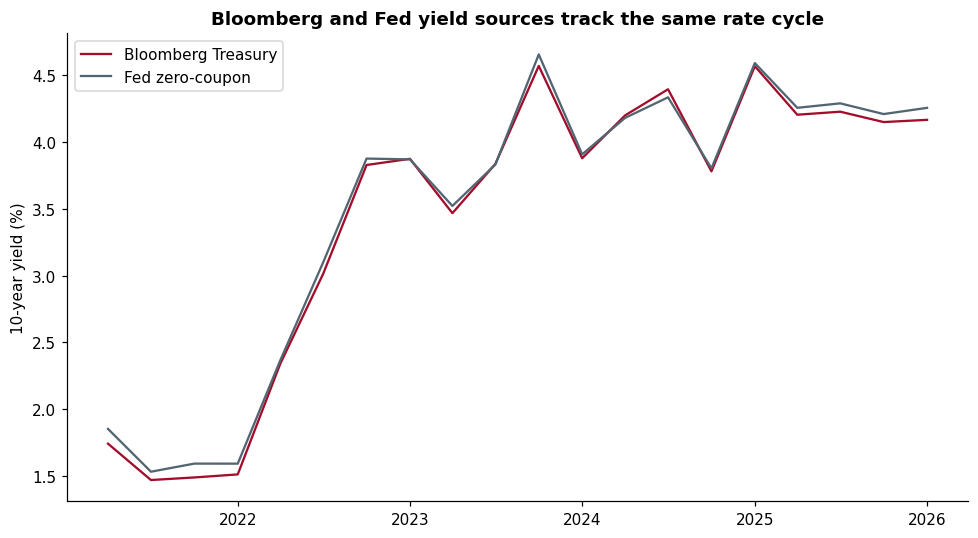

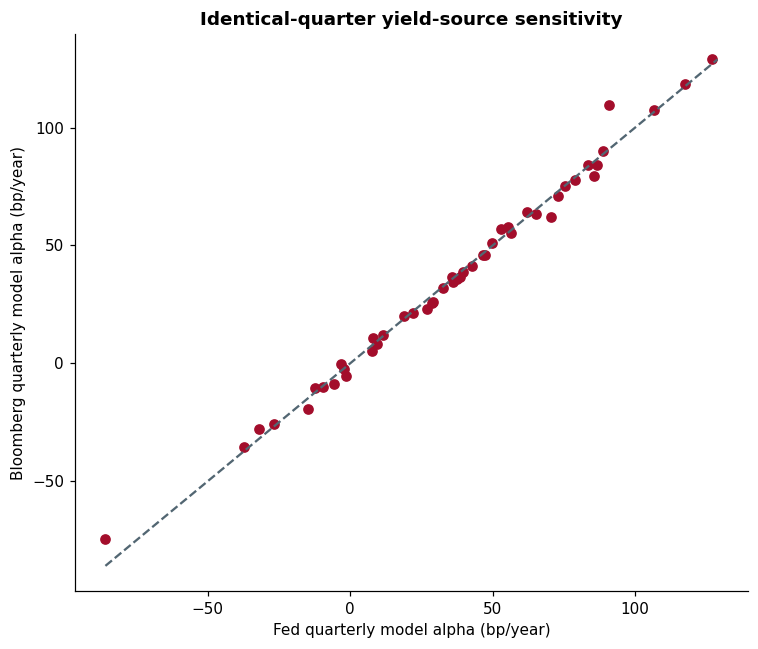

In [14]:
from pathlib import Path
import pandas as pd, numpy as np, json
from scipy.stats import spearmanr
import statsmodels.api as sm
# ROOT and OUT come from the notebook configuration.
T=OUT/'tables'
b=pd.read_csv(ROOT/'bbg_rates/bbg_rates_quarterly_wide.csv'); b['q']=pd.to_datetime(b.date).dt.to_period('Q');b=b.set_index('q').sort_index()
f=pd.read_csv(T/'collected_fed_zero_curve.csv');f['q']=pd.to_datetime(f.month_end).dt.to_period('Q');f=f.groupby('q').last()
z=pd.DataFrame(index=pd.period_range('2019Q1','2026Q2',freq='Q'))
for dest,src in [('bbg_2y','USGG2YR'),('bbg_10y','USGG10YR')]:z[dest]=b[src]
for dest,src in [('fed_2y','zc_2y'),('fed_10y','zc_10y')]:z[dest]=f[src]
for source in ['bbg','fed']:
 z[source+'_level']=-z[source+'_10y'].diff()/100
 z[source+'_curve']=-(z[source+'_10y']-z[source+'_2y']).diff()/100
m=pd.read_csv(T/'monthly_factors.csv');m['q']=pd.to_datetime(m.month_end).dt.to_period('Q')
for col in ['credit_shock','mbs_excess']:z[col]=m.groupby('q')[col].agg(lambda x:x.sum() if len(x)==3 and x.notna().all() else np.nan)
r=pd.read_csv(T/'fund_month_returns.csv');r=r[r.eligible_returns.eq(True)].copy();r['q']=pd.to_datetime(r.month_end).dt.to_period('Q')
rows=[]
for (sid,q),g in r.groupby(['series_id','q']):
 if len(g)==3:rows.append(dict(series_id=sid,q=q,active_return=(1+g.return_decimal).prod()-(1+g.benchmark_return).prod()))
rq=pd.DataFrame(rows).merge(z,left_on='q',right_index=True)
score=pd.read_csv(T/'fund_scorecards.csv'); ids=score.loc[score.n.eq(60),'series_id']
fits=[]
for sid,g in rq[rq.series_id.isin(ids)&rq.q.between(pd.Period('2021Q1'),pd.Period('2025Q4'))].groupby('series_id'):
 g=g.dropna();assert len(g)==20
 for src in ['bbg','fed']:
  cols=[src+'_level',src+'_curve','credit_shock','mbs_excess']; mod=sm.OLS(g.active_return,sm.add_constant(g[cols])).fit(cov_type='HAC',cov_kwds={'maxlags':1,'use_correction':True})
  fits.append(dict(series_id=sid,source=src,n_quarters=len(g),alpha_ann=4*mod.params['const'],level_beta=mod.params[cols[0]],curve_beta=mod.params[cols[1]],r2=mod.rsquared))
fit=pd.DataFrame(fits).merge(score[['series_id','fund_name']],on='series_id');fit.to_csv(T/'bbg_quarterly_model_comparison.csv',index=False)
p=fit.pivot(index='series_id',columns='source',values='alpha_ann')
common=z.loc['2021Q1':'2025Q4']
summary={'quarters':20,'funds':len(p),'yield_change_correlation':common.bbg_level.corr(common.fed_level),'curve_change_correlation':common.bbg_curve.corr(common.fed_curve),'alpha_rank_spearman':spearmanr(p.bbg,p.fed).statistic,'alpha_sign_agreement':float((np.sign(p.bbg)==np.sign(p.fed)).mean()),'median_absolute_alpha_difference_bp':float((p.bbg-p.fed).abs().median()*10000),'vanguard_core':fit[fit.series_id.eq('S000053068')].to_dict('records')}
z.reset_index(names='quarter').to_csv(T/'bbg_quarterly_yield_comparison.csv',index=False)
(T/'bbg_comparison_summary.json').write_text(json.dumps(summary,indent=2))
display(pd.DataFrame([summary]).drop(columns='vanguard_core'))
display(fit[fit.series_id.eq('S000053068')])
fig,ax=plt.subplots(figsize=(9,5))
matched=z.loc['2021Q1':'2025Q4']
ax.plot(matched.index.to_timestamp(how='end'),matched.bbg_10y,label='Bloomberg Treasury',color='#A30D2B')
ax.plot(matched.index.to_timestamp(how='end'),matched.fed_10y,label='Fed zero-coupon',color='#526672')
ax.set(ylabel='10-year yield (%)',title='Bloomberg and Fed yield sources track the same rate cycle')
ax.grid(False);ax.legend();fig.tight_layout()
fig.savefig(OUT/'charts'/'bbg_quarterly_yields.png',dpi=180)
plt.show()
fig,ax=plt.subplots(figsize=(7,6))
ax.scatter(p.fed*10000,p.bbg*10000,color='#A30D2B')
lo=min(p.min())*10000;hi=max(p.max())*10000
ax.plot([lo,hi],[lo,hi],color='#526672',linestyle='--')
ax.set(xlabel='Fed quarterly model alpha (bp/year)',ylabel='Bloomberg quarterly model alpha (bp/year)',title='Identical-quarter yield-source sensitivity')
ax.grid(False);fig.tight_layout();fig.savefig(OUT/'charts'/'bbg_alpha_comparison.png',dpi=180);plt.show()


## 14. Sponsor analysis and final presentation evidence

### Comparable histories and two layers
We compare active holdings with the benchmark, then estimate return sensitivities to rates, curve, credit and mortgages. Common 2021–2025 results support peer comparisons and repeatability tests. The current update extends available-history exhibits into 2026. Each Vanguard case uses an identical calendar window for its peers.

### Honest model selection
All Vanguard observations are held out of training and model choice. OLS is the linear baseline. Elastic net, random forest and boosting receive the same features and rows. Hyperparameters are tuned using pooled MSE inside grouped folds. Fund-equal RMSE selects the model before evaluating Vanguard. The reported improvement over OLS and its confidence interval use pooled RMSE, not fund-equal RMSE. Realized shocks are explanatory inputs. Later-period validation is a stability diagnostic, not an untouched chronological test: model selection uses the broader competitor sample.

### COVID, fees and duration
Full/excluding-2020 regressions use the same funds and dates outside the removed year. Fees regressions report uncertainty and class mismatch. Duration charts remain explicitly marked as sign-normalized scenarios because the source sign convention is not independently verified. Their yield association is exploratory.

**Interpretation:** lower model error is not evidence of manager skill. A model residual may reflect omitted risks, selection, luck or data errors. Individual manager claims also require dated manager-tenure records.

Combined positioning and realized market inputs do not isolate incremental positioning value or establish causality or forecasting ability. Whole-fund and family holdouts share calendar periods. The gain interval resamples quarters conditional on the fitted comparison and does not correct for model selection. Use the final `sponsor/` results; Section 10 outputs remain exploratory.


In [15]:
# Sponsor-facing analysis. This cell reads the tables generated earlier in this notebook.
import json, zipfile
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import statsmodels.api as sm
T=OUT/'tables'; S=OUT/'sponsor'; S.mkdir(exist_ok=True)
def rd(n): return pd.read_csv(T/(n+'.csv'))
def put(d,n): d.to_csv(S/(n+'.csv'),index=False); return d
meta=rd('fund_scorecards'); names=meta.set_index('series_id').fund_name.to_dict()
vgids=meta.loc[meta.role.eq('VANGUARD'),'series_id'].tolist()
r=rd('fund_month_returns');r=r[r.eligible_returns].copy();r.month_end=pd.to_datetime(r.month_end)
f=rd('monthly_factors');f.month_end=pd.to_datetime(f.month_end)
p=rd('quarterly_position_chart_panel');p.quarter_end=pd.to_datetime(p.quarter_end);p.report_date=pd.to_datetime(p.report_date)
# Latest common month for the established 47 funds, not a presumed Q3 endpoint.
established=meta.loc[meta.n.eq(60),'series_id'];coverage=r[r.series_id.isin(established)].groupby('month_end').series_id.nunique()
end=coverage[coverage.eq(len(established))].index.max()
put(r.groupby('series_id').agg(first=('month_end','min'),last=('month_end','max'),months=('month_end','size')).reset_index(),'coverage')
# Each Vanguard fund is compared with competitors over exactly its own common dates.
cases=[];casewealth=[]
for sid in vgids:
 v=r[(r.series_id==sid)&(r.month_end<=end)].sort_values('month_end'); dates=v.month_end
 style=meta.set_index('series_id').loc[sid,'style']; peerids=meta.loc[meta['style'].eq(style)&meta.role.ne('VANGUARD'),'series_id']
 panel=r[r.series_id.isin(peerids)&r.month_end.isin(dates)];complete=panel.groupby('series_id').size();panel=panel[panel.series_id.isin(complete[complete.eq(len(dates))].index)]
 def metric(x):
  a=x.active_return;g=np.prod((1+x.return_decimal)/(1+x.benchmark_return))-1
  return pd.Series({'relative_wealth':g,'relative_ann':(1+g)**(12/len(x))-1,'tracking_error':a.std()*np.sqrt(12)})
 pm=panel.groupby('series_id').apply(metric,include_groups=False);vm=metric(v)
 cases.append(dict(series_id=sid,fund=names[sid],start=dates.min(),end=dates.max(),months=len(v),peers=len(pm),**vm.to_dict(),peer_relative_wealth_median=pm.relative_wealth.median(),peer_ann_median=pm.relative_ann.median(),percentile=(pm.relative_wealth<vm.relative_wealth).mean()*100))
 for fid,x in pd.concat([v,panel]).groupby('series_id'):
  x=x.sort_values('month_end');w=np.cumprod((1+x.return_decimal)/(1+x.benchmark_return))-1
  casewealth.extend(dict(case=sid,series_id=fid,date=d,wealth=z) for d,z in zip(x.month_end,w))
cases=put(pd.DataFrame(cases),'vanguard_comparable_windows');cw=put(pd.DataFrame(casewealth),'vanguard_relative_wealth')
# Quarterly peer bands: agency MBS remains separate from non-agency and ABS/CLO.
p=p[p.quarter_end.le(pd.Timestamp('2026-06-30'))].copy()
p['active_securitized']=p['active__Non-agency MBS / CMBS']+p['active__ABS / CLO']
metrics={'duration_scenario':'active_duration_scenario','credit_weight':'active__Corporate debt (ratings pending)','agency_mbs':'active__Agency MBS','securitized':'active_securitized'}
bands=[]
for st in ['Core','Core-Plus']:
 for metric,col in metrics.items():
  for q,x in p[(p['style']==st)&(p.role!='VANGUARD')].groupby('quarter_end'):
   vals=x[col].dropna(); vals=vals[vals.abs()<=10] if metric=='duration_scenario' else vals
   if len(vals)>=5:bands.append(dict(style=st,metric=metric,date=q,n=len(vals),p10=vals.quantile(.1),median=vals.median(),p90=vals.quantile(.9)))
bands=put(pd.DataFrame(bands),'position_bands');put(p[p.series_id.isin(vgids)],'vanguard_positions')
# Full and ex-2020 models on precisely matched funds and start/end dates.
cols=['rate_level','rate_curve','credit_shock','mbs_excess']; reg=r.merge(f,on='month_end').dropna(subset=cols)
common_start=pd.Timestamp('2019-09-30'); wanted=pd.date_range(common_start,end,freq='ME')
full=reg[reg.month_end.isin(wanted)]; counts=full.groupby('series_id').month_end.nunique();covidids=counts[counts.eq(len(wanted))].index
cr=[]; contrib=[]
for sid,x in full[full.series_id.isin(covidids)].groupby('series_id'):
 for label,xx in [('Including 2020',x),('Excluding 2020',x[x.month_end.dt.year.ne(2020)])]:
  xx=xx.sort_values('month_end');X=sm.add_constant(xx[cols]); m=sm.OLS(xx.active_return,X).fit()
  # Calendar-aware HAC from the main notebook does not bridge removed 2020.
  cov=calendar_hac(X.to_numpy(),m.resid.to_numpy(),xx.month_end,3);se=np.sqrt(cov[0,0]);cr.append(dict(series_id=sid,fund=names[sid],sample=label,n=len(xx),alpha_bp=m.params.iloc[0]*120000,lo_bp=(m.params.iloc[0]-1.96*se)*120000,hi_bp=(m.params.iloc[0]+1.96*se)*120000))
put(pd.DataFrame(cr),'covid_matched_alpha')
# Extended-window descriptive attribution; STAR gets descriptive comparisons, not an underpowered regression.
for sid,x in reg[reg.month_end.le(end)].groupby('series_id'):
 if len(x)<40:continue
 m=sm.OLS(x.active_return,sm.add_constant(x[cols])).fit()
 for c in cols:contrib.append(dict(series_id=sid,fund=names[sid],component=c,annual_bp=m.params[c]*x[c].mean()*120000,beta=m.params[c],n=len(x)))
 contrib.append(dict(series_id=sid,fund=names[sid],component='alpha',annual_bp=m.params['const']*120000,beta=m.params['const'],n=len(x)))
put(pd.DataFrame(contrib),'extended_attribution')
# Fees: association only. Cheapest-class expense is NOT the selected-class expense.
fee_rows=[]; fs=meta[meta.n.eq(60)].dropna(subset=['cheapest_class_fee_median']).copy();fs['fee_bp']=fs.cheapest_class_fee_median*10000
for outcome in ['annualized_relative_growth','alpha_ann']:
 for st in ['All','Core','Core-Plus']:
  d=fs if st=='All' else fs[fs['style']==st];X=pd.DataFrame({'fee_10bp':d.fee_bp/10})
  if st=='All':X['core_plus']=d['style'].eq('Core-Plus').astype(int)
  m=sm.OLS(d[outcome]*10000,sm.add_constant(X)).fit(cov_type='HC3');ci=m.conf_int().loc['fee_10bp']
  fee_rows.append(dict(outcome=outcome,style=st,n=len(d),slope_bp_per_10bp=m.params.fee_10bp,lo=ci.iloc[0],hi=ci.iloc[1],p=m.pvalues.fee_10bp))
put(pd.DataFrame(fee_rows),'fee_association');put(fs,'fee_scatter')
# Retrospective peer-duration scenario and subsequent yield moves. No tradability claim.
y=rd('collected_fed_zero_curve'); datecol=next(c for c in y if 'date' in c or 'month' in c); y[datecol]=pd.to_datetime(y[datecol]); y=y.set_index(datecol)
y10=next(c for c in y if c in ['zc_10y','SVENY10','10Y','10y','10YR','y10']); yr=y[y10].resample('QE').last()
dur=bands[bands.metric.eq('duration_scenario')].pivot(index='date',columns='style',values='median'); dur['yield10']=yr.reindex(dur.index); dur['next_yield_change_bp']=100*(yr.shift(-1)-yr).reindex(dur.index)
put(dur.reset_index(),'duration_yields');dt=[]
for st in ['Core','Core-Plus']:
 d=dur[[st,'next_yield_change_bp']].dropna();m=sm.OLS(d.next_yield_change_bp,sm.add_constant(d[st])).fit(cov_type='HAC',cov_kwds={'maxlags':1});dt.append(dict(style=st,n=len(d),slope=m.params[st],p=m.pvalues[st],r2=m.rsquared,lo=m.conf_int().loc[st].iloc[0],hi=m.conf_int().loc[st].iloc[1]))
put(pd.DataFrame(dt),'duration_lead_association')
# Identical inputs and splits for OLS, elastic net, forest and boosting. Vanguard excluded from every selection step.
a=rd('ml_fund_quarter_panel');a.quarter_end=pd.to_datetime(a.quarter_end);a=a[a.quarter_end.le(end)]
features=[c for c in a if c.startswith('active_') or c.startswith('shock_') or c=='mbs_x_mortgage']+['log_assets','core_plus']
train=a[~a.series_id.isin(vgids)].copy();testvg=a[a.series_id.isin(vgids)].copy()
features=[c for c in features if train[c].notna().sum()>=30]
assert not set(train.series_id)&set(testvg.series_id)
def estimator(k):
 model={'ols':LinearRegression(),'elastic_net':ElasticNet(max_iter=15000,alpha=.0003,l1_ratio=.1),'random_forest':RandomForestRegressor(n_estimators=120,max_depth=5,min_samples_leaf=10,random_state=20261114,n_jobs=1),'boosting':HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=7,min_samples_leaf=15,learning_rate=.06,early_stopping=False,random_state=20261114)}[k]
 return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler()),('model',model)])
def fit(k,tr):
 est=estimator(k); grid={'elastic_net':{'model__alpha':[.00003,.0003,.003]},'random_forest':{'model__max_depth':[3,5]},'boosting':{'model__l2_regularization':[.1,1.]}}.get(k)
 if grid and tr.series_id.nunique()>=3:
  est=GridSearchCV(est,grid,cv=GroupKFold(3),scoring='neg_mean_squared_error',n_jobs=1)
  with threadpool_limits(1):est.fit(tr[features],tr.target,groups=tr.series_id)
  return est.best_estimator_
 with threadpool_limits(1):est.fit(tr[features],tr.target)
 return est
preds=[];ks=['ols','elastic_net','random_forest','boosting']
def predict_save(k,tr,te,label,fold):
 m=fit(k,tr)
 with threadpool_limits(1):v=m.predict(te[features])
 z=te[['series_id','quarter_end','target']].copy();z['prediction']=v;z['model']=k;z['validation']=label;z['fold']=fold;preds.append(z);return m
for fold,(ii,jj) in enumerate(GroupKFold(5).split(train,groups=train.series_id)):
 for k in ks:predict_save(k,train.iloc[ii],train.iloc[jj],'competitor_fund',fold)
 print('Completed competitor fold',fold+1,flush=True)
def scores(z):
 return pd.Series({'rows':len(z),'funds':z.series_id.nunique(),'rmse_bp':np.sqrt(mean_squared_error(z.target,z.prediction))*10000,'fund_equal_rmse_bp':np.sqrt(z.assign(e=(z.target-z.prediction)**2).groupby('series_id').e.mean().mean())*10000,'r2':r2_score(z.target,z.prediction)})
cv=pd.concat(preds); sc=cv.groupby('model').apply(scores,include_groups=False); selected=sc.fund_equal_rmse_bp.idxmin()
# Further validations cannot change the selected model.
for fold,(ii,jj) in enumerate(GroupKFold(5).split(train,groups=train.manager)):
 for k in ['ols']+[selected] if selected!='ols' else ['ols']:predict_save(k,train.iloc[ii],train.iloc[jj],'competitor_family',fold)
for year in [2023,2024,2025,2026]:
 tr=train[train.quarter_end.dt.year<year];te=train[train.quarter_end.dt.year.eq(year)]
 if len(tr)<80 or len(te)<10:continue
 for k in ks:predict_save(k,tr,te,'later_period',year)
for k in ks:predict_save(k,train,testvg,'vanguard_held_out',0)
preds=pd.concat(preds,ignore_index=True);put(preds,'model_predictions');ms=put(preds.groupby(['validation','model']).apply(scores,include_groups=False).reset_index(),'model_scores')
vs=preds[preds.validation.eq('vanguard_held_out')].groupby(['series_id','model']).apply(lambda z:pd.Series({'quarters':len(z),'actual_mean_bp':z.target.mean()*10000,'explained_mean_bp':z.prediction.mean()*10000,'unexplained_mean_bp':(z.target-z.prediction).mean()*10000,'rmse_bp':np.sqrt(mean_squared_error(z.target,z.prediction))*10000}),include_groups=False).reset_index();put(vs,'vanguard_model_results')
# Paired uncertainty by calendar quarter, preserving common shocks and identical OOF rows.
cv=preds[preds.validation.eq('competitor_fund')];wide=cv.pivot(index=['series_id','quarter_end'],columns='model',values='prediction');truth=cv.drop_duplicates(['series_id','quarter_end']).set_index(['series_id','quarter_end']).target.reindex(wide.index)
rng=np.random.default_rng(20261114);quarter=wide.index.get_level_values('quarter_end');qs=quarter.unique();gain=[]
for k in ks:
 if k=='ols':continue
 draws=[]
 for _ in range(500):
  ix=np.concatenate([np.flatnonzero(quarter==q) for q in rng.choice(qs,len(qs),replace=True)])
  e0=np.mean((truth.iloc[ix]-wide.ols.iloc[ix])**2);e1=np.mean((truth.iloc[ix]-wide[k].iloc[ix])**2);draws.append(100*(1-np.sqrt(e1/e0)))
 gain.append(dict(model=k,rmse_reduction_pct=100*(1-sc.loc[k,'rmse_bp']/sc.loc['ols','rmse_bp']),lo=np.quantile(draws,.025),hi=np.quantile(draws,.975)))
put(pd.DataFrame(gain),'ml_gain_over_ols')
summary={'latest_common_month':str(end.date()),'selected_model':selected,'features':features,'competitor_rows':len(train),'vanguard_rows':len(testvg),'matched_covid_funds':len(covidids),'timing':'Retrospective report-date information assumption; beginning-quarter holdings explain next-quarter realized returns; no claim of tradability','duration':'Unverified sign-normalized scenario, exploratory only; not used in primary ML','fees':'Cheapest-class descriptive proxy; historical selected-class fees unavailable','naming':'Competitor names authorized for Vanguard audience only; use anonymize setting for external copies'}
(S/'summary.json').write_text(json.dumps(summary,indent=2));print(json.dumps(summary,indent=2));display(ms);display(cases)


Completed competitor fold 1


Completed competitor fold 2


Completed competitor fold 3


Completed competitor fold 4


Completed competitor fold 5


{
  "latest_common_month": "2026-05-31",
  "selected_model": "random_forest",
  "features": [
    "active_treasury",
    "active_agency_mbs",
    "active_non_agency_cmbs",
    "active_abs_clo",
    "active_corporate_unrated",
    "active_em",
    "active_cash",
    "shock_rate_level",
    "shock_rate_curve",
    "shock_credit_shock",
    "shock_mbs_excess",
    "active_treasury_x_credit",
    "active_agency_mbs_x_credit",
    "active_non_agency_cmbs_x_credit",
    "active_abs_clo_x_credit",
    "active_corporate_unrated_x_credit",
    "active_em_x_credit",
    "active_cash_x_credit",
    "mbs_x_mortgage",
    "log_assets",
    "core_plus"
  ],
  "competitor_rows": 1010,
  "vanguard_rows": 46,
  "matched_covid_funds": 46,
  "timing": "Retrospective report-date information assumption; beginning-quarter holdings explain next-quarter realized returns; no claim of tradability",
  "duration": "Unverified sign-normalized scenario, exploratory only; not used in primary ML",
  "fees": "Cheapest

,validation,model,rows,funds,rmse_bp,fund_equal_rmse_bp,r2
0,competitor_family,ols,1010.0,44.0,82.041816,87.420683,0.541250
1,competitor_family,random_forest,1010.0,44.0,83.058819,87.270767,0.529806
2,competitor_fund,boosting,1010.0,44.0,81.049762,85.796858,0.552277
3,competitor_fund,elastic_net,1010.0,44.0,81.738488,87.524451,0.544635
4,competitor_fund,ols,1010.0,44.0,82.806858,88.469609,0.532654
5,competitor_fund,random_forest,1010.0,44.0,80.635050,85.268854,0.556847
6,later_period,boosting,537.0,44.0,59.497122,65.846248,-0.305813
7,later_period,elastic_net,537.0,44.0,59.627953,65.667986,-0.311562
8,later_period,ols,537.0,44.0,62.823889,68.787407,-0.455924
9,later_period,random_forest,537.0,44.0,59.331453,65.372362,-0.298551


,series_id,fund,start,end,months,peers,relative_wealth,relative_ann,tracking_error,peer_relative_wealth_median,peer_ann_median,percentile
0,S000053068,Vanguard Core Bond Fund,2019-07-31,2026-05-31,83,10,0.047315,0.006706,0.004906,0.026965,0.003854,80.000000
1,S000073843,Vanguard Core-Plus Bond Fund,2021-10-31,2026-05-31,56,26,0.045945,0.009672,0.007895,0.013831,0.002948,92.307692
2,S000090502,Vanguard STAR Core-Plus Bond Fund,2025-03-31,2026-05-31,15,26,0.016494,0.013174,0.007181,0.002761,0.002208,100.000000


## 15. Presentation chart pack and complete export

This section exports the final charts, a step-by-step reading guide, checks and the updated results ZIP. The sponsor/ directory is authoritative for the revised deck.

In [16]:
# Presentation data and charts from the sponsor revision.
import matplotlib.pyplot as plt
import shutil
SP=OUT/'sponsor'; (SP/'charts').mkdir(exist_ok=True)
# Every fund with a complete event window participates, including younger Vanguard funds.
stress=[]
for event,start,stop,n in [('COVID sell-off','2020-03-01','2020-03-31',1),('COVID recovery','2020-04-01','2020-12-31',9),('2022 rates shock','2022-01-01','2022-12-31',12),('March 2023','2023-03-01','2023-03-31',1)]:
 for sid,x in r[r.month_end.between(start,stop)].groupby('series_id'):
  if len(x)==n:stress.append(dict(event=event,series_id=sid,months=n,cumulative_relative_wealth=np.prod((1+x.return_decimal)/(1+x.benchmark_return))-1))
put(pd.DataFrame(stress),'stress_all_available')
# Reproducible, presentation-ready scientific figures with exact chart data alongside them.
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
def savefig(fig,name):
 fig.tight_layout();fig.savefig(SP/'charts'/f'{name}.png',dpi=180);fig.savefig(SP/'charts'/f'{name}.svg');plt.close(fig)
vgcore='S000053068'
for metric,col in metrics.items():
 b=bands[(bands['style']=='Core')&(bands.metric==metric)];v=p[p.series_id.eq(vgcore)]
 fig,ax=plt.subplots(figsize=(11,4.6));ax.fill_between(pd.to_datetime(b.date),b.p10,b.p90,color='#DCE3E7',label='Core peers: 10th–90th percentile');ax.plot(pd.to_datetime(b.date),b['median'],color='#53646E',label='Core peer median');ax.plot(v.quarter_end,v[col],color='#A30D2B',label='Vanguard Core');ax.axhline(0,color='#AAAAAA',lw=.7);ax.set_ylabel('Years (sign-normalized scenario)' if metric=='duration_scenario' else 'Percentage points vs benchmark');ax.set_title(metric.replace('_',' ').capitalize());ax.legend(fontsize=9);savefig(fig,'position_'+metric)
z=cw[cw['case'].eq(vgcore)];bb=z[z.series_id.ne(vgcore)].groupby('date').wealth.agg(p10=lambda x:x.quantile(.1),median='median',p90=lambda x:x.quantile(.9));v=z[z.series_id.eq(vgcore)]
fig,ax=plt.subplots(figsize=(11,4.6));ax.fill_between(pd.to_datetime(bb.index),100*bb.p10,100*bb.p90,color='#DCE3E7',label='Core peers 10th–90th');ax.plot(pd.to_datetime(bb.index),100*bb['median'],color='#53646E',label='Core median');ax.plot(pd.to_datetime(v.date),100*v.wealth,color='#A30D2B',label='Vanguard Core');
for date,label in [('2020-03-31','COVID'),('2022-01-31','2022'),('2023-03-31','Bank stress')]:ax.axvline(pd.Timestamp(date),color='#999999',lw=.8,ls=':')
ax.set_ylabel('Cumulative relative wealth (%)');ax.legend(fontsize=9);savefig(fig,'relative_wealth')
fig,ax=plt.subplots(figsize=(10,4.5));x=ms[ms.validation.eq('competitor_fund')];ax.bar(x.model,x.fund_equal_rmse_bp,color=['#A30D2B','#AAB4BA','#53646E','#AAB4BA']);ax.set_ylabel('Fund-equal quarterly RMSE (bp)');savefig(fig,'model_comparison')
fig,ax=plt.subplots(figsize=(10,4.5));ax.scatter(fs.fee_bp,fs.alpha_ann*10000,color='#53646E');ax.set_xlabel('Cheapest-class fee proxy (bp/year)');ax.set_ylabel('Annual factor alpha (bp), 2021–2025');savefig(fig,'fees')
# Inference and reconciliation checks.
assert set(testvg.series_id)==set(vgids)
assert not set(train.series_id).intersection(vgids)
assert all(preds[preds.validation.eq('competitor_fund')].groupby('model').size()==len(train))
assert len(pd.DataFrame(cr).groupby('series_id').size().unique())==1
assert pd.DataFrame(cr).groupby('series_id').size().iloc[0]==2
assert (a.position_date.astype(str)<a.quarter_end.astype(str)).all()
# Override prior exploratory ML tables for presentation selection. Keep original tables for audit only.
(SP/'README.md').write_text('''# Sponsor analysis, 15 November 2026

Use the sponsor/ tables and charts for the revised presentation. Earlier tables/ml_* outputs are retained as exploratory work and do not use the final competitor-only selection protocol.

1. Review coverage and return-class audit. The primary universe contains 49 funds. A fixed 2021–2025 window gives 47 comparable histories. Vanguard Core-Plus and STAR remain in all available-history exhibits.
2. Compare each Vanguard fund with same-style peers over precisely the same months. May 2026 is the latest common monthly endpoint across the established universe. Holdings snapshots extend to June. September filing dates do not establish Q3 holdings or return coverage.
3. Match each fund's holdings with the nearest earlier benchmark report within 100 days. Keep agency MBS separate. Corporate weights are not verified investment-grade weights. Screen unresolved holdings.
4. Regress monthly net excess returns on rate-level, curve, credit-spread and mortgage factors. Coefficient times realized factor movement gives additive model contributions. Residual alpha also contains omitted risks and measurement error.
5. Show March 2020 and April–December recovery separately. Refit the same 46 funds over September 2019–May 2026 with and without 2020. Calendar-aware HAC respects the missing year.
6. Examine fees using a cheapest-class proxy, style controls and HC3 uncertainty. Wide confidence intervals and class mismatch prevent a conclusion that fees do not matter.
7. Hold all Vanguard funds out of model selection. Compare OLS, elastic net, random forest and boosting on identical inputs. Tune inside whole-fund folds. Select using fund-equal RMSE, then check family, later-period and Vanguard holdouts. These use realized market shocks and explain outcomes retrospectively.
8. Treat report-date positions as observable for the explanatory study. This does not establish a feasible trading signal. Duration signs remain a normalized scenario, so the exploratory lead-yield association cannot support a trading recommendation.
9. Evaluate fund-level evidence of repeatability with multiple-testing and block-bootstrap checks. Individual manager tenure data are absent. Positive residuals alone do not establish skill.

Charts have PNG and SVG versions. All displayed numbers come from CSV tables. Competitor names are intended for the Vanguard audience only.
''')
# Regenerate the complete bundle after all sections have run.
archive=ROOT/'capstone_results_with_bloomberg.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
 for fp in sorted(OUT.rglob('*')):
  if fp.is_file():z.write(fp,fp.relative_to(ROOT))
print('Sponsor checks passed. Updated results bundle:',archive)


Sponsor checks passed. Updated results bundle: ./capstone_results_with_bloomberg.zip


## 16. Exact presentation data

This final cell exports the annual win counts, matched peer bands, stress comparisons and ranking profiles used in the deck into sponsor/presentation_data.json. Every chart is traceable to the underlying CSVs. It refreshes the ZIP after the export.

In [17]:
from pathlib import Path
import pandas as pd,numpy as np,json
T=OUT/'tables';S=OUT/'sponsor'
def rd(n):return pd.read_csv(T/(n+'.csv'))
def records(x):return json.loads(x.to_json(orient='records',date_format='iso'))
d={p.stem:records(pd.read_csv(p)) for p in S.glob('*.csv')};d['summary']=json.loads((S/'summary.json').read_text())
for n in ['fund_scorecards','stress_performance','annual_performance','peer_credit_relationship','factor_loadings','bbg_quarterly_yield_comparison','bbg_quarterly_model_comparison']:d[n]=records(rd(n))
m=rd('fund_scorecards');r=rd('fund_month_returns');r=r[r.eligible_returns].copy();r.month_end=pd.to_datetime(r.month_end);r=r[r.month_end.le('2026-05-31')];r=r.merge(m[['series_id','style','role','fund_name']],on='series_id',suffixes=('','_meta')) if 'role' not in r else r
# Identical complete year or Jan-May YTD coverage for every fund included in that year.
r['year']=r.month_end.dt.year; annual=[]
for (sid,yr),x in r.groupby(['series_id','year']):
 n=5 if yr==2026 else 12
 if len(x)!=n:continue
 annual.append(dict(series_id=sid,year=yr,active=100*(np.prod(1+x.return_decimal)-np.prod(1+x.benchmark_return))))
a=pd.DataFrame(annual).merge(m[['series_id','style','role']]);d['year_summary']=records(a.groupby('year').agg(n=('active','size'),beat=('active',lambda x:(x>0).sum()),median=('active','median')).reset_index());d['year_vanguard']=records(a[a.role.eq('VANGUARD')])
# Current comparable holdings snapshot, nearest earlier benchmark already applied.
p=pd.read_csv(S/'vanguard_positions.csv');p=p[p.position_eligible];d['latest_vanguard']=records(p.sort_values('report_date').groupby('series_id').tail(1))
# Relative-wealth band for Core, exact same dates across the 10 available peers.
cw=pd.read_csv(S/'vanguard_relative_wealth.csv');z=cw[cw['case'].eq('S000053068')];pe=z[z.series_id.ne('S000053068')];band=pe.groupby('date').wealth.agg(p10=lambda x:x.quantile(.1),median='median',p90=lambda x:x.quantile(.9)).reset_index();vg=z[z.series_id.eq('S000053068')][['date','wealth']];d['wealth_band']=records(band.merge(vg,on='date'))
# Matched COVID comparison descriptive distribution.
c=pd.read_csv(S/'covid_matched_alpha.csv');d['covid_summary']=records(c.groupby('sample').agg(n=('series_id','size'),median=('alpha_bp','median'),positive=('alpha_bp',lambda x:(x>0).sum())).reset_index());d['covid_vanguard']=records(c[c.series_id.eq('S000053068')])
# Stress episode summaries by style, with each Vanguard fund when available.
st=pd.read_csv(S/'stress_all_available.csv').merge(m[['series_id','style','role','fund_name']]);d['stress_summary']=records(st[st.role.ne('VANGUARD')].groupby(['event','style']).cumulative_relative_wealth.agg(n='size',median='median').reset_index());d['stress_vanguard']=records(st[st.role.eq('VANGUARD')])
# Common 2021-25 ranking movements, with risk exposures.
co=m[m.n.eq(60)].copy();co['raw_rank']=co.annualized_relative_growth.rank(ascending=False,method='min');co['alpha_rank']=co.alpha_ann.rank(ascending=False,method='min');z=pd.concat([co.nlargest(3,'annualized_relative_growth'),co.nsmallest(3,'annualized_relative_growth')]);fl=rd('factor_loadings');b=fl[(fl['sample']=='common')&(fl.model=='main')].pivot(index='series_id',columns='factor',values='beta');d['rank_profiles']=records(z.merge(b,on='series_id'))
# Equal-window four-factor contributions for Vanguard Core vs Core competitor median.
c=rd('case_annualized_model_contributions_bp');d['case_contributions']=records(c)
(S/'presentation_data.json').write_text(json.dumps(d,indent=2))
print('Year',d['year_summary']);print('COVID',d['covid_summary']);print('stress',d['stress_summary']);print('contrib',c.columns.tolist()); print('rank',z[['fund_name','raw_rank','alpha_rank']].to_string(index=False))

with zipfile.ZipFile(ROOT/'capstone_results_with_bloomberg.zip','w',zipfile.ZIP_DEFLATED) as z:
 for fp in sorted(OUT.rglob('*')):
  if fp.is_file():z.write(fp,fp.relative_to(ROOT))


Year [{'year': 2020, 'n': 46, 'beat': 38, 'median': 1.7263412432}, {'year': 2021, 'n': 47, 'beat': 38, 'median': 0.6662162045}, {'year': 2022, 'n': 48, 'beat': 23, 'median': -0.0613151532}, {'year': 2023, 'n': 48, 'beat': 42, 'median': 0.8560301415}, {'year': 2024, 'n': 48, 'beat': 40, 'median': 0.8083919825}, {'year': 2025, 'n': 48, 'beat': 31, 'median': 0.2501959658}, {'year': 2026, 'n': 49, 'beat': 27, 'median': 0.0504050845}]
COVID [{'sample': 'Excluding 2020', 'n': 46, 'median': 25.3960173758, 'positive': 32}, {'sample': 'Including 2020', 'n': 46, 'median': 45.1095976749, 'positive': 39}]
stress [{'event': '2022 rates shock', 'style': 'Core', 'n': 20, 'median': -0.001285812}, {'event': '2022 rates shock', 'style': 'Core-Plus', 'n': 26, 'median': -0.0023145665}, {'event': 'COVID recovery', 'style': 'Core', 'n': 19, 'median': 0.0359001862}, {'event': 'COVID recovery', 'style': 'Core-Plus', 'n': 26, 'median': 0.0527633579}, {'event': 'COVID sell-off', 'style': 'Core', 'n': 19, 'media